In [1]:
%pip install -U openai numpy pandas scipy matplotlib plotly
%pip install -U obspy segyio lasio ipywidgets
%pip install -U scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 4.2 MB/s  0:00:00m eta 0:00:01
  Attempting uninstall: openai
    Found existing installation: openai 3.46.0
    Uninstalling openai-3.46.0:
      Successfully uninstalled openai-3.46.0
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
from openai import OpenAI

# Initialize Gemma 4 client
client = OpenAI(
    base_url="http://172.28.34.1:8000/v1",
    api_key="token-not-needed"
)

MODEL = "google/gemma-4-26B-A4B-it"

# Test connection
response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {
            "role": "system",
            "content": "You are an expert geoscientist specializing in seismic interpretation and well log analysis."
        },
        {
            "role": "user",
            "content": "Explain the difference between seismic amplitude and RMS amplitude."
        }
    ],
    temperature=0.3
)

print(response.choices[0].message.content)

To understand the difference between **Seismic Amplitude** and **RMS (Root Mean Square) Amplitude**, it is best to view them through the lens of "instantaneous" vs. "statistical" measurements.

In seismic interpretation, we are essentially looking at variations in acoustic impedance. While both metrics describe the strength of the seismic signal, they serve very different purposes in reservoir characterization and facies identification.

---

### 1. Seismic Amplitude (Instantaneous Amplitude)
Seismic amplitude refers to the magnitude of the seismic trace at a **single, specific point in time (or depth)**. 

When we talk about "amplitude" in a general sense, we are usually referring to the **Instantaneous Amplitude** (also known as the *envelope*). This is calculated using the Hilbert Transform to extract the amplitude of the seismic wave without the oscillations of the positive and negative peaks.

*   **What it represents:** The strength of the reflection at a specific interface.
*   

In [3]:
import os
import gc
import segyio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# ==========================================
# SEG-Y FILE PATHS
# ==========================================

baseline_path = "/home/apgce_team_08/Baseline_Matched.sgy"

monitor_path = (
    "/data/epic20/APGCE/input_data/challenge3/"
    "volumes/Challenge3_Monitor_FilteredScaled_FullStack.sgy"
)

def load_seismic_geometry(filepath, survey_name):

    if not os.path.isfile(filepath):
        raise FileNotFoundError(filepath)

    print(f"\nLoading {survey_name}...")

    with segyio.open(
        filepath,
        "r",
        ignore_geometry=True
    ) as f:

        f.mmap()

        # ==================================
        # SEISMIC AMPLITUDES
        # ==================================

        seismic = segyio.tools.collect(f.trace[:])

        # ==================================
        # SAMPLING INFORMATION
        # ==================================

        samples = np.asarray(
            f.samples,
            dtype=np.float64
        )

        dt_ms = (
            f.bin[segyio.BinField.Interval] / 1000.0
        )

        # ==================================
        # INLINE AND CROSSLINE
        # ==================================

        inline = np.asarray(
            f.attributes(
                segyio.TraceField.INLINE_3D
            )[:],
            dtype=np.int32
        )

        crossline = np.asarray(
            f.attributes(
                segyio.TraceField.CROSSLINE_3D
            )[:],
            dtype=np.int32
        )

        # ==================================
        # STANDARD CDP X/Y HEADERS
        # ==================================

        x_raw = np.asarray(
            f.attributes(
                segyio.TraceField.CDP_X
            )[:],
            dtype=np.float64
        )

        y_raw = np.asarray(
            f.attributes(
                segyio.TraceField.CDP_Y
            )[:],
            dtype=np.float64
        )

        scalar = np.asarray(
            f.attributes(
                segyio.TraceField.SourceGroupScalar
            )[:],
            dtype=np.int32
        )

        # ==================================
        # APPLY COORDINATE SCALAR
        # ==================================

        scale = np.ones(
            f.tracecount,
            dtype=np.float64
        )

        positive = scalar > 0
        negative = scalar < 0

        scale[positive] = scalar[positive]

        scale[negative] = (
            1.0 /
            np.abs(scalar[negative].astype(np.float64))
        )

        x = x_raw * scale
        y = y_raw * scale

        # ==================================
        # GEOMETRY DATAFRAME
        # ==================================

        geometry = pd.DataFrame({

            "Trace_Index": np.arange(
                f.tracecount,
                dtype=np.int64
            ),

            "Inline": inline,
            "Crossline": crossline,

            "X": x,
            "Y": y,

            "X_Raw": x_raw,
            "Y_Raw": y_raw,

            "Coordinate_Scalar": scalar
        })

    print(f"{survey_name} loaded successfully")
    print("Seismic shape:", seismic.shape)
    print("Trace count:", len(geometry))

    print(
        "Inline range:",
        inline.min(), "-", inline.max()
    )

    print(
        "Crossline range:",
        crossline.min(), "-", crossline.max()
    )

    print("Sampling interval:", dt_ms, "ms")

    if survey_name.lower() == "baseline":
        print("Baseline X range:", np.nanmin(x), np.nanmax(x))
        print("Baseline Y range:", np.nanmin(y), np.nanmax(y))
    else:
        print("Monitor X/Y headers read but not trusted.")

    return seismic, geometry, samples, dt_ms
    
print("\nCell 3 initialized successfully.")


Cell 3 initialized successfully.


In [4]:
# ==========================================
# LOAD BASELINE
# ==========================================

(
    baseline,
    baseline_geometry,
    baseline_samples,
    baseline_dt
) = load_seismic_geometry(
    baseline_path,
    "Baseline"
)

# ==========================================
# LOAD MONITOR
# ==========================================

(
    monitor,
    monitor_geometry,
    monitor_samples,
    monitor_dt
) = load_seismic_geometry(
    monitor_path,
    "Monitor"
)

print("\n====================================")
print("ORIGINAL SURVEY TRACE COUNTS")
print("====================================")

print("Baseline:", f"{baseline.shape[0]:,}")
print("Monitor :", f"{monitor.shape[0]:,}")
print(
    "Difference:",
    f"{abs(baseline.shape[0] - monitor.shape[0]):,}"
)

print("\nCell 4 initialized successfully.")


Loading Baseline...
Baseline loaded successfully
Seismic shape: (1240941, 1301)
Trace count: 1240941
Inline range: 344 - 1372
Crossline range: 1949 - 3196
Sampling interval: 2.0 ms
Baseline X range: 454088.0 478817.0
Baseline Y range: 564114.0 586543.0

Loading Monitor...
Monitor loaded successfully
Seismic shape: (1244028, 1301)
Trace count: 1244028
Inline range: 344 - 1372
Crossline range: 1946 - 3196
Sampling interval: 2.0 ms
Monitor X/Y headers read but not trusted.

ORIGINAL SURVEY TRACE COUNTS
Baseline: 1,240,941
Monitor : 1,244,028
Difference: 3,087

Cell 4 initialized successfully.


In [5]:
# ==========================================
# VALIDATE UNIQUE INLINE/CROSSLINE BINS
# ==========================================

keys = ["Inline", "Crossline"]

for name, geom in [
    ("Baseline", baseline_geometry),
    ("Monitor", monitor_geometry)
]:

    duplicates = geom.duplicated(keys).sum()

    print(f"{name} duplicate IL/XL bins: {duplicates:,}")

    if duplicates > 0:
        raise ValueError(
            f"{name} contains duplicate Inline/Crossline "
            "pairs. Resolve these before matching."
        )

# ==========================================
# VALIDATE SAMPLE AXES
# ==========================================

if baseline.shape[1] != monitor.shape[1]:
    raise ValueError(
        "Baseline and Monitor have different sample counts."
    )

if not np.isclose(baseline_dt, monitor_dt):
    raise ValueError(
        "Baseline and Monitor sampling intervals differ."
    )

if not np.allclose(
    baseline_samples,
    monitor_samples,
    atol=1e-4,
    rtol=0
):
    raise ValueError(
        "Baseline and Monitor sample time axes differ."
    )

# ==========================================
# SELECT BASELINE REFERENCE GEOMETRY
# ==========================================

baseline_reference = baseline_geometry[
    [
        "Inline",
        "Crossline",
        "Trace_Index",
        "X",
        "Y"
    ]
].copy()

monitor_reference = monitor_geometry[
    [
        "Inline",
        "Crossline",
        "Trace_Index"
    ]
].copy()

# ==========================================
# MATCH COMMON INLINE/CROSSLINE BINS
# ==========================================

matched_geometry = pd.merge(
    baseline_reference,
    monitor_reference,
    on=["Inline", "Crossline"],
    how="inner",
    suffixes=("_baseline", "_monitor"),
    validate="one_to_one",
    sort=False
)

# Retain original Baseline trace ordering
matched_geometry = (
    matched_geometry
    .sort_values("Trace_Index_baseline")
    .reset_index(drop=True)
)

# ==========================================
# VERIFY MATCHING
# ==========================================

n_baseline = len(baseline_geometry)
n_monitor = len(monitor_geometry)
n_matched = len(matched_geometry)

if n_matched == 0:
    raise ValueError(
        "No matching Inline/Crossline pairs found."
    )

print("\n====================================")
print("TRACE MATCHING SUMMARY")
print("====================================")

print("Original Baseline:", f"{n_baseline:,}")
print("Original Monitor :", f"{n_monitor:,}")
print("Matched traces  :", f"{n_matched:,}")

print(
    "Unmatched Baseline:",
    f"{n_baseline - n_matched:,}"
)

print(
    "Unmatched Monitor:",
    f"{n_monitor - n_matched:,}"
)

print(
    "Baseline matching coverage:",
    f"{100 * n_matched / n_baseline:.2f}%"
)

print(
    "Monitor matching coverage:",
    f"{100 * n_matched / n_monitor:.2f}%"
)

print("\nMatched geometry preview:")
display(matched_geometry.head())
print("\nCell 5 initialized successfully.")

Baseline duplicate IL/XL bins: 0
Monitor duplicate IL/XL bins: 0

TRACE MATCHING SUMMARY
Original Baseline: 1,240,941
Original Monitor : 1,244,028
Matched traces  : 1,240,941
Unmatched Baseline: 0
Unmatched Monitor: 3,087
Baseline matching coverage: 100.00%
Monitor matching coverage: 99.75%

Matched geometry preview:


,Inline,Crossline,Trace_Index_baseline,X,Y,Trace_Index_monitor
0,344,2016,0,462919.0,564114.0,3
1,344,2017,1,462912.0,564124.0,4
2,344,2018,2,462904.0,564134.0,5
3,344,2019,3,462897.0,564144.0,6
4,344,2020,4,462889.0,564154.0,7



Cell 5 initialized successfully.


In [6]:
# ==========================================
# GET MATCHED TRACE INDICES
# ==========================================

baseline_indices = matched_geometry[
    "Trace_Index_baseline"
].to_numpy(dtype=np.int64)

monitor_indices = matched_geometry[
    "Trace_Index_monitor"
].to_numpy(dtype=np.int64)

# ==========================================
# MATCH SEISMIC AMPLITUDES
# ==========================================

baseline_matched = np.ascontiguousarray(
    baseline[baseline_indices],
    dtype=np.float32
)

monitor_matched = np.ascontiguousarray(
    monitor[monitor_indices],
    dtype=np.float32
)

# ==========================================
# VALIDATION
# ==========================================

assert baseline_matched.shape == monitor_matched.shape

assert baseline_matched.shape[0] == len(matched_geometry)

print("\n====================================")
print("MATCHED SEISMIC VOLUMES")
print("====================================")

print("Baseline matched:", baseline_matched.shape)
print("Monitor matched :", monitor_matched.shape)

print(
    "Identical trace count:",
    baseline_matched.shape[0] ==
    monitor_matched.shape[0]
)

print("Matching completed successfully.")
print("\nCell 6 initialized successfully.")


MATCHED SEISMIC VOLUMES
Baseline matched: (1240941, 1301)
Monitor matched : (1240941, 1301)
Identical trace count: True
Matching completed successfully.

Cell 6 initialized successfully.


In [7]:
# ==========================================
# MONITOR GEOMETRY IN MATCHED TRACE ORDER
# ==========================================

monitor_geometry_matched = matched_geometry[
    [
        "Inline",
        "Crossline",
        "Trace_Index_monitor",
        "X",
        "Y"
    ]
].copy()

monitor_geometry_matched = (
    monitor_geometry_matched
    .rename(columns={
        "Trace_Index_monitor": "Trace_Index"
    })
)

# ==========================================
# UPDATE ORIGINAL-ORDER MONITOR GEOMETRY
# ==========================================

# Preserve original header values for reference
monitor_geometry["X_Original"] = monitor_geometry["X"]
monitor_geometry["Y_Original"] = monitor_geometry["Y"]

# Monitor header coordinates are not trusted
monitor_geometry["X"] = np.nan
monitor_geometry["Y"] = np.nan

# Assign Baseline coordinates to matched Monitor traces
monitor_geometry.loc[
    monitor_indices, "X"
] = matched_geometry["X"].to_numpy()

monitor_geometry.loc[
    monitor_indices, "Y"
] = matched_geometry["Y"].to_numpy()

# ==========================================
# VERIFICATION
# ==========================================

assert np.array_equal(
    monitor_geometry_matched["X"].to_numpy(),
    matched_geometry["X"].to_numpy()
)

assert np.array_equal(
    monitor_geometry_matched["Y"].to_numpy(),
    matched_geometry["Y"].to_numpy()
)

print("\n====================================")
print("MONITOR X/Y REPLACEMENT")
print("====================================")

print(
    "Matched Monitor traces with Baseline X/Y:",
    f"{len(monitor_geometry_matched):,}"
)

print(
    "Unmatched Monitor traces with unknown X/Y:",
    f"{len(monitor_geometry) - len(monitor_geometry_matched):,}"
)

print("\nMatched Monitor geometry preview:")
display(monitor_geometry_matched.head())
print("\nCell 7 initialized successfully.")


MONITOR X/Y REPLACEMENT
Matched Monitor traces with Baseline X/Y: 1,240,941
Unmatched Monitor traces with unknown X/Y: 3,087

Matched Monitor geometry preview:


,Inline,Crossline,Trace_Index,X,Y
0,344,2016,3,462919.0,564114.0
1,344,2017,4,462912.0,564124.0
2,344,2018,5,462904.0,564134.0
3,344,2019,6,462897.0,564144.0
4,344,2020,7,462889.0,564154.0



Cell 7 initialized successfully.


FINAL GEOMETRY QC
Matched traces: 1,240,941
Valid X/Y pairs: 1,240,941
Invalid X/Y pairs: 0
X range: 454088.0 - 478817.0
Y range: 564114.0 - 586543.0

SEISMIC AMPLITUDE QC
Baseline NaNs: 0
Monitor NaNs: 6,437,783


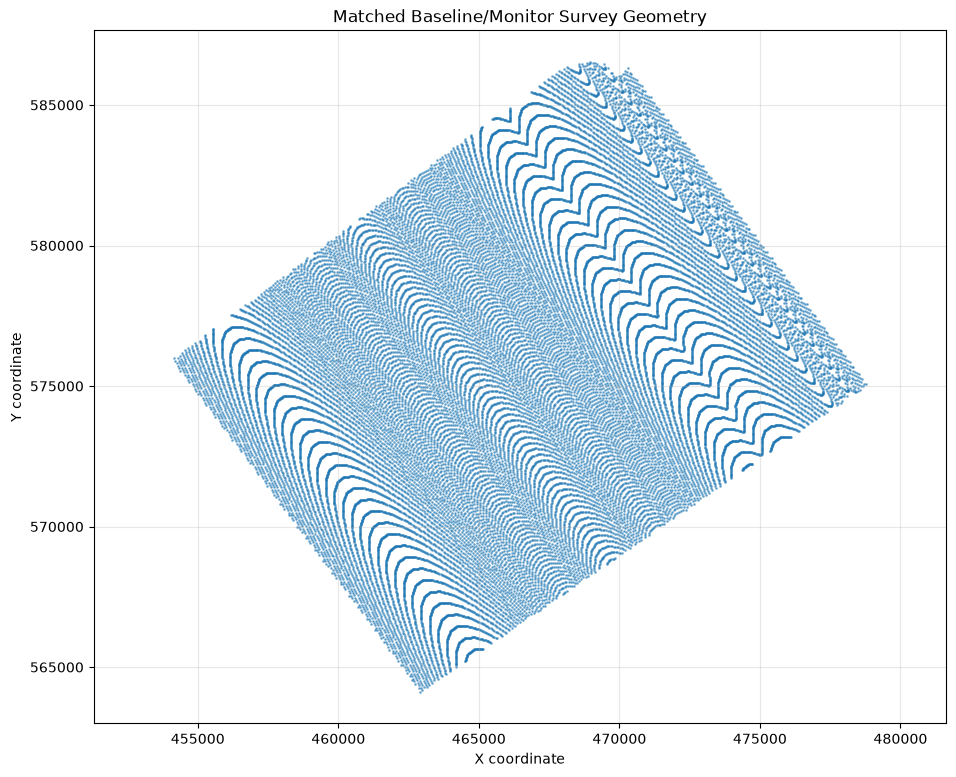


Geometry and trace matching QC completed.

Cell 8 initialized successfully.


In [8]:
# ==========================================
# 1. TRACE ALIGNMENT
# ==========================================

assert baseline_matched.shape == monitor_matched.shape

assert len(matched_geometry) == baseline_matched.shape[0]

assert np.array_equal(
    matched_geometry["Inline"].to_numpy(),
    baseline_geometry.iloc[
        baseline_indices
    ]["Inline"].to_numpy()
)

assert np.array_equal(
    matched_geometry["Crossline"].to_numpy(),
    monitor_geometry.iloc[
        monitor_indices
    ]["Crossline"].to_numpy()
)

# ==========================================
# 2. COORDINATE VALIDITY
# ==========================================

x = matched_geometry["X"].to_numpy()
y = matched_geometry["Y"].to_numpy()

valid_xy = (
    np.isfinite(x) &
    np.isfinite(y)
)

print("====================================")
print("FINAL GEOMETRY QC")
print("====================================")

print("Matched traces:", f"{len(matched_geometry):,}")

print(
    "Valid X/Y pairs:",
    f"{np.count_nonzero(valid_xy):,}"
)

print(
    "Invalid X/Y pairs:",
    f"{np.count_nonzero(~valid_xy):,}"
)

print("X range:", np.nanmin(x), "-", np.nanmax(x))
print("Y range:", np.nanmin(y), "-", np.nanmax(y))

# ==========================================
# 3. SEISMIC NaN QC
# ==========================================

print("\n====================================")
print("SEISMIC AMPLITUDE QC")
print("====================================")

print(
    "Baseline NaNs:",
    f"{np.isnan(baseline_matched).sum():,}"
)

print(
    "Monitor NaNs:",
    f"{np.isnan(monitor_matched).sum():,}"
)

# ==========================================
# 4. SURVEY GEOMETRY PLOT
# ==========================================

# Plot a subset to avoid rendering
# more than one million points

step = max(1, len(matched_geometry) // 30000)

fig, ax = plt.subplots(figsize=(11, 9))

ax.scatter(
    x[::step],
    y[::step],
    s=1,
    alpha=0.5
)

ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_title("Matched Baseline/Monitor Survey Geometry")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

plt.show()

print("\nGeometry and trace matching QC completed.")
print("\nCell 8 initialized successfully.")

In [9]:
if not np.isclose(baseline_dt, monitor_dt):
    raise ValueError("Baseline and monitor sampling intervals differ.")

if not np.allclose(baseline_samples, monitor_samples):
    raise ValueError("Baseline and monitor time axes differ.")

print("Time sampling is compatible.")
print("\nCell 9 initialized successfully.")

Time sampling is compatible.

Cell 9 initialized successfully.


Trace alignment: PASSED

GEOMETRY QC
Matched traces: 1,240,941
Valid X/Y pairs: 1,240,941
X range: 454088.0 - 478817.0
Y range: 564114.0 - 586543.0

AMPLITUDE QC
Baseline NaNs: 0
Monitor NaNs: 6,437,783

Calculating 4D difference...
4D difference shape: (1240941, 1301)
4D difference NaNs: 6,437,783

Writing 4D difference SEG-Y...
Written 100,000 / 1,240,941 traces
Written 200,000 / 1,240,941 traces
Written 300,000 / 1,240,941 traces
Written 400,000 / 1,240,941 traces
Written 500,000 / 1,240,941 traces
Written 600,000 / 1,240,941 traces
Written 700,000 / 1,240,941 traces
Written 800,000 / 1,240,941 traces
Written 900,000 / 1,240,941 traces
Written 1,000,000 / 1,240,941 traces
Written 1,100,000 / 1,240,941 traces
Written 1,200,000 / 1,240,941 traces

4D DIFFERENCE EXPORT COMPLETED
Output: /home/apgce_team_08/4D_difference.sgy

Verifying exported SEG-Y...
Exported trace count: 1240941
Samples per trace: 1301
SEG-Y sample format: 5
Trace 0 | IL=344 | XL=2016 | X=462919.00 | Y=564114.00
Tra

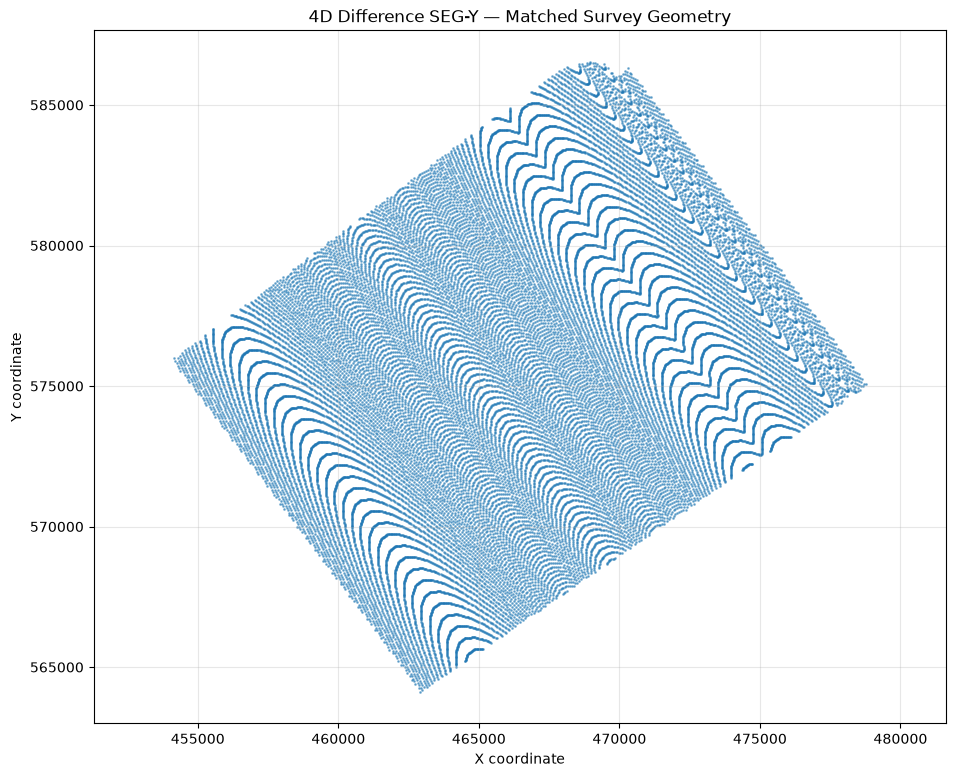


All processing completed.

Cell 10 initialized successfully.


In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import segyio

# ==========================================
# FILE PATHS
# ==========================================

baseline_path = "/home/apgce_team_08/Baseline_Matched.sgy"

output_path = "/home/apgce_team_08/4D_difference.sgy"

# ==========================================
# 1. TRACE ALIGNMENT QC
# ==========================================

assert baseline_matched.shape == monitor_matched.shape

assert len(matched_geometry) == baseline_matched.shape[0]

baseline_indices = matched_geometry[
    "Trace_Index_baseline"
].to_numpy(dtype=np.int64)

monitor_indices = matched_geometry[
    "Trace_Index_monitor"
].to_numpy(dtype=np.int64)

assert np.array_equal(
    matched_geometry["Inline"].to_numpy(),
    baseline_geometry.iloc[
        baseline_indices
    ]["Inline"].to_numpy()
)

assert np.array_equal(
    matched_geometry["Crossline"].to_numpy(),
    monitor_geometry.iloc[
        monitor_indices
    ]["Crossline"].to_numpy()
)

print("Trace alignment: PASSED")

# ==========================================
# 2. COORDINATE VALIDITY QC
# ==========================================

x = matched_geometry["X"].to_numpy(dtype=np.float64)
y = matched_geometry["Y"].to_numpy(dtype=np.float64)

valid_xy = np.isfinite(x) & np.isfinite(y)

if not np.all(valid_xy):
    raise ValueError(
        "Some matched traces have invalid X/Y coordinates."
    )

print("\n====================================")
print("GEOMETRY QC")
print("====================================")

print("Matched traces:", f"{len(matched_geometry):,}")
print("Valid X/Y pairs:", f"{valid_xy.sum():,}")

print("X range:", np.min(x), "-", np.max(x))
print("Y range:", np.min(y), "-", np.max(y))

# ==========================================
# 3. SEISMIC AMPLITUDE QC
# ==========================================

print("\n====================================")
print("AMPLITUDE QC")
print("====================================")

print("Baseline NaNs:", f"{np.isnan(baseline_matched).sum():,}")
print("Monitor NaNs:", f"{np.isnan(monitor_matched).sum():,}")

# ==========================================
# 4. CALCULATE 4D DIFFERENCE
# ==========================================

print("\nCalculating 4D difference...")

# Preserve NaNs; do not drop or interpolate traces.
difference_4d = (
    monitor_matched.astype(np.float32, copy=False)
    - baseline_matched.astype(np.float32, copy=False)
)

print("4D difference shape:", difference_4d.shape)
print("4D difference NaNs:", f"{np.isnan(difference_4d).sum():,}")

# ==========================================
# 5. EXPORT SEG-Y WITH BASELINE X/Y
# ==========================================

print("\nWriting 4D difference SEG-Y...")

with segyio.open(
    baseline_path,
    "r",
    ignore_geometry=True
) as src:

    spec = segyio.spec()

    spec.samples = src.samples
    spec.format = 5  # IEEE 32-bit floating point
    spec.tracecount = difference_4d.shape[0]

    with segyio.create(output_path, spec) as dst:

        # Copy binary header
        dst.bin = src.bin

        # Explicitly enforce IEEE float format
        dst.bin[segyio.BinField.Format] = 5

        # Copy textual header
        dst.text[0] = src.text[0]

        for i in range(difference_4d.shape[0]):

            original_baseline_index = int(
                baseline_indices[i]
            )

            # Copy original Baseline trace header
            header = dict(
                src.header[original_baseline_index]
            )

            # Matched Inline/Crossline
            header[segyio.TraceField.INLINE_3D] = int(
                matched_geometry.iloc[i]["Inline"]
            )

            header[segyio.TraceField.CROSSLINE_3D] = int(
                matched_geometry.iloc[i]["Crossline"]
            )

            # ----------------------------------
            # BASELINE X/Y COORDINATES
            # ----------------------------------

            # Retrieve original coordinate scalar
            scalar = int(
                header.get(
                    segyio.TraceField.SourceGroupScalar,
                    1
                )
            )

            if scalar > 0:
                x_raw = int(round(x[i] / scalar))
                y_raw = int(round(y[i] / scalar))

            elif scalar < 0:
                x_raw = int(round(x[i] * abs(scalar)))
                y_raw = int(round(y[i] * abs(scalar)))

            else:
                x_raw = int(round(x[i]))
                y_raw = int(round(y[i]))

            # Write X/Y to standard CDP coordinate headers
            header[segyio.TraceField.CDP_X] = x_raw
            header[segyio.TraceField.CDP_Y] = y_raw

            # Write updated trace header
            dst.header[i] = header

            # Write 4D difference amplitude
            dst.trace[i] = difference_4d[i]

            if (i + 1) % 100000 == 0:
                print(
                    f"Written {i + 1:,} / "
                    f"{difference_4d.shape[0]:,} traces"
                )

        dst.flush()

print("\n====================================")
print("4D DIFFERENCE EXPORT COMPLETED")
print("====================================")
print("Output:", output_path)

# ==========================================
# 6. VERIFY OUTPUT SEG-Y HEADERS
# ==========================================

print("\nVerifying exported SEG-Y...")

with segyio.open(
    output_path,
    "r",
    ignore_geometry=True
) as f:

    print("Exported trace count:", f.tracecount)
    print("Samples per trace:", len(f.samples))

    print(
        "SEG-Y sample format:",
        f.bin[segyio.BinField.Format]
    )

    check_indices = np.unique(
        np.linspace(
            0,
            f.tracecount - 1,
            min(5, f.tracecount),
            dtype=np.int64
        )
    )

    for i in check_indices:

        h = f.header[int(i)]

        scalar = int(
            h[segyio.TraceField.SourceGroupScalar]
        )

        if scalar > 0:
            factor = float(scalar)
        elif scalar < 0:
            factor = 1.0 / abs(scalar)
        else:
            factor = 1.0

        exported_x = (
            h[segyio.TraceField.CDP_X] * factor
        )

        exported_y = (
            h[segyio.TraceField.CDP_Y] * factor
        )

        print(
            f"Trace {i:,} | "
            f"IL={h[segyio.TraceField.INLINE_3D]} | "
            f"XL={h[segyio.TraceField.CROSSLINE_3D]} | "
            f"X={exported_x:.2f} | "
            f"Y={exported_y:.2f}"
        )

        if not np.isclose(exported_x, x[i], atol=0.01):
            raise ValueError(
                f"X coordinate mismatch at trace {i}"
            )

        if not np.isclose(exported_y, y[i], atol=0.01):
            raise ValueError(
                f"Y coordinate mismatch at trace {i}"
            )

    print("\nSampled coordinate verification: PASSED")

# ==========================================
# 7. SURVEY GEOMETRY PLOT
# ==========================================

step = max(1, len(matched_geometry) // 30000)

fig, ax = plt.subplots(figsize=(11, 9))

ax.scatter(
    x[::step],
    y[::step],
    s=1,
    alpha=0.5
)

ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_title("4D Difference SEG-Y — Matched Survey Geometry")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

plt.show()

print("\nAll processing completed.")
print("\nCell 10 initialized successfully.")

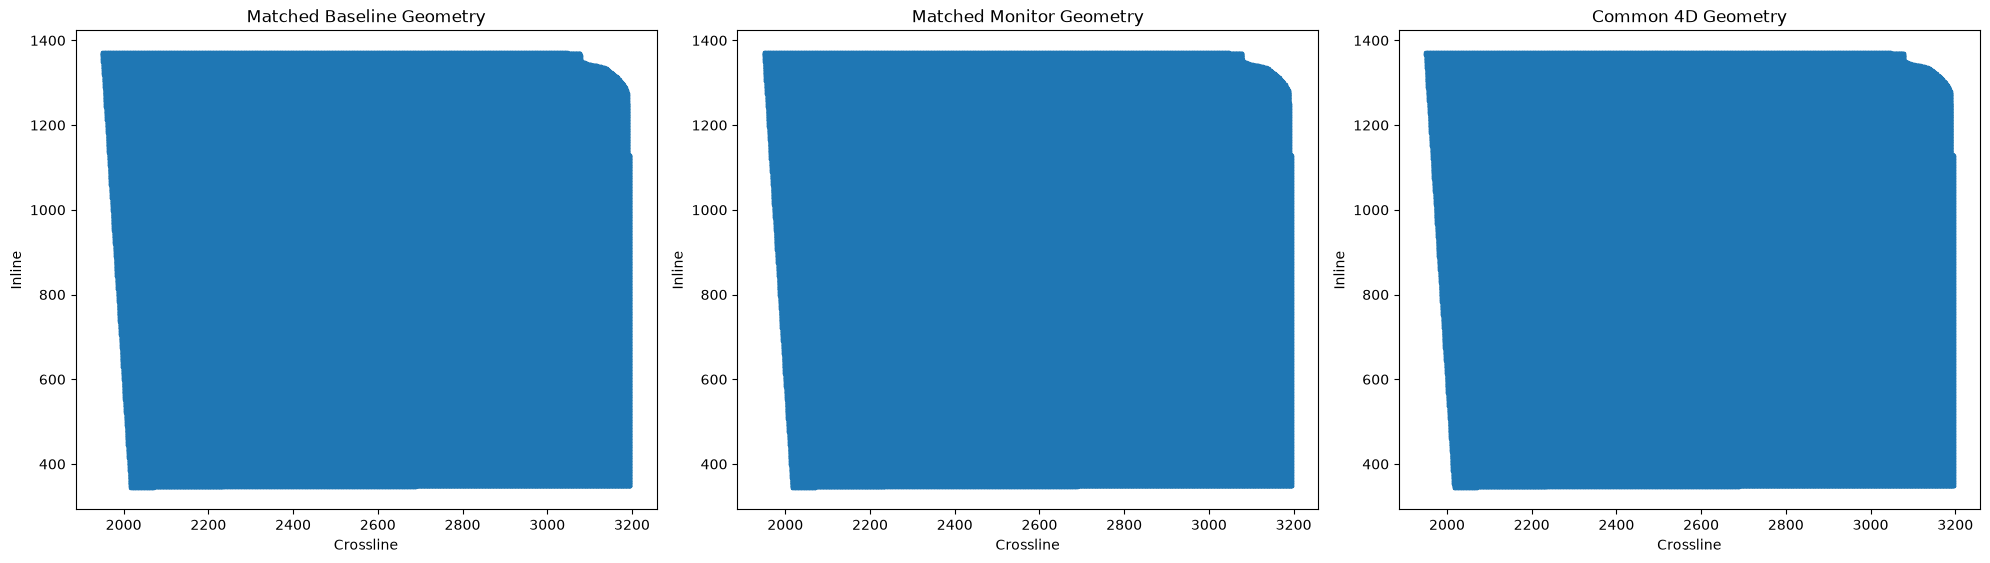


Cell 11 initialized successfully.


In [11]:
import matplotlib.pyplot as plt

# Extract inline and crossline
inline = matched_geometry["Inline"].values
crossline = matched_geometry["Crossline"].values

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Baseline
axes[0].scatter(
    crossline,
    inline,
    s=2
)
axes[0].set_title("Matched Baseline Geometry")

# Monitor
axes[1].scatter(
    crossline,
    inline,
    s=2
)
axes[1].set_title("Matched Monitor Geometry")

# Difference
axes[2].scatter(
    crossline,
    inline,
    s=2
)
axes[2].set_title("Common 4D Geometry")

for ax in axes:
    ax.set_xlabel("Crossline")
    ax.set_ylabel("Inline")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()
print("\nCell 11 initialized successfully.")

In [12]:
matched_geometry.to_csv(
    "/home/apgce_team_08/4D_Matched_Inline_Crossline.csv",
    index=False
)

print("Matched geometry CSV saved.")
print("\nCell 12 initialized successfully.")

Matched geometry CSV saved.

Cell 12 initialized successfully.


In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display

# ==========================================
# 1. VALIDATE EXISTING DATA
# ==========================================

volumes = {
    "Baseline": baseline_matched,
    "Monitor": monitor_matched,
    "4D Difference": difference_4d
}

geometry = matched_geometry.reset_index(drop=True)

inline_values = np.sort(geometry["Inline"].unique())
crossline_values = np.sort(geometry["Crossline"].unique())

samples_ms = np.asarray(baseline_samples, dtype=float)

n_traces = len(geometry)
n_samples = len(samples_ms)

for name, volume in volumes.items():
    if volume.shape != (n_traces, n_samples):
        raise ValueError(f"{name}: shape mismatch")

if geometry.duplicated(["Inline", "Crossline"]).any():
    raise ValueError("Duplicate Inline/Crossline positions found.")

if not np.all(np.diff(samples_ms) > 0):
    raise ValueError("Sample axis must be strictly increasing.")

# ==========================================
# 2. BUILD TRACE LOOKUP
# ==========================================

# Maps (Inline, Crossline) to the matched trace index.
# No seismic amplitudes are copied.

trace_lookup = pd.Series(
    np.arange(n_traces, dtype=np.int64),
    index=pd.MultiIndex.from_frame(
        geometry[["Inline", "Crossline"]]
    )
)

# ==========================================
# 3. REPORT GEOMETRY
# ==========================================

print("SEISMIC VIEWER READY")
print("=============================")
print("Traces:", f"{n_traces:,}")
print("Samples per trace:", n_samples)
print("Inline range:", inline_values.min(), "-", inline_values.max())
print("Crossline range:", crossline_values.min(), "-", crossline_values.max())
print("Time range (ms):", samples_ms.min(), "-", samples_ms.max())
print("Sample interval (ms):", baseline_dt)
print("NaN samples are preserved.")
print("\nCell 13 initialized successfully.")

SEISMIC VIEWER READY
Traces: 1,240,941
Samples per trace: 1301
Inline range: 344 - 1372
Crossline range: 1949 - 3196
Time range (ms): 0.0 - 2600.0
Sample interval (ms): 2.0
NaN samples are preserved.

Cell 13 initialized successfully.


In [14]:

def extract_inline(volume, inline_number):
    """Return [time samples, crosslines] for one inline."""

    idx = trace_lookup.loc[inline_number]

    section = np.full(
        (n_samples, len(crossline_values)),
        np.nan,
        dtype=np.float32
    )

    positions = np.searchsorted(
        crossline_values,
        idx.index.to_numpy()
    )

    section[:, positions] = volume[
        idx.to_numpy(dtype=np.int64), :
    ].T

    return section


def extract_crossline(volume, crossline_number):
    """Return [time samples, inlines] for one crossline."""

    idx = trace_lookup.xs(crossline_number, level="Crossline")

    section = np.full(
        (n_samples, len(inline_values)),
        np.nan,
        dtype=np.float32
    )

    positions = np.searchsorted(
        inline_values,
        idx.index.to_numpy()
    )

    section[:, positions] = volume[
        idx.to_numpy(dtype=np.int64), :
    ].T

    return section


def extract_time_slice(volume, time_ms):
    """Return [inlines, crosslines] for nearest time sample."""

    sample_idx = int(np.argmin(np.abs(samples_ms - time_ms)))

    slice_data = np.full(
        (len(inline_values), len(crossline_values)),
        np.nan,
        dtype=np.float32
    )

    inline_positions = np.searchsorted(
        inline_values,
        geometry["Inline"].to_numpy()
    )

    crossline_positions = np.searchsorted(
        crossline_values,
        geometry["Crossline"].to_numpy()
    )

    slice_data[inline_positions, crossline_positions] = (
        volume[:, sample_idx]
    )

    return slice_data, samples_ms[sample_idx]
    
print("\nCell 14 initialized successfully.")


Cell 14 initialized successfully.


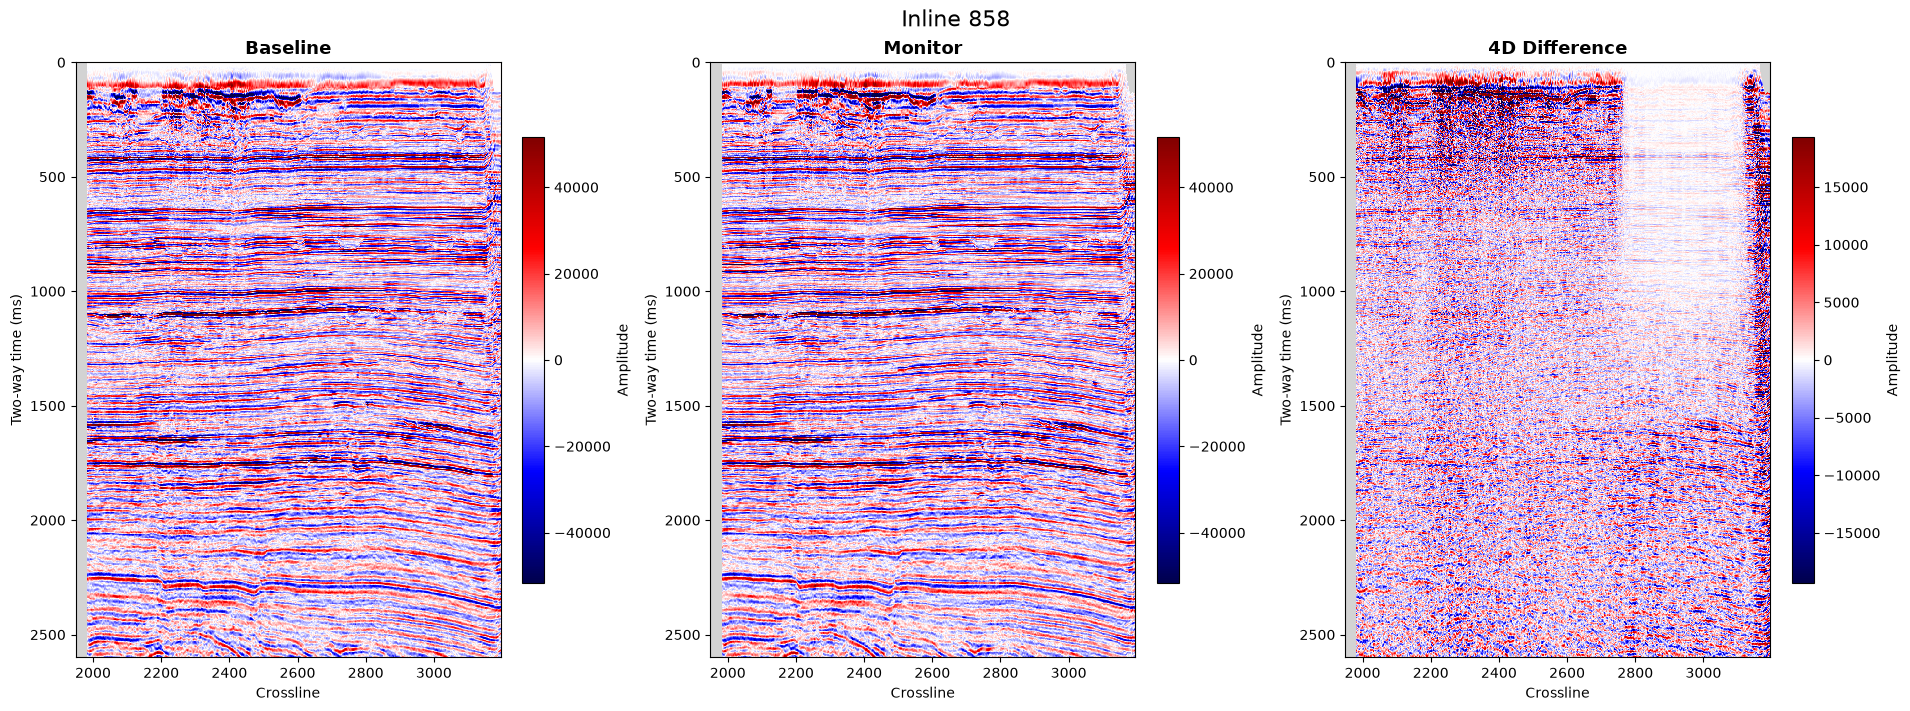


Cell 15 initialized successfully.


In [15]:

from matplotlib import colormaps

# ==========================================
# 1. DISPLAY SETTINGS
# ==========================================

cmap = colormaps["seismic"].copy()
cmap.set_bad(color="lightgray")

# Default section coordinates
default_inline = int(inline_values[len(inline_values) // 2])
default_crossline = int(crossline_values[len(crossline_values) // 2])
default_time = float(samples_ms[len(samples_ms) // 2])

section_type = widgets.Dropdown(
    options=["Inline", "Crossline", "Time Slice"],
    value="Inline",
    description="View:"
)

inline_selector = widgets.SelectionSlider(
    options=[int(v) for v in inline_values],
    value=default_inline,
    description="Inline:",
    continuous_update=False,
    layout=widgets.Layout(width="650px")
)

crossline_selector = widgets.SelectionSlider(
    options=[int(v) for v in crossline_values],
    value=default_crossline,
    description="Crossline:",
    continuous_update=False,
    layout=widgets.Layout(width="650px")
)

time_selector = widgets.SelectionSlider(
    options=[(f"{t:.2f}", float(t)) for t in samples_ms],
    value=default_time,
    description="Time (ms):",
    continuous_update=False,
    layout=widgets.Layout(width="650px")
)

clip_percentile = widgets.FloatSlider(
    value=99,
    min=90,
    max=99.9,
    step=0.1,
    description="Clip (%):",
    continuous_update=False,
    readout_format=".1f"
)

output = widgets.Output()


# ==========================================
# 2. PLOTTING FUNCTION
# ==========================================

def plot_seismic(view, inline, crossline, time_ms, clip):

    sections = {}

    for name, volume in volumes.items():

        if view == "Inline":
            sections[name] = extract_inline(volume, inline)

        elif view == "Crossline":
            sections[name] = extract_crossline(volume, crossline)

        else:
            sections[name], actual_time = extract_time_slice(
                volume, time_ms
            )

    # Shared amplitude clip for baseline and monitor
    reference = np.concatenate([
        np.abs(sections["Baseline"]).ravel(),
        np.abs(sections["Monitor"]).ravel()
    ])

    reference = reference[np.isfinite(reference)]

    reference_clip = (
        np.percentile(reference, clip)
        if reference.size else 1.0
    )

    # Independent clip for 4D Difference
    difference_values = np.abs(
        sections["4D Difference"]
    )

    difference_values = difference_values[
        np.isfinite(difference_values)
    ]

    difference_clip = (
        np.percentile(difference_values, clip)
        if difference_values.size else 1.0
    )

    reference_clip = max(float(reference_clip), 1e-12)
    difference_clip = max(float(difference_clip), 1e-12)

    # ======================================
    # 3. DRAW PANELS
    # ======================================

    fig, axes = plt.subplots(
        1, 3,
        figsize=(19, 7),
        constrained_layout=True
    )

    for ax, (name, data) in zip(axes, sections.items()):

        amplitude_clip = (
            difference_clip
            if name == "4D Difference"
            else reference_clip
        )

        if view == "Inline":
            extent = [
                crossline_values.min(),
                crossline_values.max(),
                samples_ms.max(),
                samples_ms.min()
            ]
            xlabel = "Crossline"

        elif view == "Crossline":
            extent = [
                inline_values.min(),
                inline_values.max(),
                samples_ms.max(),
                samples_ms.min()
            ]
            xlabel = "Inline"

        else:
            extent = [
                crossline_values.min(),
                crossline_values.max(),
                inline_values.max(),
                inline_values.min()
            ]
            xlabel = "Crossline"

        im = ax.imshow(
            data,
            cmap=cmap,
            vmin=-amplitude_clip,
            vmax=amplitude_clip,
            aspect="auto" if view != "Time Slice" else "equal",
            extent=extent,
            interpolation="nearest"
        )

        ax.set_title(name, fontsize=13, fontweight="bold")
        ax.set_xlabel(xlabel)

        if view == "Time Slice":
            ax.set_ylabel("Inline")
        else:
            ax.set_ylabel("Two-way time (ms)")

        fig.colorbar(
            im,
            ax=ax,
            shrink=0.75,
            label="Amplitude"
        )

    if view == "Inline":
        fig.suptitle(f"Inline {inline}", fontsize=16)

    elif view == "Crossline":
        fig.suptitle(f"Crossline {crossline}", fontsize=16)

    else:
        fig.suptitle(
            f"Time Slice at {actual_time:.2f} ms",
            fontsize=16
        )

    plt.show()


# ==========================================
# 4. INTERACTIVE UPDATE
# ==========================================

def update_view(change=None):

    with output:
        output.clear_output(wait=True)

        plot_seismic(
            view=section_type.value,
            inline=inline_selector.value,
            crossline=crossline_selector.value,
            time_ms=time_selector.value,
            clip=clip_percentile.value
        )


def update_controls(change=None):

    inline_selector.layout.display = (
        "" if section_type.value == "Inline" else "none"
    )

    crossline_selector.layout.display = (
        "" if section_type.value == "Crossline" else "none"
    )

    time_selector.layout.display = (
        "" if section_type.value == "Time Slice" else "none"
    )

    update_view()


section_type.observe(update_controls, names="value")

for control in [
    inline_selector,
    crossline_selector,
    time_selector,
    clip_percentile
]:
    control.observe(update_view, names="value")


# ==========================================
# 5. DISPLAY VIEWER
# ==========================================

display(
    widgets.VBox([
        section_type,
        inline_selector,
        crossline_selector,
        time_selector,
        clip_percentile,
        output
    ])
)

update_controls()
print("\nCell 15 initialized successfully.")

In [16]:
%pip install numba

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


GPU preconditioning 1,240,941 traces × 1,301 samples; GPU: b'NVIDIA H200 NVL MIG 2g.35gb'
GPU high-cut: 128/1,240,941
GPU high-cut: 25,728/1,240,941
GPU high-cut: 51,328/1,240,941
GPU high-cut: 76,928/1,240,941
GPU high-cut: 102,528/1,240,941
GPU high-cut: 128,128/1,240,941
GPU high-cut: 153,728/1,240,941
GPU high-cut: 179,328/1,240,941
GPU high-cut: 204,928/1,240,941
GPU high-cut: 230,528/1,240,941
GPU high-cut: 256,128/1,240,941
GPU high-cut: 281,728/1,240,941
GPU high-cut: 307,328/1,240,941
GPU high-cut: 332,928/1,240,941
GPU high-cut: 358,528/1,240,941
GPU high-cut: 384,128/1,240,941
GPU high-cut: 409,728/1,240,941
GPU high-cut: 435,328/1,240,941
GPU high-cut: 460,928/1,240,941
GPU high-cut: 486,528/1,240,941
GPU high-cut: 512,128/1,240,941
GPU high-cut: 537,728/1,240,941
GPU high-cut: 563,328/1,240,941
GPU high-cut: 588,928/1,240,941
GPU high-cut: 614,528/1,240,941
GPU high-cut: 640,128/1,240,941
GPU high-cut: 665,728/1,240,941
GPU high-cut: 691,328/1,240,941
GPU high-cut: 716,928

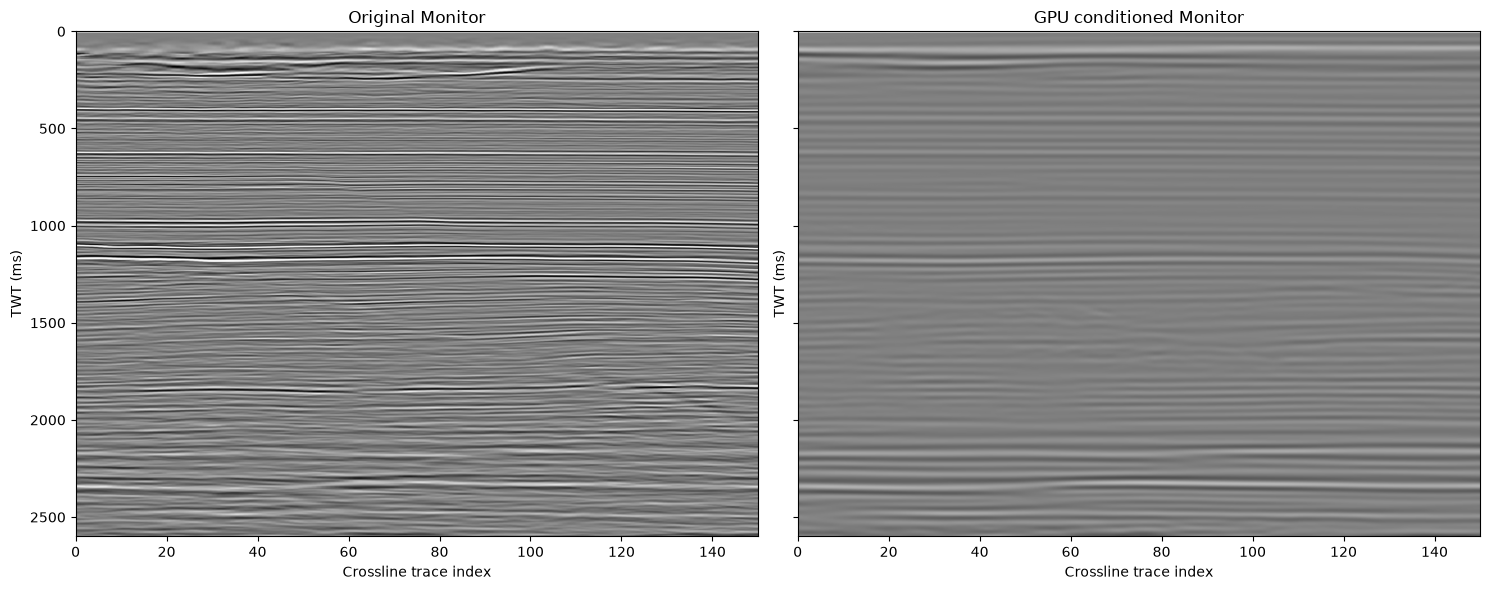

Cell 16A initialized successfully.


In [17]:
# CELL 16A — GPU MONITOR PRECONDITIONING (CuPy / CUDA)
# High-cut 24–30 Hz with cosine taper, followed by TWO dip-steered 2D passes:
#   (1) Crossline direction in constant-Inline sections
#   (2) Inline direction in constant-Crossline sections
# This is a Van Gogh-LIKE structure-oriented smoother, not a proprietary implementation.
# Original monitor_matched and baseline_matched are NEVER modified.
# EDIT FILTER PARAMETERS BELOW; set REBUILD_PRECONDITIONING=True after any input change.
from pathlib import Path
import gc, json, hashlib
import numpy as np
import pandas as pd
import cupy as cp
from cupyx.scipy.ndimage import gaussian_filter as gpu_gaussian_filter
from cupyx.scipy.ndimage import map_coordinates as gpu_map_coordinates
import matplotlib.pyplot as plt

ENABLE_HIGHCUT = True
HIGHCUT_PASS_HZ = 24.0       # EDIT: 100% pass below 24 Hz
HIGHCUT_STOP_HZ = 30.0       # EDIT: zero amplitude at >=30 Hz
ENABLE_VANGOGH = True
VG_PASS_DIRECTIONS = ('crossline', 'inline')  # EDIT: pass order; use tuple() to disable
VG_SPATIAL_RADIUS_TRACES = 15   # EDIT: +/- neighbouring traces
VG_TENSOR_SIGMA_X = 15.0        # EDIT: tensor smoothing along spatial direction, bins
VG_TENSOR_SIGMA_T = 15.0        # EDIT: tensor smoothing in time samples
VG_MAX_DIP_SAMPLES_PER_TRACE = 3.0
VG_MIN_COHERENCE = 0.20
VG_BLEND = 0.85                # EDIT: 0=no smoothing; 1=full dip-steered average
VG_ITERATIONS = 1             # EDIT: iterations PER directional pass
GPU_FFT_BATCH_TRACES = 128    # EDIT: reduce if CUDA out-of-memory
REBUILD_PRECONDITIONING = True  # EDIT: False only when you KNOW source data unchanged
OUTPUT_DIR_PRE = Path('/home/apgce_team_08/Autopick_Horizon/Preconditioning')
SHOW_PRECONDITIONING_QC = True
QC_MAX_CROSSLINES = 150

for name in ('monitor_matched','matched_geometry','monitor_samples'):
    if name not in globals(): raise NameError(f'Missing {name}; run seismic matching cells first')
if cp.cuda.runtime.getDeviceCount() < 1: raise RuntimeError('No CUDA GPU visible in this SLURM kernel')
source = monitor_matched
ntr, ns = source.shape
geom_pre = matched_geometry.reset_index(drop=True)
if len(geom_pre) != ntr: raise ValueError('Geometry and trace count differ')
if not {'Inline','Crossline'}.issubset(geom_pre.columns): raise ValueError('Inline/Crossline missing')
taxis_pre = np.asarray(monitor_samples, dtype=np.float64)
dt_ms_pre = float(np.median(np.diff(taxis_pre)))
if dt_ms_pre <= 0 or not np.allclose(np.diff(taxis_pre),dt_ms_pre,atol=1e-3):
    raise ValueError('Expected uniform increasing time samples in ms')
nyquist = 500.0 / dt_ms_pre
if ENABLE_HIGHCUT and not (0 < HIGHCUT_PASS_HZ < HIGHCUT_STOP_HZ <= nyquist):
    raise ValueError(f'Invalid high-cut corners; Nyquist is {nyquist:g} Hz')
if not (0 <= VG_BLEND <= 1 and 0 <= VG_MIN_COHERENCE <= 1): raise ValueError('Invalid VG parameters')
if VG_ITERATIONS < 1 or VG_SPATIAL_RADIUS_TRACES < 1: raise ValueError('VG iteration/radius must be >=1')
if any(d not in ('crossline','inline') for d in VG_PASS_DIRECTIONS): raise ValueError('Unknown VG direction')
OUTPUT_DIR_PRE.mkdir(parents=True,exist_ok=True)
output_path = OUTPUT_DIR_PRE/'Monitor_Picking_GPU_Highcut_VG2Pass.float32.dat'
metadata_path = output_path.with_suffix(output_path.suffix+'.json')
settings_pre = dict(shape=[int(ntr),int(ns)],dt_ms=dt_ms_pre,
    highcut=ENABLE_HIGHCUT,pass_hz=HIGHCUT_PASS_HZ,stop_hz=HIGHCUT_STOP_HZ,
    vg=ENABLE_VANGOGH,directions=list(VG_PASS_DIRECTIONS),radius=VG_SPATIAL_RADIUS_TRACES,
    tensor_x=VG_TENSOR_SIGMA_X,tensor_t=VG_TENSOR_SIGMA_T,max_dip=VG_MAX_DIP_SAMPLES_PER_TRACE,
    coherence=VG_MIN_COHERENCE,blend=VG_BLEND,iterations=VG_ITERATIONS,
    geometry_fingerprint=hashlib.sha256(np.asarray(geom_pre[['Inline','Crossline']],dtype=np.int64).tobytes()).hexdigest())
reuse_pre = False
if not REBUILD_PRECONDITIONING and output_path.exists() and metadata_path.exists():
    reuse_pre = (json.loads(metadata_path.read_text()) == settings_pre and
                 output_path.stat().st_size == ntr*ns*4)

# GPU FFT on one batch; CPU interpolation is limited to traces containing NaNs.
# Invalid samples are restored to NaN after filtering.
def gpu_highcut_batch(batch, frequency_response, pad):
    a = np.asarray(batch,dtype=np.float32).copy()
    mask = np.isfinite(a)
    good = mask.sum(axis=1)>=3
    out = np.full_like(a,np.nan)
    if not np.any(good): return out
    a=a[good]; valid=mask[good]
    t=np.arange(ns)
    for row in np.flatnonzero(~valid.all(axis=1)):
        ok=t[valid[row]]
        a[row,~valid[row]]=np.interp(t[~valid[row]],ok,a[row,ok])
    gpu=cp.asarray(a)
    padded=cp.pad(gpu,((0,0),(pad,pad)),mode='reflect')
    spectrum=cp.fft.rfft(padded,axis=1)
    spectrum*=frequency_response[None,:]
    filtered=cp.fft.irfft(spectrum,n=padded.shape[1],axis=1)[:,pad:pad+ns]
    result=cp.asnumpy(filtered.astype(cp.float32))
    result[~valid]=np.nan
    out[good]=result
    del gpu,padded,spectrum,filtered
    return out

# Section shape [spatial bin, time]. Work only on consecutive actual bin numbers.
# All dip estimation, spatial sampling and smoothing below run on the GPU.
def gpu_vg_section(section):
    if section.shape[0]<3: return np.asarray(section,dtype=np.float32)
    original=cp.asarray(np.asarray(section,dtype=np.float32))
    original_valid=cp.isfinite(original)
    if not bool(cp.any(original_valid)): return np.asarray(section,dtype=np.float32)
    work=original.copy()
    nr,nt=work.shape
    row=cp.arange(nr,dtype=cp.float32)[:,None]
    col=cp.arange(nt,dtype=cp.float32)[None,:]
    for iteration in range(VG_ITERATIONS):
        valid=cp.isfinite(work)
        filled=cp.where(valid,work,0.).astype(cp.float32)
        weight=gpu_gaussian_filter(valid.astype(cp.float32),(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')
        sm=gpu_gaussian_filter(filled,(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')/cp.maximum(weight,1e-5)
        gx,gt=cp.gradient(sm)
        jxx=gpu_gaussian_filter(gx*gx,(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')
        jtt=gpu_gaussian_filter(gt*gt,(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')
        jxt=gpu_gaussian_filter(gx*gt,(VG_TENSOR_SIGMA_X,VG_TENSOR_SIGMA_T),mode='nearest')
        eps=cp.maximum(cp.max(jtt+jxx)*1e-7,cp.float32(1e-10))
        slope=cp.clip(-jxt/(jtt+eps),-VG_MAX_DIP_SAMPLES_PER_TRACE,VG_MAX_DIP_SAMPLES_PER_TRACE)
        coherence=cp.clip(cp.sqrt((jxx-jtt)**2+4*jxt*jxt)/(jxx+jtt+eps),0,1)
        weighted=filled.copy(); total=valid.astype(cp.float32)
        for dx in range(-VG_SPATIAL_RADIUS_TRACES,VG_SPATIAL_RADIUS_TRACES+1):
            if dx==0: continue
            w=float(np.exp(-.5*(dx/max(1,VG_SPATIAL_RADIUS_TRACES/1.5))**2))
            coords=cp.stack(cp.broadcast_arrays(row+dx,col+dx*slope),axis=0)
            sample=gpu_map_coordinates(filled,coords,order=1,mode='constant',cval=0.)
            support=gpu_map_coordinates(valid.astype(cp.float32),coords,order=1,mode='constant',cval=0.)
            weighted+=w*sample
            total+=w*support
        steered=weighted/cp.maximum(total,1e-5)
        strength=VG_BLEND*cp.clip((coherence-VG_MIN_COHERENCE)/max(1e-6,1-VG_MIN_COHERENCE),0,1)
        work=cp.where(original_valid,((1-strength)*filled+strength*steered),cp.nan).astype(cp.float32)
    return cp.asnumpy(work)

def directional_gpu_pass(input_path,output_path,direction):
    input_mm=np.memmap(input_path,dtype='float32',mode='r',shape=(ntr,ns))
    output_mm=np.memmap(output_path,dtype='float32',mode='w+',shape=(ntr,ns))
    # Initialize output with input to preserve all short runs and missing bins.
    for start in range(0,ntr,8192): output_mm[start:start+8192]=input_mm[start:start+8192]
    group='Inline' if direction=='crossline' else 'Crossline'
    along='Crossline' if direction=='crossline' else 'Inline'
    groups=geom_pre.groupby(group,sort=False).indices
    for ii,(_,ids) in enumerate(groups.items()):
        ids=np.asarray(ids,dtype=np.int64)
        ids=ids[np.argsort(geom_pre[along].to_numpy()[ids],kind='stable')]
        coords=geom_pre[along].to_numpy()[ids]
        splits=np.r_[0,np.flatnonzero(np.diff(coords)!=1)+1,len(ids)]
        for a,b in zip(splits[:-1],splits[1:]):
            run=ids[a:b]
            if len(run)>=3:
                output_mm[run]=gpu_vg_section(np.asarray(input_mm[run],dtype=np.float32))
        if (ii+1)%100==0: print(f'GPU VG {direction}: {ii+1:,}/{len(groups):,} sections')
    output_mm.flush()
    del output_mm,input_mm
    gc.collect()

if not reuse_pre:
    print(f'GPU preconditioning {ntr:,} traces × {ns:,} samples; GPU: {cp.cuda.runtime.getDeviceProperties(0)["name"]}')
    scratch=[]
    try:
        stage0=OUTPUT_DIR_PRE/'_gpu_highcut_stage.float32.dat'
        scratch.append(stage0)
        mm=np.memmap(stage0,dtype='float32',mode='w+',shape=(ntr,ns))
        pad=min(max(16,ns//10),256)
        freq=cp.fft.rfftfreq(ns+2*pad,d=dt_ms_pre/1000.)
        response=cp.ones_like(freq,dtype=cp.float32)
        if ENABLE_HIGHCUT:
            response=cp.where(freq>=HIGHCUT_STOP_HZ,0.,response)
            taper=(freq>HIGHCUT_PASS_HZ)&(freq<HIGHCUT_STOP_HZ)
            cosine=0.5*(1+cp.cos(cp.pi*(freq-HIGHCUT_PASS_HZ)/(HIGHCUT_STOP_HZ-HIGHCUT_PASS_HZ)))
            response=cp.where(taper,cosine,response).astype(cp.float32)
        for start in range(0,ntr,GPU_FFT_BATCH_TRACES):
            stop=min(start+GPU_FFT_BATCH_TRACES,ntr)
            if ENABLE_HIGHCUT: mm[start:stop]=gpu_highcut_batch(source[start:stop],response,pad)
            else: mm[start:stop]=np.asarray(source[start:stop],dtype=np.float32)
            if start//GPU_FFT_BATCH_TRACES%200==0: print(f'GPU high-cut: {stop:,}/{ntr:,}')
        mm.flush(); del mm; gc.collect()
        previous=stage0
        directions=VG_PASS_DIRECTIONS if ENABLE_VANGOGH else ()
        for pass_number,direction in enumerate(directions,1):
            target=OUTPUT_DIR_PRE/f'_gpu_vg_pass_{pass_number}.float32.dat'
            scratch.append(target)
            directional_gpu_pass(previous,target,direction)
            previous=target
        # Copy final scratch file to stable output without altering original seismic.
        # Replace atomically only after all stages complete.
        temp_final=OUTPUT_DIR_PRE/'_gpu_preconditioned_final.tmp'
        scratch.append(temp_final)
        import shutil
        shutil.copyfile(previous,temp_final)
        temp_final.replace(output_path)
        metadata_path.write_text(json.dumps(settings_pre,indent=2))
    finally:
        gc.collect()
        for f in scratch:
            if f.exists():
                try: f.unlink()
                except OSError as exc: print(f'WARNING: Scratch cleanup failed: {f}: {exc}')
else:
    print('Reusing previously conditioned GPU volume:',output_path)
monitor_picking=np.memmap(output_path,dtype='float32',mode='r',shape=(ntr,ns))
print('GPU conditioned picking volume ready:',output_path)
print('Original monitor_matched remains unchanged.')
if SHOW_PRECONDITIONING_QC:
    selected_il=geom_pre['Inline'].value_counts().index[0]
    ids=np.flatnonzero(geom_pre['Inline'].to_numpy()==selected_il)
    ids=ids[np.argsort(geom_pre['Crossline'].to_numpy()[ids])]
    if len(ids)>QC_MAX_CROSSLINES:
        center=len(ids)//2; half=QC_MAX_CROSSLINES//2
        ids=ids[center-half:center-half+QC_MAX_CROSSLINES]
    if len(ids)>1:
        raw=np.asarray(source[ids],dtype=np.float32).T
        filtered=np.asarray(monitor_picking[ids],dtype=np.float32).T
        clip=np.nanpercentile(np.abs(raw),99)
        fig,ax=plt.subplots(1,2,figsize=(15,6),sharey=True)
        ax[0].imshow(raw,aspect='auto',cmap='gray',vmin=-clip,vmax=clip,extent=[0,len(ids),taxis_pre[-1],taxis_pre[0]])
        ax[1].imshow(filtered,aspect='auto',cmap='gray',vmin=-clip,vmax=clip,extent=[0,len(ids),taxis_pre[-1],taxis_pre[0]])
        ax[0].set_title('Original Monitor'); ax[1].set_title('GPU conditioned Monitor')
        for a in ax: a.set_xlabel('Crossline trace index'); a.set_ylabel('TWT (ms)')
        plt.tight_layout();plt.show()
print('Cell 16A initialized successfully.')


In [18]:
# CELL 1 — Inputs and configuration
import os, re, numpy as np, pandas as pd
from scipy.spatial import cKDTree
from scipy.ndimage import gaussian_filter, distance_transform_edt, uniform_filter
from numba import njit
import matplotlib.pyplot as plt
from IPython.display import display

# AUTO-SEED CONFIGURATION — EDIT HERE
SEED_TWT_MIN_MS = 1000.0     # EDIT: shallowest seed allowed
SEED_TWT_MAX_MS = 2500.0     # EDIT: deepest seed allowed
SEED_MIN_INTERVAL_MS = 50.0  # EDIT: MINIMUM seed-to-seed separation
SEED_MAX_HORIZONS = 20       # EDIT: cap to limit total tracking time; None for all
SEED_STACK_RADIUS_BINS = 2   # EDIT: 2 = up to 5x5 neighbourhood for robust reference
SEED_MIN_PROMINENCE_FRACTION = 0.25  # EDIT: relative to max absolute amplitude
SEED_SNAP_WINDOW_MS = 8.0    # EDIT: max reference-to-trace snap distance
SEED_REFERENCE_I = None      # EDIT: grid row index, None=survey centre-nearest
SEED_REFERENCE_J = None      # EDIT: grid column index, None=survey centre-nearest
TARGET_COVERAGE = 100.0
PICKING_STAGES = [(0.6,8.),(0.58,10.),(0.56,10.),(0.54,10.),(0.52,10.),(0.50,10.)]
ENABLE_CYCLE_SKIP_PROTECTION = True
MAX_TRACKING_LAG_MS = 6.0
MIN_NCC_PEAK_MARGIN = 0.04
CYCLE_SKIP_MIN_NCC = 0.70
MAX_ADJACENT_TWT_MS = 3.0     # EDIT: retain existing hard 3 ms lateral continuity
MIN_INTERHORIZON_GAP_MS = 50.0 # EDIT: enforce >=50 ms between processed horizons; use 8.0 for legacy rule
CORRELATION_HALF_WINDOW_MS = 20.0
SMOOTH_SIGMA = 4            # EDIT: retain existing smoothing; increase to 4 for heavier
MAX_HOLE_DISTANCE_CELLS = 8.0
MIN_LOCAL_SUPPORT = 0.10
TOL_MS = 0.001
EXPLICIT_HORIZON_ORDER = None

for name in ('monitor_picking','matched_geometry','monitor_samples'):
    if name not in globals(): raise NameError(f'Missing {name}; run the SEG-Y matching cells first')
monitor = monitor_picking
geometry = matched_geometry.reset_index(drop=True)
times = np.asarray(monitor_samples, dtype=np.float64)
if monitor.shape[0] != len(geometry) or monitor.shape[1] != len(times):
    raise ValueError('Monitor, geometry, and sample dimensions do not match')
dt = float(np.median(np.diff(times)))
if dt <= 0 or not np.allclose(np.diff(times), dt, atol=1e-3):
    raise ValueError('TWT sample axis must be uniformly increasing in milliseconds')
MAX_ADJ_SAMPLES = int(np.floor((MAX_ADJACENT_TWT_MS + 1e-8)/dt))
half_window = max(2, int(round(CORRELATION_HALF_WINDOW_MS/dt)))

# Automatic seismic-derived seed snapping window
SEED_SNAP_WINDOW_MS = 8.0  # EDIT HERE to adjust seed snapping tolerance

snap_samples = max(1, int(round(SEED_SNAP_WINDOW_MS / dt)))
if MAX_ADJ_SAMPLES < 1: raise ValueError('Sampling interval exceeds lateral continuity limit')
if ENABLE_CYCLE_SKIP_PROTECTION and MAX_TRACKING_LAG_MS < dt:
    raise ValueError('MAX_TRACKING_LAG_MS must be at least one seismic sample interval')
if not (0 <= MIN_NCC_PEAK_MARGIN <= 2): raise ValueError('Invalid NCC peak margin')
if not (-1 <= CYCLE_SKIP_MIN_NCC <= 1): raise ValueError('Invalid NCC minimum')
if not (SEED_TWT_MIN_MS < SEED_TWT_MAX_MS): raise ValueError('Invalid seed TWT range')
if SEED_MIN_INTERVAL_MS < dt: raise ValueError('Seed interval must be >= sample interval')
if SEED_TWT_MIN_MS < times[half_window+1] or SEED_TWT_MAX_MS > times[-half_window-2]:
    raise ValueError('Requested seed TWT range must leave a full NCC window within the seismic trace')
print(f'GPU conditioned monitor assigned for picking: {monitor is monitor_picking}')
print(f'Seed range: {SEED_TWT_MIN_MS:g}–{SEED_TWT_MAX_MS:g} ms, minimum interval {SEED_MIN_INTERVAL_MS:g} ms')
print('Cell 17 initialized successfully.')


GPU conditioned monitor assigned for picking: True
Seed range: 1000–2500 ms, minimum interval 50 ms
Cell 17 initialized successfully.


In [19]:
# ============================================================
# CELL 2 — BASELINE GEOMETRY AND WELL-MARKER MATCHING
# ============================================================

import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from IPython.display import display

# 1. Build seismic Inline/Crossline grid

ilines = np.sort(geometry["Inline"].unique())
xlines = np.sort(geometry["Crossline"].unique())

ni, nx = len(ilines), len(xlines)

ri = np.searchsorted(
    ilines, geometry["Inline"].to_numpy()
)

rj = np.searchsorted(
    xlines, geometry["Crossline"].to_numpy()
)

trace_grid = np.full((ni, nx), -1, dtype=np.int32)

trace_grid[ri, rj] = np.arange(
    len(geometry), dtype=np.int32
)

if np.count_nonzero(trace_grid >= 0) != len(geometry):
    raise ValueError(
        "Duplicate Inline/Crossline pairs detected."
    )

valid_grid = trace_grid >= 0

# Auto-seeds are created from conditioned seismic in Cell 19, NOT well markers.
print(f'Survey grid: {ni} × {nx}; matched traces: {valid_grid.sum():,}')
print('Cell 18 initialized successfully.')


Survey grid: 1029 × 1248; matched traces: 1,240,941
Cell 18 initialized successfully.


In [20]:
# CELL 3 — REAL WELL-MARKER SEEDS (replaces automatic seismic seeds)
# Existing waveform_ncc / is_extremum helpers are retained.
from scipy.spatial import cKDTree
from scipy.signal import find_peaks
import re, os
import numpy as np
import pandas as pd
from numba import njit
from IPython.display import display

@njit
def waveform_ncc(a,b,ka,kb,half):
    if ka-half<0 or kb-half<0 or ka+half>=len(a) or kb+half>=len(b): return -2.
    n=2*half+1; sa=0.; sb=0.
    for z in range(-half,half+1):
        x=a[ka+z]; y=b[kb+z]
        if not np.isfinite(x) or not np.isfinite(y): return -2.
        sa+=x; sb+=y
    ma=sa/n; mb=sb/n; aa=0.; bb=0.; ab=0.
    for z in range(-half,half+1):
        x=a[ka+z]-ma; y=b[kb+z]-mb
        aa+=x*x; bb+=y*y; ab+=x*y
    if aa<1e-16 or bb<1e-16: return -2.
    return ab/np.sqrt(aa*bb)

@njit
def is_extremum(a,k,p):
    if k<1 or k>=len(a)-1: return False
    if not (np.isfinite(a[k-1]) and np.isfinite(a[k]) and np.isfinite(a[k+1])): return False
    return (a[k]>=a[k-1] and a[k]>=a[k+1]) if p>0 else (a[k]<=a[k-1] and a[k]<=a[k+1])

# ======================= EDIT HERE =======================
WELL_MARKER_CSV = "/home/apgce_team_08/Combined_Well_Markers_Colour_Merged_3.csv"
WELL_MAX_XY_DISTANCE_M = 150.0   # maximum marker-to-seismic-bin offset
WELL_SNAP_WINDOW_MS = 24.0        # snap marker TWT to nearest seismic extremum
WELL_SNAP_REQUIRE_POLARITY = False # True: use polarity from CSV if present
WELL_ALLOW_UNSNAPPED = False     # False avoids locking non-extremum samples
WELL_KEEP_MARKER_NAMES = True    # keep marker IDs for Cell 22/23 and export
# =========================================================

if not os.path.isfile(WELL_MARKER_CSV):
    raise FileNotFoundError(
        f"Well-marker CSV not accessible in this kernel: {WELL_MARKER_CSV}. "
        "The file must exist on the HPC filesystem.")
raw = pd.read_csv(WELL_MARKER_CSV, encoding="utf-8-sig")
raw.columns = [str(c).strip() for c in raw.columns]
if raw.empty: raise ValueError("Well-marker CSV is empty")
print("CSV columns:", list(raw.columns))

def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())
def _first(df, names):
    lookup={_norm(c):c for c in df.columns}
    for name in names:
        if _norm(name) in lookup: return lookup[_norm(name)]
    return None
def _canonical_long(df):
    marker=_first(df,["Marker","Marker Name","Horizon","Horizon Name","Top","Formation","Name"])
    well=_first(df,["Well","Well Name","Well ID","Well_Name"])
    x=_first(df,["X","Easting","X Coordinate","X_coord","UTM X"])
    y=_first(df,["Y","Northing","Y Coordinate","Y_coord","UTM Y"])
    t=_first(df,["TWT","TWT ms","TWT (ms)","Time","Time ms","Two Way Time"])
    if all(v is not None for v in (marker,x,y,t)):
        out=df[[marker,x,y,t]+([well] if well else [])].copy()
        out.columns=["Marker","X","Y","TWT"]+(["Well"] if well else [])
        if not well: out["Well"]="UNSPECIFIED"
        return out
    return None

markers_long=_canonical_long(raw)
if markers_long is None:
    # Actual CSV: Marker, Well-1 X (m), Well-1 Y (m), Well-1 TWT (ms), ...
    marker_col=_first(raw,["Marker","Marker Name","Horizon","Horizon Name"])
    if marker_col is None:
        raise ValueError("Marker column is missing")
    groups={}
    for col in raw.columns:
        # Unit-aware, tolerant of Well-1, Well_1, Well 1, and (m)/(ms).
        normalized=re.sub(r"\s*\([^)]*\)\s*$", "", str(col)).strip()
        match=re.fullmatch(r"(.+?)[ _-]+(TWT|X|Y)", normalized, flags=re.I)
        if match is None:
            continue
        well=match.group(1).strip()
        axis=match.group(2).upper()
        groups.setdefault(well,{})[axis]=col
    pieces=[]
    for well,cols in groups.items():
        if not all(a in cols for a in ("X","Y","TWT")):
            continue
        part=raw[[marker_col,cols["X"],cols["Y"],cols["TWT"]]].copy()
        part.columns=["Marker","X","Y","TWT"]
        part["Well"]=well
        pieces.append(part)
    if not pieces:
        raise ValueError("No well groups with X, Y and TWT found. CSV columns: " + str(list(raw.columns)))
    markers_long=pd.concat(pieces,ignore_index=True)

for c in ["X","Y","TWT"]:
    markers_long[c]=pd.to_numeric(markers_long[c],errors="coerce")
markers_long["Marker"]=markers_long["Marker"].astype("string").str.strip()
markers_long["Well"]=markers_long["Well"].astype("string").str.strip()
markers_long=markers_long.dropna(subset=["Marker","X","Y","TWT"]).copy()
markers_long=markers_long[markers_long["Marker"].ne("")].copy()
# Treat suffix 'top' as the same marker, as in the previous marker merge.
markers_long["Marker"]=markers_long["Marker"].str.replace(
    r"(?i)[\s_-]+top$", "", regex=True).str.strip()
markers_long=markers_long.drop_duplicates(["Marker","Well","X","Y","TWT"])
if markers_long.empty: raise ValueError("No valid marker records after parsing")
if not {"X","Y"}.issubset(geometry.columns):
    raise ValueError("matched_geometry requires X/Y seismic coordinates")
xy=geometry[["X","Y"]].to_numpy(dtype=np.float64)
valid_xy=np.isfinite(xy).all(axis=1) & valid_grid[ri,rj]
if not np.any(valid_xy): raise ValueError("No finite seismic X/Y coordinates")
valid_trace_ids=np.flatnonzero(valid_xy)
tree=cKDTree(xy[valid_xy])
dist,nearest=tree.query(markers_long[["X","Y"]].to_numpy(np.float64))
markers_long["Distance_m"]=dist
markers_long["Trace_Index"]=valid_trace_ids[nearest]
markers_long["Spatially_Valid"]=np.isfinite(dist)&(dist<=WELL_MAX_XY_DISTANCE_M)
markers_long["I"]=ri[markers_long["Trace_Index"].to_numpy()]
markers_long["J"]=rj[markers_long["Trace_Index"].to_numpy()]
markers_long["Inline"]=ilines[markers_long["I"].to_numpy()]
markers_long["Crossline"]=xlines[markers_long["J"].to_numpy()]
well_markers=markers_long.copy()  # all markers retained for QC, including rejected
well_markers["Rejection_Reason"]=""
well_markers.loc[~well_markers.Spatially_Valid,"Rejection_Reason"]="XY offset exceeds limit"

# Determine a common peak/trough polarity for each marker from local extrema.
# A seed is snapped to a seismic extremum near its original well TWT.
snap=max(1,int(np.floor(WELL_SNAP_WINDOW_MS/dt)))
seed_rows=[]
for r in well_markers.itertuples(index=True):
    if not r.Spatially_Valid: continue
    k0=int(np.argmin(np.abs(times-float(r.TWT))))
    tid=int(r.Trace_Index)
    tr=np.asarray(monitor[tid],dtype=np.float32)
    options=[]
    lo=max(half_window+1,k0-snap)
    hi=min(len(times)-half_window-2,k0+snap)
    for k in range(lo,hi+1):
        if not np.isfinite(tr[k-half_window:k+half_window+1]).all(): continue
        for polarity in (1,-1):
            if not is_extremum(tr,k,polarity): continue
            # Primary objective is accurate well TWT tie; amplitude breaks ties.
            options.append((abs(float(times[k])-float(r.TWT)),
                            -abs(float(tr[k])),int(k),int(polarity)))
    if not options:
        well_markers.loc[r.Index,"Rejection_Reason"]="No finite seismic extremum in snap window"
        continue
    _,_,k,p=min(options)
    seed_rows.append(dict(Marker=str(r.Marker),Well=str(r.Well),
        I=int(r.I),J=int(r.J),Trace_Index=tid,
        Marker_TWT=float(r.TWT),Picked_TWT=float(times[k]),
        Sample=int(k),Polarity=int(p),Distance_m=float(r.Distance_m),
        Snap_Residual_ms=abs(float(times[k])-float(r.TWT))))
well_seeds=pd.DataFrame(seed_rows)
if well_seeds.empty:
    raise RuntimeError("No well markers snapped to valid seismic extrema. "
                       "Inspect CSV columns, XY coordinates, TWT units, and snap tolerance.")
# Propagator supports one polarity per horizon. Choose dominant polarity
# and re-snap minority-polarity seeds within the SAME marker's window.
# Do not silently force contradictory ties onto the wrong cycle.
polarity_qc=[]
accepted=[]
for marker,group in well_seeds.groupby("Marker",sort=False):
    counts=group.Polarity.value_counts()
    dominant=int(counts.idxmax())
    for r in group.itertuples():
        if r.Polarity==dominant:
            accepted.append(r._asdict()); continue
        tr=np.asarray(monitor[int(r.Trace_Index)],dtype=np.float32)
        k0=int(np.argmin(np.abs(times-float(r.Marker_TWT))))
        options=[]
        for k in range(max(half_window+1,k0-snap),
                       min(len(times)-half_window-2,k0+snap)+1):
            if is_extremum(tr,k,dominant) and np.isfinite(tr[k-half_window:k+half_window+1]).all():
                options.append((abs(float(times[k])-float(r.Marker_TWT)),k))
        if options:
            residual,k=min(options)
            rr=r._asdict()
            rr.update(Sample=int(k),Picked_TWT=float(times[k]),
                      Polarity=dominant,Snap_Residual_ms=float(residual))
            accepted.append(rr)
            polarity_qc.append((marker,r.Well,"Re-snapped to dominant polarity"))
        else:
            polarity_qc.append((marker,r.Well,"Excluded: no dominant-polarity extremum"))
well_seeds=pd.DataFrame(accepted)
if well_seeds.empty: raise RuntimeError("No consistent well seeds remain")
well_seeds=well_seeds.sort_values(["Marker","Snap_Residual_ms","Distance_m"]).drop_duplicates(
    ["Marker","I","J"],keep="first").reset_index(drop=True)
# Only seed-bearing markers participate in horizon ordering; preserve true marker TWT.
well_markers=well_markers[well_markers.Marker.isin(well_seeds.Marker)].copy()
seed_qc=well_seeds[["Marker","Well","Marker_TWT","Picked_TWT",
                     "Snap_Residual_ms","Polarity","Distance_m","I","J"]].copy()
seed_polarity_qc=pd.DataFrame(polarity_qc,columns=["Marker","Well","Action"])
print(f"Loaded {len(markers_long):,} valid marker records; "
      f"{len(well_seeds):,} accepted well seeds across "
      f"{well_seeds.Marker.nunique()} horizons.")
print(f"XY rejection count: {(~markers_long.Spatially_Valid).sum():,}")
print(f"Polarity conflicts: {len(seed_polarity_qc):,}")
display(seed_qc)
if not seed_polarity_qc.empty: display(seed_polarity_qc)
print("Cell 19 initialized successfully: REAL well-marker seeds.")

CSV columns: ['Marker', 'Well-1 X (m)', 'Well-1 Y (m)', 'Well-1 TWT (ms)', 'Well-4 X (m)', 'Well-4 Y (m)', 'Well-4 TWT (ms)']
Loaded 23 valid marker records; 22 accepted well seeds across 21 horizons.
XY rejection count: 0
Polarity conflicts: 2


,Marker,Well,Marker_TWT,Picked_TWT,Snap_Residual_ms,Polarity,Distance_m,I,J
0,I-100,Well-4,1697.4785,1706.0,8.5215,-1,9.928235,712,418
1,I-115,Well-4,1732.6134,1728.0,4.6134,1,9.715211,712,418
2,I-120,Well-4,1772.5051,1776.0,3.4949,1,9.455390,712,418
3,I-25,Well-4,1528.3738,1530.0,1.6262,1,9.810819,713,418
4,I-35,Well-4,1548.9657,1544.0,4.9657,-1,9.812190,713,418
5,I-50 COAL,Well-4,1592.4540,1588.0,4.4540,-1,9.846665,713,418
6,I-85,Well-4,1655.5524,1664.0,8.4476,-1,9.961890,713,418
7,J-10,Well-4,1806.4363,1804.0,2.4363,-1,9.241124,712,418
8,J-15,Well-4,1814.1210,1804.0,10.1210,-1,9.198389,712,418
9,J-20,Well-4,1856.5475,1860.0,3.4525,1,9.019122,712,418


,Marker,Well,Action
0,K-20,Well-4,Excluded: no dominant-polarity extremum
1,Top Group J,Well-4,Re-snapped to dominant polarity


Cell 19 initialized successfully: REAL well-marker seeds.


In [21]:
# CELL 4 — Strict 10 ms lateral-continuity NCC propagator
@njit
def best_candidate(a, b, kref, p, maxshift, mincc, half,
                   protect, peak_margin, min_ncc_floor):
    """Select a polarity-consistent extremum; reject ambiguous NCC peaks."""
    bestk = -1
    bestcc = -2.0
    bestscore = -1e9
    secondcc = -2.0
    threshold = max(mincc, min_ncc_floor) if protect else mincc
    lo = max(half + 1, kref - maxshift)
    hi = min(len(b) - half - 1, kref + maxshift + 1)
    for k in range(lo, hi):
        if not is_extremum(b, k, p):
            continue
        cc = waveform_ncc(a, b, kref, k, half)
        if cc < threshold:
            continue
        score = cc - 0.06 * abs(k - kref) / max(1, maxshift)
        if score > bestscore:
            if bestk >= 0:
                secondcc = max(secondcc, bestcc)
            bestk, bestcc, bestscore = k, cc, score
        else:
            secondcc = max(secondcc, cc)
    if bestk < 0:
        return -1, -2.0
    if protect and secondcc >= -1.0 and bestcc - secondcc < peak_margin:
        return -1, -2.0
    return bestk, bestcc

@njit
def propagate_pass(seismic,grid,picks,confidence,polarity,mincc,maxshift,half,adjlimit,
                   protect,peak_margin,min_ncc_floor):
    ni,nx=grid.shape
    q_i=np.empty(ni*nx,np.int32); q_j=np.empty(ni*nx,np.int32)
    head=0; tail=0
    # All existing picks are new propagation sources each stage
    for i in range(ni):
        for j in range(nx):
            if grid[i,j]>=0 and picks[i,j]>=0:
                q_i[tail]=i; q_j[tail]=j; tail+=1
    di=np.array((-1,1,0,0)); dj=np.array((0,0,-1,1))
    added=0
    while head<tail:
        i=q_i[head]; j=q_j[head]; head+=1
        src=int(grid[i,j]); ks=int(picks[i,j])
        for d in range(4):
            ii=i+di[d]; jj=j+dj[d]
            if ii<0 or jj<0 or ii>=ni or jj>=nx: continue
            target=int(grid[ii,jj])
            if target<0 or picks[ii,jj]>=0: continue
            k,cc=best_candidate(seismic[src],seismic[target],ks,polarity,
                min(maxshift,adjlimit),mincc,half,
                protect,peak_margin,min_ncc_floor)
            if k<0: continue
            # HARD constraint against ALL already picked 4-neighbours
            valid=True
            for dd in range(4):
                u=ii+di[dd]; v=jj+dj[dd]
                if u<0 or v<0 or u>=ni or v>=nx: continue
                if grid[u,v]>=0 and picks[u,v]>=0 and abs(k-int(picks[u,v]))>adjlimit:
                    valid=False; break
            if not valid: continue
            picks[ii,jj]=k; confidence[ii,jj]=cc
            q_i[tail]=ii; q_j[tail]=jj; tail+=1; added+=1
    return added

def pick_one_horizon(marker):
    seeds=well_seeds[well_seeds.Marker==marker]
    polarity=int(seeds.Polarity.mode().iloc[0])
    seeds=seeds[seeds.Polarity==polarity]
    picks=np.full(trace_grid.shape,-1,np.int32)
    conf=np.full(trace_grid.shape,np.nan,np.float32)
    locked=np.zeros(trace_grid.shape,bool)
    # Seeds at same grid cell: prefer smallest marker-to-snap residual
    seeds=seeds.assign(Residual=np.abs(seeds.Picked_TWT-seeds.Marker_TWT))
    seeds=seeds.sort_values('Residual').drop_duplicates(['I','J'])
    for r in seeds.itertuples():
        picks[r.I,r.J]=r.Sample; conf[r.I,r.J]=1.; locked[r.I,r.J]=True
    # Automatic seeds can themselves violate the 10 ms lateral rule.
    # Demote the seed with larger snap residual; preserve record for QC.
    rejected=[]
    changed=True
    while changed:
        changed=False
        for i,j in np.argwhere(locked):
            for ii,jj in ((i+1,j),(i,j+1)):
                if ii>=ni or jj>=nx or not locked[ii,jj]: continue
                if abs(int(picks[i,j])-int(picks[ii,jj]))<=MAX_ADJ_SAMPLES: continue
                a=seeds[(seeds.I==i)&(seeds.J==j)].iloc[0]
                b=seeds[(seeds.I==ii)&(seeds.J==jj)].iloc[0]
                drop=(i,j) if a.Residual>=b.Residual else (ii,jj)
                picks[drop]=-1; conf[drop]=np.nan; locked[drop]=False
                rejected.append((marker,drop[0],drop[1],'Adjacent seed >10ms'))
                changed=True; break
            if changed: break
    history=[]
    for stage,(mincc,maxshift_ms) in enumerate(PICKING_STAGES,1):
        maxshift=max(1,min(MAX_ADJ_SAMPLES,int(np.floor(maxshift_ms/dt))))
        if ENABLE_CYCLE_SKIP_PROTECTION:
            maxshift=min(maxshift,int(np.floor(MAX_TRACKING_LAG_MS/dt)))
        added=propagate_pass(monitor,trace_grid,picks,conf,polarity,mincc,
                             maxshift,half_window,MAX_ADJ_SAMPLES,
                             ENABLE_CYCLE_SKIP_PROTECTION,MIN_NCC_PEAK_MARGIN,
                             CYCLE_SKIP_MIN_NCC)
        coverage=100*np.count_nonzero(picks>=0)/np.count_nonzero(valid_grid)
        history.append((marker,stage,mincc,maxshift_ms,added,coverage))
        print(f'{marker}: pass {stage} +{added:,} coverage {coverage:.2f}%')
        if coverage>=TARGET_COVERAGE or added==0 and stage==len(PICKING_STAGES): break
    return picks,conf,locked,polarity,history,rejected
print('Propagation function compiled on first use. Max neighbour shift:',MAX_ADJ_SAMPLES,'samples.')
print("\nCell 20 initialized successfully.")


# ============================================================
# UPGRADE: 100% COVERAGE + EDGE-AWARE MULTI-ATTRIBUTE REFINEMENT
# EDITABLE PARAMETERS (TWT in ms; all shifts converted using dt)
# ============================================================
UPGRADE_FULL_COVERAGE = True
UPGRADE_REFINE_PASSES = 2          # EDIT: 1-3, more passes = slower
UPGRADE_SEARCH_MS = 12.0          # EDIT: search about predicted horizon TWT
UPGRADE_NCC_WEIGHT = 0.30         # EDIT: similarity of short seismic windows
UPGRADE_PHASE_WEIGHT = 0.20       # EDIT: polarity-aware instantaneous phase proxy
UPGRADE_DIP_WEIGHT = 0.25         # EDIT: proximity to local structural prediction
UPGRADE_NEIGHBOR_WEIGHT = 0.20    # EDIT: agreement with adjacent picked samples
UPGRADE_ENVELOPE_WEIGHT = 0.05    # EDIT: relative event amplitude
UPGRADE_EDGE_BINS = 10           # EDIT: survey edge refinement width
UPGRADE_LOW_CONFIDENCE = 0.80    # EDIT: picks below this are re-evaluated
UPGRADE_MIN_AMPLITUDE = 1e-10    # EDIT: guard against empty/zero traces
UPGRADE_FALLBACK_CONFIDENCE = -1.0 # EDIT: unmistakable unverified pick flag
# Full coverage is for valid_grid only (actual trace bins). No picks on missing bins.
# No method can guarantee that every predicted sample follows the correct cycle.
# QC explicitly flags fallback picks; do not interpret coverage as accuracy.

from scipy.ndimage import distance_transform_edt, binary_erosion

@njit
def _upgrade_candidate_score(seismic, grid, old, conf, i, j, k, polarity,
                             half, pred, search_samp):
    tid=int(grid[i,j]); tr=seismic[tid]
    if k<half+1 or k>=len(tr)-half-1: return -1e6
    if not is_extremum(tr,k,polarity): return -1e6
    amp=tr[k]
    if not np.isfinite(amp): return -1e6
    # Use neighbour traces as independent waveform references.
    n=0; sim=0.; agreement=0.; amps=0.
    for di in range(-1,2):
        for dj in range(-1,2):
            if di==0 and dj==0: continue
            u=i+di;v=j+dj
            if u<0 or v<0 or u>=grid.shape[0] or v>=grid.shape[1]: continue
            if grid[u,v]<0 or old[u,v]<0: continue
            kk=int(old[u,v]); ref=seismic[int(grid[u,v])]
            cc=waveform_ncc(ref,tr,kk,k,half)
            if cc> -1.5:
                # confidence-weighted, downweight synthetic fallback references
                w=0.4 if conf[u,v]<0 else 1.0
                sim+=w*max(-1.,cc); agreement+=w*np.exp(-abs(k-kk)/max(1.,float(search_samp)))
                if np.isfinite(ref[kk]): amps+=w*abs(ref[kk])
                n+=1
    if n==0: sim=0.;agreement=0.
    else: sim/=n;agreement/=n
    # Phase proxy: same polarity extremum and local curvature; not Hilbert phase.
    curvature=polarity*(2*amp-tr[k-1]-tr[k+1])
    phase=1.0 if curvature>0 and polarity*amp>0 else 0.0
    dip=np.exp(-0.5*((k-pred)/max(1.,float(search_samp)/2.))**2)
    envelope=min(1.,abs(amp)/max(UPGRADE_MIN_AMPLITUDE,amps/max(1,n))) if n else 0.5
    return (UPGRADE_NCC_WEIGHT*0.5*(sim+1.)+
            UPGRADE_PHASE_WEIGHT*phase+
            UPGRADE_DIP_WEIGHT*dip+
            UPGRADE_NEIGHBOR_WEIGHT*agreement+
            UPGRADE_ENVELOPE_WEIGHT*envelope)

@njit
def _upgrade_refine_one(seismic,grid,old,conf,lock,mask,polarity,half,search_samp,
                        out,newconf):
    ni,nx=grid.shape
    for i in range(ni):
        for j in range(nx):
            if not mask[i,j] or lock[i,j] or grid[i,j]<0: continue
            tr=seismic[int(grid[i,j])]
            # Robust structural predictor from immediate and 2-bin neighbours.
            # The current pick acts as a fallback where the boundary is sparse.
            vals=np.empty(24,np.float64);count=0
            for di in range(-2,3):
                for dj in range(-2,3):
                    if di==0 and dj==0: continue
                    if abs(di)+abs(dj)>3: continue
                    u=i+di;v=j+dj
                    if u<0 or v<0 or u>=ni or v>=nx: continue
                    if grid[u,v]>=0 and old[u,v]>=0 and count<24:
                        vals[count]=old[u,v];count+=1
            if count>0:
                arr=np.sort(vals[:count]);pred=float(arr[count//2])
                if count%2==0: pred=0.5*(arr[count//2-1]+arr[count//2])
            else: pred=float(old[i,j])
            if pred<0: continue
            centre=int(round(pred));lo=max(half+1,centre-search_samp)
            hi=min(len(tr)-half-2,centre+search_samp)
            best=-1e6;bestk=-1
            # Candidate extrema only. This avoids simply forcing a time sample.
            for k in range(lo,hi+1):
                if not is_extremum(tr,k,polarity): continue
                score=_upgrade_candidate_score(seismic,grid,old,conf,i,j,k,polarity,half,pred,search_samp)
                if score>best:
                    best=score;bestk=k
            if bestk>=0:
                out[i,j]=bestk;newconf[i,j]=best
            # Otherwise retain the predicted/fallback sample with negative confidence.


def upgrade_complete_and_refine(picks,confidence,locked,polarity):
    """Return sample picks everywhere valid; keep low-confidence fallback flags."""
    picks=picks.copy(); confidence=confidence.copy()
    missing=valid_grid & (picks<0)
    nmissing=int(missing.sum())
    if nmissing:
        known=valid_grid & (picks>=0)
        if not known.any(): raise RuntimeError('Cannot complete surface: no valid seed or propagated picks')
        # Nearest already-picked horizon reference: deterministic fallback.
        _,idx=distance_transform_edt(~known,return_indices=True)
        nearest=picks[tuple(idx)]
        picks[missing]=nearest[missing]
        confidence[missing]=UPGRADE_FALLBACK_CONFIDENCE
    # Survey-edge cells: 10-bin strip from any missing/outside survey bin.
    edge=valid_grid & ~binary_erosion(valid_grid,iterations=UPGRADE_EDGE_BINS,border_value=0)
    # Also refine suspicious high lateral gradients (potential cycle jumps).
    for iteration in range(UPGRADE_REFINE_PASSES):
        suspicious=valid_grid & ((confidence<UPGRADE_LOW_CONFIDENCE)|edge)
        for ax in (0,1):
            d=np.abs(np.diff(picks,axis=ax))
            if ax==0:
                pair=(valid_grid[:-1,:]&valid_grid[1:,:]&(d>max(1,int(round(6.0/dt)))))
                suspicious[:-1,:]|=pair; suspicious[1:,:]|=pair
            else:
                pair=(valid_grid[:,:-1]&valid_grid[:,1:]&(d>max(1,int(round(6.0/dt)))))
                suspicious[:,:-1]|=pair;suspicious[:,1:]|=pair
        suspicious[locked]=False
        out=picks.copy(); newconf=confidence.copy()
        _upgrade_refine_one(monitor,trace_grid,picks,confidence,locked,suspicious,
                            polarity,half_window,max(1,int(round(UPGRADE_SEARCH_MS/dt))),out,newconf)
        out[locked]=picks[locked];newconf[locked]=confidence[locked]
        picks,confidence=out,newconf
        print(f'  refinement {iteration+1}: {int(suspicious.sum()):,} cells reviewed; '
              f'{int((valid_grid&(confidence<0)).sum()):,} fallback/uncertain')
    assert np.all(picks[valid_grid]>=0), '100% valid-bin coverage not achieved'
    return picks,confidence

# Wrap the original propagator without changing its seed or return contract.
_original_pick_one_horizon = pick_one_horizon
def pick_one_horizon(marker):
    picks,conf,locked,polarity,history,rejected=_original_pick_one_horizon(marker)
    if UPGRADE_FULL_COVERAGE:
        picks,conf=upgrade_complete_and_refine(picks,conf,locked,polarity)
        history.append((marker,len(history)+1,np.nan,UPGRADE_SEARCH_MS,
                        0,100.0))
    return picks,conf,locked,polarity,history,rejected

print('Multi-attribute 100%-coverage upgrade enabled; Numba compiles on first run.')

print("\nCell 20 initialized successfully.")

Propagation function compiled on first use. Max neighbour shift: 1 samples.

Cell 20 initialized successfully.
Multi-attribute 100%-coverage upgrade enabled; Numba compiles on first run.

Cell 20 initialized successfully.


In [22]:
# CELL 5 — Pick every automatically seeded horizon
all_picks={}; all_confidence={}; original_well_locks={}
horizon_info=[]; histories=[]; rejected_lateral_seeds=[]
for marker in well_seeds.Marker.unique():
    picks,conf,locked,polarity,hist,rejected=pick_one_horizon(marker)
    all_picks[marker]=picks
    all_confidence[marker]=conf
    original_well_locks[marker]=locked
    histories.extend(hist)
    rejected_lateral_seeds.extend(rejected)
    horizon_info.append(dict(Marker=marker,Polarity=polarity,Seed_Count=int(locked.sum()),
        Coverage_Percent=100*np.count_nonzero(picks>=0)/valid_grid.sum()))
horizon_table=pd.DataFrame(horizon_info)
picking_history=pd.DataFrame(histories,columns=['Marker','Pass','Min_NCC','Max_Shift_ms','Added','Coverage_Percent'])
lateral_seed_rejection_qc=pd.DataFrame(rejected_lateral_seeds,columns=['Marker','I','J','Reason'])
display(horizon_table)
print('Auto-seed lateral conflicts removed:',len(lateral_seed_rejection_qc))
print("\nCell 21 initialized successfully.")

# QC: 100% coverage refers to real survey bins, not necessarily reliable waveform ties.
fallback_qc=pd.DataFrame([
    dict(Marker=h, Valid_Bins=int(valid_grid.sum()),
         Coverage_Percent=100.0*np.count_nonzero(all_picks[h][valid_grid]>=0)/valid_grid.sum(),
         Uncertain_Bins=int(np.count_nonzero(all_confidence[h][valid_grid]<0)),
         Low_Confidence_Bins=int(np.count_nonzero(all_confidence[h][valid_grid]<UPGRADE_LOW_CONFIDENCE)))
    for h in all_picks])
display(fallback_qc)

print("\nCell 21 initialized successfully.")

I-100: pass 1 +1,225,070 coverage 98.72%
I-100: pass 2 +0 coverage 98.72%
I-100: pass 3 +0 coverage 98.72%
I-100: pass 4 +0 coverage 98.72%
I-100: pass 5 +0 coverage 98.72%
I-100: pass 6 +0 coverage 98.72%
  refinement 1: 67,196 cells reviewed; 2,919 fallback/uncertain
  refinement 2: 64,365 cells reviewed; 2,755 fallback/uncertain
I-115: pass 1 +1,228,571 coverage 99.00%
I-115: pass 2 +0 coverage 99.00%
I-115: pass 3 +0 coverage 99.00%
I-115: pass 4 +0 coverage 99.00%
I-115: pass 5 +0 coverage 99.00%
I-115: pass 6 +0 coverage 99.00%
  refinement 1: 62,326 cells reviewed; 1,877 fallback/uncertain
  refinement 2: 59,674 cells reviewed; 1,712 fallback/uncertain
I-120: pass 1 +1,223,925 coverage 98.63%
I-120: pass 2 +0 coverage 98.63%
I-120: pass 3 +0 coverage 98.63%
I-120: pass 4 +0 coverage 98.63%
I-120: pass 5 +0 coverage 98.63%
I-120: pass 6 +0 coverage 98.63%
  refinement 1: 68,235 cells reviewed; 5,248 fallback/uncertain
  refinement 2: 65,966 cells reviewed; 5,046 fallback/uncertai

,Marker,Polarity,Seed_Count,Coverage_Percent
0,I-100,-1,1,100.0
1,I-115,1,1,100.0
2,I-120,1,1,100.0
3,I-25,1,1,100.0
4,I-35,-1,1,100.0
5,I-50 COAL,-1,1,100.0
6,I-85,-1,1,100.0
7,J-10,-1,1,100.0
8,J-15,-1,1,100.0
9,J-20,1,1,100.0


Auto-seed lateral conflicts removed: 0

Cell 21 initialized successfully.


,Marker,Valid_Bins,Coverage_Percent,Uncertain_Bins,Low_Confidence_Bins
0,I-100,1240941,100.0,2755,5403
1,I-115,1240941,100.0,1712,4050
2,I-120,1240941,100.0,5046,8578
3,I-25,1240941,100.0,31818,40892
4,I-35,1240941,100.0,18774,26822
5,I-50 COAL,1240941,100.0,1977,5102
6,I-85,1240941,100.0,2790,6015
7,J-10,1240941,100.0,2607,5716
8,J-15,1240941,100.0,2607,5716
9,J-20,1240941,100.0,14944,20101



Cell 21 initialized successfully.


In [23]:
# CELL 21B — Hilbert instantaneous phase + robust fitted dip-plane cycle-skip refinement
# RUN AFTER CELL 21 AND BEFORE CELL 22. Retains 100% valid-bin coverage.
# IMPORTANT: No algorithm can guarantee cycle-skip-free picks in ambiguous seismic.
import numpy as np
from scipy.signal import hilbert
from scipy.ndimage import binary_erosion, distance_transform_edt
from functools import lru_cache
import pandas as pd
from IPython.display import display

# ==================== USER-EDITABLE SETTINGS ====================
CS_PASSES = 3                 # EDIT HERE: 1-3 refinement passes
CS_PLANE_RADIUS = 8           # EDIT HERE: 9x9 neighbourhood for robust plane fit
CS_PLANE_MIN_POINTS = 6       # EDIT HERE: minimum independent neighbours
CS_PLANE_IRLS = 3             # EDIT HERE: robust Huber fit iterations
CS_PLANE_HUBER_SAMPLES = 3.0  # EDIT HERE: outlier downweight scale, samples
CS_SEARCH_MS = 18.0           # EDIT HERE: candidate search around predicted TWT
CS_PHASE_WINDOW_SAMPLES = 128 # EDIT HERE: local analytic-signal window; even integer
CS_NCC_HALF_MS = 16.0         # EDIT HERE: short waveform similarity half-window
CS_EDGE_BINS = 12             # EDIT HERE: edge belt to review
CS_JUMP_TRIGGER_MS = 5.0      # EDIT HERE: neighbour jump triggers review
CS_REVIEW_CONFIDENCE = 0.85   # EDIT HERE: review weak original picks
CS_REVIEW_ALL = False         # EDIT HERE: True reviews EVERY valid bin (very slow)
CS_MAX_REVIEW_PER_PASS = None # EDIT HERE: e.g. 50000 for pilot, None=all flagged
CS_MIN_SCORE_GAIN = 0.035     # EDIT HERE: avoid changing picks for tiny score gains
CS_PHASE_WEIGHT = 0.25       # EDIT HERE: Hilbert phase agreement
CS_DIP_WEIGHT = 0.35         # EDIT HERE: robust dip-plane predicted arrival
CS_NCC_WEIGHT = 0.25         # EDIT HERE: multi-neighbour waveform NCC
CS_ENVELOPE_WEIGHT = 0.05    # EDIT HERE: envelope consistency
CS_NEIGHBOUR_WEIGHT = 0.10   # EDIT HERE: independent neighbour support
CS_PREDICTOR_SIGMA_SAMPLES = 5.0 # EDIT HERE: tolerance around fitted plane
CS_REQUIRE_EXTREMUM = True   # EDIT HERE: candidates must be same-polarity extrema
CS_GPU_BATCH_SIZE = 128       # EDIT HERE: 64-512; 128 recommended for H200 MIG
CS_GPU_MAX_CANDIDATES = 32   # EDIT HERE: cap extrema per target; closest to dip prediction
CS_GPU_REQUIRE_CUPY = True   # EDIT HERE: fail clearly if CuPy unavailable
CS_CACHE_TRACES = 8192       # EDIT HERE: bounded analytic-signal cache
# ================================================================

if CS_PHASE_WINDOW_SAMPLES < 32 or CS_PHASE_WINDOW_SAMPLES % 2:
    raise ValueError('CS_PHASE_WINDOW_SAMPLES must be an even integer >= 32')
if CS_PLANE_RADIUS < 1 or CS_SEARCH_MS <= 0 or CS_PASSES < 1:
    raise ValueError('Invalid cycle-skip refinement settings')

_cs_dt = float(np.median(np.diff(times)))
_cs_search = max(1, int(round(CS_SEARCH_MS/_cs_dt)))
_cs_half = max(2, int(round(CS_NCC_HALF_MS/_cs_dt)))
_cs_jump = max(1, int(round(CS_JUMP_TRIGGER_MS/_cs_dt)))
_cs_ns = int(monitor.shape[1])
_cs_ni, _cs_nj = trace_grid.shape

# Analytic signal from the full trace avoids the Hilbert boundary artifacts
# of narrow windows; cache is bounded to control memory usage. If a trace
# contains NaNs, interpolate those only for computing phase/envelope.
@lru_cache(maxsize=CS_CACHE_TRACES)
def _cs_analytic(tid):
    tr = np.asarray(monitor[int(tid)], dtype=np.float32)
    good = np.isfinite(tr)
    if not np.any(good):
        return np.zeros(_cs_ns,np.complex64)
    if not np.all(good):
        x = np.arange(_cs_ns)
        tr = np.interp(x, x[good], tr[good]).astype(np.float32)
    return hilbert(tr).astype(np.complex64)

def _cs_fit_plane(i,j,picks,conf,locks):
    """Huber IRLS fit k=a+b*di+c*dj; omit center and low-confidence outliers."""
    r=CS_PLANE_RADIUS
    i0=max(0,i-r);i1=min(_cs_ni,i+r+1)
    j0=max(0,j-r);j1=min(_cs_nj,j+r+1)
    valid=(trace_grid[i0:i1,j0:j1]>=0)&(picks[i0:i1,j0:j1]>=0)
    ii,jj=np.nonzero(valid)
    ii=ii+i0;jj=jj+j0
    keep=(ii!=i)|(jj!=j)
    ii=ii[keep];jj=jj[keep]
    if len(ii)<CS_PLANE_MIN_POINTS:
        return float(picks[i,j]),False,0
    y=picks[ii,jj].astype(np.float64)
    A=np.column_stack((np.ones(len(ii)),ii-i,jj-j)).astype(np.float64)
    # Synthetic fallback picks are useful for coverage, but not equally reliable.
    w=np.where(locks[ii,jj],3.0,np.where(conf[ii,jj]<0,0.15,1.0)).astype(np.float64)
    w*=1.0/(1.0+0.12*((ii-i)**2+(jj-j)**2))
    beta=np.array([np.median(y),0.,0.])
    for _ in range(CS_PLANE_IRLS):
        sw=np.sqrt(np.maximum(w,1e-6))
        beta=np.linalg.lstsq(A*sw[:,None],y*sw,rcond=None)[0]
        res=y-A@beta
        huber=np.minimum(1.0,CS_PLANE_HUBER_SAMPLES/np.maximum(np.abs(res),1e-6))
        w*=huber
    return float(beta[0]),True,len(y)

def _cs_candidates(tr,center,polarity):
    lo=max(_cs_half+1,int(np.floor(center))-_cs_search)
    hi=min(_cs_ns-_cs_half-2,int(np.ceil(center))+_cs_search)
    if hi<lo:return []
    ks=np.arange(lo,hi+1,dtype=np.int32)
    if CS_REQUIRE_EXTREMUM:
        if polarity>=0:
            ok=(tr[ks]>=tr[ks-1])&(tr[ks]>=tr[ks+1])&(tr[ks]>0)
        else:
            ok=(tr[ks]<=tr[ks-1])&(tr[ks]<=tr[ks+1])&(tr[ks]<0)
        ks=ks[ok]
    return ks.tolist()

def _cs_score(i,j,k,pred,picks,conf,locks,polarity):
    tid=int(trace_grid[i,j]); z=_cs_analytic(tid)
    target=z[k]; amp=abs(target)
    if amp<1e-8 or not np.isfinite(amp):return -1e6
    # Gaussian structural predictor; sample uncertainty explicitly configurable.
    dip=np.exp(-0.5*((k-pred)/CS_PREDICTOR_SIGMA_SAMPLES)**2)
    phase_sum=0.;ncc_sum=0.;env_sum=0.;support=0.;wsum=0.
    # Local independent references; the fitted plane is from the larger stencil.
    for di,dj in ((-1,0),(1,0),(0,-1),(0,1),(-1,-1),(-1,1),(1,-1),(1,1)):
        u=i+di;v=j+dj
        if not(0<=u<_cs_ni and 0<=v<_cs_nj):continue
        rt=int(trace_grid[u,v]); rk=int(picks[u,v])
        if rt<0 or rk<0 or rk>=_cs_ns:continue
        rz=_cs_analytic(rt)[rk]
        ra=abs(rz)
        if ra<1e-8 or not np.isfinite(ra):continue
        weight=3.0 if locks[u,v] else (0.2 if conf[u,v]<0 else 1.0)
        # True instantaneous phase: cos(arg(z_target)-arg(z_reference)).
        phase_sum+=weight*float(np.real(target*np.conj(rz))/(amp*ra))
        # Waveform NCC uses the notebook's existing Numba implementation.
        cc=float(waveform_ncc(monitor[rt],monitor[tid],rk,k,_cs_half))
        ncc_sum+=weight*max(-1.,cc)
        env_sum+=weight*np.exp(-abs(np.log(max(amp,1e-8)/max(ra,1e-8))))
        support+=weight*np.exp(-abs(k-rk)/max(1.,_cs_search))
        wsum+=weight
    if wsum:
        phase=0.5*(phase_sum/wsum+1.)
        ncc=0.5*(ncc_sum/wsum+1.)
        env=env_sum/wsum
        agree=support/wsum
    else:
        phase=ncc=env=agree=0.0
    return (CS_PHASE_WEIGHT*phase+CS_DIP_WEIGHT*dip+
            CS_NCC_WEIGHT*ncc+CS_ENVELOPE_WEIGHT*env+
            CS_NEIGHBOUR_WEIGHT*agree)

def _cs_review_mask(picks,conf,locks):
    mask=valid_grid & (~locks)
    if CS_REVIEW_ALL:return mask
    edge=valid_grid & ~binary_erosion(valid_grid,iterations=CS_EDGE_BINS,border_value=0)
    flagged=edge | (valid_grid & ((~np.isfinite(conf))|(conf<CS_REVIEW_CONFIDENCE)))
    for ax in (0,1):
        jumps=np.abs(np.diff(picks.astype(np.int64),axis=ax))>_cs_jump
        if ax==0:
            pairs=jumps&valid_grid[:-1,:]&valid_grid[1:,:]
            flagged[:-1,:]|=pairs;flagged[1:,:]|=pairs
        else:
            pairs=jumps&valid_grid[:,:-1]&valid_grid[:,1:]
            flagged[:,:-1]|=pairs;flagged[:,1:]|=pairs
    return flagged & mask

# GPU implementation: batch Hilbert FFT + phase, NCC, envelope and
# neighbour consistency. Plane fits/candidate discovery remain on CPU;
# the expensive waveform attribute evaluation runs in large GPU batches.
try:
    import cupy as cp
except ImportError as exc:
    raise ImportError("This GPU version requires CuPy in the GPU kernel. "
                      "Ask your HPC administrator for the matching CUDA build.") from exc
if cp.cuda.runtime.getDeviceCount() < 1:
    raise RuntimeError("CuPy cannot see a CUDA GPU in this kernel")
print('Cycle-skip GPU:', cp.cuda.runtime.getDeviceProperties(0)['name'])

# These arrays are small relative to the seismic cube; the cube remains
# on host/disk and is streamed as batches to avoid H200 MIG OOM.
_cs_offsets = cp.arange(-_cs_half, _cs_half+1, dtype=cp.int32)

def _cs_gpu_hilbert(x):
    # Full-trace analytic signal, not windowed Hilbert (avoids edge artefacts).
    n=x.shape[-1]
    f=cp.fft.fft(x,axis=-1)
    h=cp.zeros(n,dtype=cp.float32)
    h[0]=1
    if n%2==0:
        h[n//2]=1; h[1:n//2]=2
    else:
        h[1:(n+1)//2]=2
    return cp.fft.ifft(f*h[None,:],axis=-1).astype(cp.complex64)

def _cs_gpu_scores(batch,old,oldconf,locks):
    # batch items: (i,j,oldk,pred,candidate_indices,nrefs)
    B=len(batch)
    K=CS_GPU_MAX_CANDIDATES+1  # extra slot for original pick
    tids=np.full((B,9),-1,np.int64)
    refk=np.zeros((B,8),np.int32)
    rw=np.zeros((B,8),np.float32)
    cand=np.zeros((B,K),np.int32)
    cmask=np.zeros((B,K),bool)
    pred=np.zeros(B,np.float32)
    for b,(i,j,kold,predb,candidates,nrefs) in enumerate(batch):
        tids[b,0]=int(trace_grid[i,j]);pred[b]=predb
        # The original pick is always scored, including when outside search.
        candidates=[int(k) for k in candidates if _cs_half<=k<_cs_ns-_cs_half]
        candidates=sorted(set(candidates),key=lambda k:abs(k-predb))[:CS_GPU_MAX_CANDIDATES]
        if kold in candidates:candidates.remove(kold)
        candidates=candidates[:K-1]+[kold]
        cand[b,:len(candidates)]=candidates
        cmask[b,:len(candidates)]=True
        for r,(di,dj) in enumerate(((-1,0),(1,0),(0,-1),(0,1),(-1,-1),(-1,1),(1,-1),(1,1))):
            u=i+di;v=j+dj
            if not (0<=u<_cs_ni and 0<=v<_cs_nj):continue
            rt=int(trace_grid[u,v]);rk=int(old[u,v])
            if rt<0 or rk<_cs_half or rk>=_cs_ns-_cs_half:continue
            tids[b,r+1]=rt;refk[b,r]=rk
            rw[b,r]=3.0 if locks[u,v] else (0.2 if oldconf[u,v]<0 else 1.0)
    # Avoid reading all ~1.6 billion samples: only 9 traces per reviewed bin.
    valid=tids>=0
    unique,inv=np.unique(tids[valid],return_inverse=True)
    traces=np.empty((len(unique),_cs_ns),np.float32)
    for n,tid in enumerate(unique):
        traces[n]=np.asarray(monitor[int(tid)],dtype=np.float32)
    # Interpolate NaNs on CPU only for the fetched batch (matches original).
    for n in range(len(unique)):
        ok=np.isfinite(traces[n])
        if not ok.all():
            if ok.any():
                traces[n]=np.interp(np.arange(_cs_ns),np.flatnonzero(ok),traces[n,ok]).astype(np.float32)
            else:traces[n].fill(0)
    lookup=np.zeros((B,9),np.int32)
    lookup[valid]=inv
    gx=cp.asarray(traces)
    gz=_cs_gpu_hilbert(gx)
    gl=cp.asarray(lookup)
    gc=cp.asarray(cand)
    gm=cp.asarray(cmask)
    gr=cp.asarray(refk)
    gw=cp.asarray(rw)
    gp=cp.asarray(pred)
    target=gz[gl[:,0,None],gc]
    refs=gz[gl[:,1:],gr]
    ta=cp.abs(target)
    ra=cp.abs(refs)
    okref=(gw>0)&(ra>1e-8)
    w=cp.where(okref,gw,0.)
    wsum=cp.maximum(w.sum(axis=1,keepdims=True),1e-8)
    phase=(cp.real(target[:,:,None]*cp.conj(refs[:,None,:]))/
           cp.maximum(ta[:,:,None]*ra[:,None,:],1e-8))
    phase=0.5*(1+(phase*w[:,None,:]).sum(axis=2)/wsum)
    env=cp.exp(-cp.abs(cp.log(cp.maximum(ta[:,:,None],1e-8)/
                              cp.maximum(ra[:,None,:],1e-8))))
    env=(env*w[:,None,:]).sum(axis=2)/wsum
    agree=cp.exp(-cp.abs(gc[:,:,None]-gr[:,None,:])/max(1.,_cs_search))
    agree=(agree*w[:,None,:]).sum(axis=2)/wsum
    dip=cp.exp(-0.5*((gc-gp[:,None])/CS_PREDICTOR_SIGMA_SAMPLES)**2)
    # Batched, zero-mean normalized cross-correlation in original window.
    kk=gc[:,:,None]+_cs_offsets[None,None,:]
    rr=gr[:,:,None]+_cs_offsets[None,None,:]
    tx=gx[gl[:,0,None,None],kk]   # [B,K,W]
    rx=gx[gl[:,1:,None],rr]      # [B,8,W]
    tx=tx-tx.mean(axis=-1,keepdims=True)
    rx=rx-rx.mean(axis=-1,keepdims=True)
    dot=cp.einsum('bkw,brw->bkr',tx,rx)
    denom=cp.sqrt(cp.maximum(cp.sum(tx**2,axis=-1)[:,:,None]*
                             cp.sum(rx**2,axis=-1)[:,None,:],1e-12))
    ncc=cp.clip(dot/denom,-1.,1.)
    ncc=0.5*(1+(ncc*w[:,None,:]).sum(axis=2)/wsum)
    scores=(CS_PHASE_WEIGHT*phase+CS_DIP_WEIGHT*dip+
            CS_NCC_WEIGHT*ncc+CS_ENVELOPE_WEIGHT*env+
            CS_NEIGHBOUR_WEIGHT*agree)
    scores=cp.where(gm & (ta>1e-8),scores,-1e6)
    # If no neighbours, original scorer sets all non-dip attributes to zero.
    no_refs=(cp.sum(w,axis=1)==0)
    scores=cp.where(no_refs[:,None],CS_DIP_WEIGHT*dip,scores)
    best=cp.argmax(scores,axis=1)
    bs=cp.asnumpy(scores)
    bi=cp.asnumpy(best)
    return cand,cmask,bs,bi

def _cs_refine_horizon(h):
    original=all_picks[h]
    picks=original.copy()
    conf=all_confidence[h].copy()
    locks=original_well_locks[h]
    polarity=int(horizon_table.set_index('Marker').loc[h,'Polarity'])
    changes=[]
    for iteration in range(CS_PASSES):
        mask=_cs_review_mask(picks,conf,locks)
        coords=np.argwhere(mask)
        if CS_MAX_REVIEW_PER_PASS is not None:
            coords=coords[:CS_MAX_REVIEW_PER_PASS]
        old=picks.copy();oldconf=conf.copy()
        changed=0;ambiguous=0;reviewed=0
        for first in range(0,len(coords),CS_GPU_BATCH_SIZE):
            batch=[]
            for i,j in coords[first:first+CS_GPU_BATCH_SIZE]:
                i=int(i);j=int(j);tid=int(trace_grid[i,j]);kold=int(old[i,j])
                if tid<0 or kold<_cs_half or kold>=_cs_ns-_cs_half:
                    ambiguous+=1;continue
                pred,fit_ok,nrefs=_cs_fit_plane(i,j,old,oldconf,locks)
                if not fit_ok:
                    ambiguous+=1;continue
                tr=np.asarray(monitor[tid]); candidates=_cs_candidates(tr,pred,polarity)
                if not candidates and abs(kold-pred)>_cs_search:
                    ambiguous+=1;continue
                batch.append((i,j,kold,pred,candidates,nrefs))
            if not batch:continue
            cc,cm,ss,bb=_cs_gpu_scores(batch,old,oldconf,locks)
            reviewed+=len(batch)
            for b,(i,j,kold,pred,candidates,nrefs) in enumerate(batch):
                choices=cc[b,cm[b]]
                vals=ss[b,cm[b]]
                bestk=int(choices[np.argmax(vals)]);best=float(np.max(vals))
                oldscore=float(vals[np.flatnonzero(choices==kold)[0]])
                if bestk!=kold and best>oldscore+CS_MIN_SCORE_GAIN:
                    picks[i,j]=bestk;conf[i,j]=np.float32(best)
                    changes.append((h,iteration+1,i,j,kold,bestk,(bestk-kold)*_cs_dt,oldscore,best,nrefs))
                    changed+=1
        picks[locks]=original[locks]
        print(f'  {h} GPU pass {iteration+1}: flagged {len(coords):,}; '
              f'GPU scored {reviewed:,}; changed {changed:,}; '
              f'insufficient/invalid {ambiguous:,}')
    if not np.all(picks[valid_grid]>=0):
        raise AssertionError(f'{h}: lost full coverage')
    if not np.array_equal(picks[locks],original[locks]):
        raise AssertionError(f'{h}: protected anchors changed')
    all_picks[h]=picks
    all_confidence[h]=conf
    return changes

# Save original surfaces for A/B comparison; rerunning this cell restores them
# before refinement, so repeated executions do not compound corrections.
if '_cs_original_all_picks' not in globals():
    _cs_original_all_picks={h:v.copy() for h,v in all_picks.items()}
    _cs_original_all_confidence={h:v.copy() for h,v in all_confidence.items()}
else:
    all_picks.update({h:v.copy() for h,v in _cs_original_all_picks.items()})
    all_confidence.update({h:v.copy() for h,v in _cs_original_all_confidence.items()})

_cs_changes=[]
for _cs_h in list(all_picks):
    _cs_changes.extend(_cs_refine_horizon(_cs_h))
cycle_skip_refinement_qc=pd.DataFrame(_cs_changes,columns=[
    'Marker','Pass','I','J','Old_Sample','New_Sample','Delta_TWT_ms',
    'Old_Score','New_Score','Plane_Reference_Count'])
print('Hilbert + robust dip-plane refinement completed; changed picks:',len(cycle_skip_refinement_qc))
if len(cycle_skip_refinement_qc):
    display(cycle_skip_refinement_qc.groupby('Marker').agg(
        Changed=('I','size'),Max_Absolute_Shift_ms=('Delta_TWT_ms',lambda x:float(np.abs(x).max()))))
print("\nCell 21B completed successfully.")
print('Full coverage preserved for all valid survey bins. Run Cell 22 NEXT.')

Cycle-skip GPU: b'NVIDIA H200 NVL MIG 2g.35gb'
  I-100 GPU pass 1: flagged 73,965; GPU scored 69,994; changed 3,352; insufficient/invalid 3,971
  I-100 GPU pass 2: flagged 75,879; GPU scored 71,835; changed 3,019; insufficient/invalid 4,044
  I-100 GPU pass 3: flagged 77,374; GPU scored 73,216; changed 2,634; insufficient/invalid 4,158
  I-115 GPU pass 1: flagged 69,263; GPU scored 66,039; changed 2,145; insufficient/invalid 3,224
  I-115 GPU pass 2: flagged 70,571; GPU scored 67,305; changed 1,940; insufficient/invalid 3,266
  I-115 GPU pass 3: flagged 71,701; GPU scored 68,366; changed 1,494; insufficient/invalid 3,335
  I-120 GPU pass 1: flagged 75,427; GPU scored 71,073; changed 1,782; insufficient/invalid 4,354
  I-120 GPU pass 2: flagged 76,837; GPU scored 72,475; changed 1,628; insufficient/invalid 4,362
  I-120 GPU pass 3: flagged 77,512; GPU scored 73,107; changed 1,511; insufficient/invalid 4,405
  I-25 GPU pass 1: flagged 111,738; GPU scored 107,352; changed 3,654; insuffici

,Changed,Max_Absolute_Shift_ms
Marker,,
I-100,9005,96.0
I-115,5579,92.0
I-120,4921,68.0
I-25,8922,88.0
I-35,8194,126.0
I-50 COAL,2569,72.0
I-85,4979,92.0
J-10,11996,118.0
J-15,11996,118.0



Cell 21B completed successfully.
Full coverage preserved for all valid survey bins. Run Cell 22 NEXT.


In [24]:
# CELL 5A — Smoothing, interpolation, 8 ms inter-horizon separation AND 10 ms lateral continuity
# Important: all_picks stays unchanged. 10 ms lateral QC is enforced on final retained surfaces.
from scipy.ndimage import label
markers=list(all_picks)
medians=well_markers.groupby('Marker').TWT.median()
if EXPLICIT_HORIZON_ORDER is None:
    horizon_order=sorted(markers,key=lambda h:(float(medians.get(h,np.inf)),h))
else:
    horizon_order=list(EXPLICIT_HORIZON_ORDER)
    if len(horizon_order)!=len(markers) or set(horizon_order)!=set(markers):
        raise ValueError('EXPLICIT_HORIZON_ORDER must list all horizons once')
order_lookup={h:i for i,h in enumerate(horizon_order)}
# Flag geological contradictions in original markers
order_reversals=[]
for well,grp in well_markers.groupby('Well'):
    rows=grp[grp.Marker.isin(horizon_order)].sort_values('Marker',key=lambda s:s.map(order_lookup))
    rr=list(rows.itertuples())
    for a in range(len(rr)):
        for b in range(a+1,len(rr)):
            if rr[a].TWT>rr[b].TWT+TOL_MS:
                order_reversals.append((well,rr[a].Marker,rr[b].Marker,rr[a].TWT,rr[b].TWT))
well_order_qc=pd.DataFrame(order_reversals,columns=['Well','Upper','Lower','Upper_TWT','Lower_TWT'])
if len(well_order_qc):
    print('WARNING: well marker stratigraphic order reversals:',len(well_order_qc)); display(well_order_qc.head(30))

raw_surfaces={}; well_locks={}
for h in horizon_order:
    p=all_picks[h]; s=np.full(trace_grid.shape,np.nan,np.float32)
    good=(p>=0)&valid_grid; s[good]=times[p[good]]
    raw_surfaces[h]=s
    well_locks[h]=original_well_locks[h].copy()

# Waveform support around a seed: original 1.0 confidence is NOT an NCC measurement.
def seed_ncc(h,i,j):
    k=int(all_picks[h][i,j]); t=int(trace_grid[i,j]); scores=[]
    if t<0 or k<0: return np.nan
    for u in range(max(0,i-3),min(ni,i+4)):
        for v in range(max(0,j-3),min(nx,j+4)):
            if u==i and v==j: continue
            kk=int(all_picks[h][u,v]); tt=int(trace_grid[u,v])
            if kk<0 or tt<0: continue
            cc=waveform_ncc(monitor[t],monitor[tt],k,kk,half_window)
            if -1<=cc<=1: scores.append(cc)
    return float(np.median(scores)) if scores else np.nan

seed_scores={}
for h in horizon_order:
    seed_scores[h]={ (int(i),int(j)):seed_ncc(h,int(i),int(j)) for i,j in np.argwhere(well_locks[h]) }

def seed_residual(h,i,j):
    r=well_seeds[(well_seeds.Marker==h)&(well_seeds.I==i)&(well_seeds.J==j)]
    return float(np.min(np.abs(r.Marker_TWT.to_numpy()-raw_surfaces[h][i,j]))) if len(r) else np.inf

def weaker(a,b,i,j):
    sa=seed_scores[a].get((i,j),np.nan); sb=seed_scores[b].get((i,j),np.nan)
    if np.isfinite(sa) and np.isfinite(sb) and abs(sa-sb)>.02: return a if sa<sb else b
    if np.isfinite(sa)!=np.isfinite(sb): return b if np.isfinite(sa) else a
    ra=seed_residual(a,i,j); rb=seed_residual(b,i,j)
    return a if ra>rb else b if rb>ra else (b if order_lookup[b]>order_lookup[a] else a)

removed_seed_records=[]
# Resolve protected ties in different horizons, including non-adjacent.
for a in range(len(horizon_order)):
    ha=horizon_order[a]
    for b in range(a+1,len(horizon_order)):
        hb=horizon_order[b]; gap=(b-a)*MIN_INTERHORIZON_GAP_MS
        bad=well_locks[ha]&well_locks[hb]&(raw_surfaces[hb]-raw_surfaces[ha]<gap-TOL_MS)
        for i,j in np.argwhere(bad):
            if not(well_locks[ha][i,j] and well_locks[hb][i,j]): continue
            drop=weaker(ha,hb,int(i),int(j))
            removed_seed_records.append((ha,hb,int(i),int(j),drop,'8 ms stratigraphic gap'))
            well_locks[drop][i,j]=False; raw_surfaces[drop][i,j]=np.nan
# Additional same-horizon adjacent protected tie conflicts: no two protected picks >10ms apart.
for h in horizon_order:
    changed=True
    while changed:
        changed=False
        for i,j in np.argwhere(well_locks[h]):
            for u,v in ((i+1,j),(i,j+1)):
                if u>=ni or v>=nx or not well_locks[h][u,v]: continue
                if abs(float(raw_surfaces[h][i,j])-float(raw_surfaces[h][u,v]))<=MAX_ADJACENT_TWT_MS+TOL_MS: continue
                # lower NCC, then larger marker residual loses protection
                sa=seed_scores[h].get((int(i),int(j)),np.nan); sb=seed_scores[h].get((int(u),int(v)),np.nan)
                if np.isfinite(sa) and np.isfinite(sb) and abs(sa-sb)>.02:
                    drop=(int(i),int(j)) if sa<sb else (u,v)
                else:
                    drop=(int(i),int(j)) if seed_residual(h,int(i),int(j))>=seed_residual(h,u,v) else (u,v)
                well_locks[h][drop]=False; raw_surfaces[h][drop]=np.nan
                removed_seed_records.append((h,h,drop[0],drop[1],h,'10 ms lateral seed limit'))
                changed=True; break
            if changed: break
removed_seed_qc=pd.DataFrame(removed_seed_records,columns=['Upper','Lower','I','J','Removed_Seed','Reason'])

# ============================================================
# USER-EDITABLE HORIZON SMOOTHING SETTINGS — CELL 22
# These settings affect processed horizons, NOT the original NCC picks.
# Increase sigma and/or iterations for stronger smoothing.
# Gaussian sigma is measured in INLINE/CROSSLINE GRID CELLS, not metres.
# Recommended starting point: sigma=4.0, iterations=2.
# Set iterations=1 and sigma=2.0 for approximately the old behaviour.
# ============================================================
HORIZON_SMOOTH_SIGMA = 4.0       # EDIT HERE: 2=mild, 4=strong, 6=very strong
HORIZON_SMOOTH_ITERATIONS = 2    # EDIT HERE: 1=mild, 2=strong, 3=very strong
HORIZON_SMOOTH_SIGMA_INLINE = HORIZON_SMOOTH_SIGMA
HORIZON_SMOOTH_SIGMA_CROSSLINE = HORIZON_SMOOTH_SIGMA
# Original well ties remain fixed, even with heavy smoothing.
# Interpolation extent and local support still follow Cell 17 settings.
if HORIZON_SMOOTH_SIGMA_INLINE <= 0 or HORIZON_SMOOTH_SIGMA_CROSSLINE <= 0:
    raise ValueError('Horizon smoothing sigma must be positive')
if not isinstance(HORIZON_SMOOTH_ITERATIONS, int) or HORIZON_SMOOTH_ITERATIONS < 1:
    raise ValueError('HORIZON_SMOOTH_ITERATIONS must be a positive integer')

# Mask-aware smoothing; separate disconnected survey regions.
# Each iteration operates ONLY within the fixed support footprint:
# it cannot progressively expand a horizon into unsupported survey bins.
# Well locks are restored on every iteration and at the end.
components,ncomp=label(valid_grid,structure=np.array([[0,1,0],[1,1,1],[0,1,0]],dtype=np.uint8))
def smooth_fill(s,lock):
    out=np.full(s.shape,np.nan,np.float32)
    sigma=(float(HORIZON_SMOOTH_SIGMA_INLINE),float(HORIZON_SMOOTH_SIGMA_CROSSLINE))
    for component in range(1,ncomp+1):
        region=components==component
        known=np.isfinite(s)&region
        if not np.any(known): continue
        distance=distance_transform_edt(~known)
        support=uniform_filter(known.astype(np.float32),size=7,mode='constant')
        allowed=region&(known|((distance<=MAX_HOLE_DISTANCE_CELLS)&(support>=MIN_LOCAL_SUPPORT)))
        # Fixed mask across iterations prevents progressive infill.
        current=np.where(known,s,np.nan).astype(np.float32)
        for iteration in range(HORIZON_SMOOTH_ITERATIONS):
            finite=np.isfinite(current)&allowed
            numerator=gaussian_filter(np.where(finite,current,0.).astype(np.float64),sigma,mode='constant')
            denominator=gaussian_filter(finite.astype(np.float64),sigma,mode='constant')
            good=allowed&(denominator>1e-8)
            updated=np.full(s.shape,np.nan,np.float32)
            updated[good]=(numerator[good]/denominator[good]).astype(np.float32)
            updated[lock&region]=s[lock&region]
            current=updated
        out[allowed]=current[allowed]
    out[lock]=s[lock]
    return out
processed_horizons={h:smooth_fill(raw_surfaces[h],well_locks[h]) for h in horizon_order}

# ============================================================
# SECOND-PASS RESIDUAL-JITTER SMOOTHING — USER-EDITABLE SETTINGS
# The 10 ms threshold is measured on residual TWT AFTER subtracting
# a broad geological trend, NOT on absolute TWT.
# ============================================================
RESIDUAL_PASS_ENABLE = True            # EDIT HERE: enable second pass
RESIDUAL_TILE_IL = 250                 # EDIT HERE: tile inline bins
RESIDUAL_TILE_XL = 250                 # EDIT HERE: tile crossline bins
RESIDUAL_TILE_OVERLAP = 0.25          # EDIT HERE: fraction, both directions
RESIDUAL_MAX_STD_MS = 5.0            # EDIT HERE: target residual std (ms)
RESIDUAL_TREND_SIGMA = 25.0           # EDIT HERE: geological trend scale (bins)
RESIDUAL_JITTER_SIGMA = 2.5           # EDIT HERE: high-frequency smoothing (bins)
RESIDUAL_SMOOTH_STRENGTH = 0.85       # EDIT HERE: 0=no change, 1=full smoothing
RESIDUAL_PASSES = 2                   # EDIT HERE: repeated passes
RESIDUAL_BACKEND = "auto"             # EDIT HERE: auto / cpu / gpu

from scipy.ndimage import gaussian_filter as _cpu_gaussian

def _residual_tile_starts(n, size, overlap):
    size = min(n, size)
    step = max(1, round(size * (1-overlap)))
    result = list(range(0, n-size+1, step))
    if result[-1] != n-size:
        result.append(n-size)
    return result

def _second_pass_residual(surface, locks):
    if not RESIDUAL_PASS_ENABLE:
        return surface
    if not (0 <= RESIDUAL_TILE_OVERLAP < 1):
        raise ValueError("RESIDUAL_TILE_OVERLAP must be in [0, 1)")
    if min(RESIDUAL_TILE_IL, RESIDUAL_TILE_XL) < 2:
        raise ValueError("Residual tile dimensions must be >= 2")
    if RESIDUAL_MAX_STD_MS <= 0 or RESIDUAL_PASSES < 1:
        raise ValueError("Residual std limit and passes must be positive")
    if not 0 <= RESIDUAL_SMOOTH_STRENGTH <= 1:
        raise ValueError("RESIDUAL_SMOOTH_STRENGTH must be between 0 and 1")
    if min(RESIDUAL_TREND_SIGMA, RESIDUAL_JITTER_SIGMA) <= 0:
        raise ValueError("Residual smoothing sigmas must be positive")
    if RESIDUAL_BACKEND not in ("auto", "cpu", "gpu"):
        raise ValueError("RESIDUAL_BACKEND must be auto, cpu or gpu")

    xp, gf = np, _cpu_gaussian
    if RESIDUAL_BACKEND != "cpu":
        try:
            import cupy as cp
            from cupyx.scipy.ndimage import gaussian_filter as _gpu_gaussian
            if cp.cuda.runtime.getDeviceCount() > 0:
                xp, gf = cp, _gpu_gaussian
        except (ImportError, RuntimeError, OSError):
            if RESIDUAL_BACKEND == "gpu":
                raise RuntimeError("GPU requested but CuPy/CUDA is unavailable")
    if RESIDUAL_BACKEND == "gpu" and xp is np:
        raise RuntimeError("GPU requested but CuPy is unavailable")

    original = xp.asarray(surface, dtype=xp.float32)
    valid = xp.isfinite(original)
    fixed = xp.asarray(locks, dtype=bool) & valid
    current = original.copy()
    starts_i = _residual_tile_starts(surface.shape[0], RESIDUAL_TILE_IL, RESIDUAL_TILE_OVERLAP)
    starts_j = _residual_tile_starts(surface.shape[1], RESIDUAL_TILE_XL, RESIDUAL_TILE_OVERLAP)

    # Normalized Gaussian filtering avoids bleeding through NaN boundaries.
    def masked_gaussian(a, sigma):
        ok = xp.isfinite(a)
        num = gf(xp.where(ok, a, 0.0).astype(xp.float32), sigma, mode="constant")
        den = gf(ok.astype(xp.float32), sigma, mode="constant")
        return xp.where(ok & (den > 1e-6), num/xp.maximum(den, 1e-6), xp.nan)

    for _ in range(RESIDUAL_PASSES):
        trend = masked_gaussian(current, RESIDUAL_TREND_SIGMA)
        residual = current - trend
        # Remove short-wavelength jitter while retaining the broad geological dip.
        smooth_residual = masked_gaussian(residual, RESIDUAL_JITTER_SIGMA)
        candidate = trend + (1-RESIDUAL_SMOOTH_STRENGTH)*residual + RESIDUAL_SMOOTH_STRENGTH*smooth_residual
        candidate_residual = candidate - trend

        # Tile-wise residual-std control with overlap-add blending.
        total = xp.zeros_like(current)
        count = xp.zeros_like(current)
        for i in starts_i:
            for j in starts_j:
                sl = (slice(i, min(i+RESIDUAL_TILE_IL, surface.shape[0])),
                      slice(j, min(j+RESIDUAL_TILE_XL, surface.shape[1])))
                r = candidate_residual[sl]
                ok = xp.isfinite(r)
                n = xp.maximum(xp.sum(ok), 1)
                mean = xp.sum(xp.where(ok, r, 0.0))/n
                std = xp.sqrt(xp.sum(xp.where(ok, (r-mean)**2, 0.0))/n)
                factor = xp.minimum(1.0, RESIDUAL_MAX_STD_MS/xp.maximum(std, 1e-6))
                adjusted = trend[sl] + mean + factor*(r-mean)
                total[sl] += xp.where(ok, adjusted, 0.0)
                count[sl] += ok.astype(xp.float32)
        current = xp.where(valid & (count > 0), total/xp.maximum(count, 1), xp.nan)
        # Original retained well ties cannot be modified.
        current = xp.where(fixed, original, current)

    result = xp.asnumpy(current) if xp is not np else np.asarray(current)
    result = result.astype(np.float32, copy=False)
    result[~np.isfinite(surface)] = np.nan
    result[locks] = surface[locks]
    return result

def _residual_std_qc(surface):
    valid = np.isfinite(surface)
    num = _cpu_gaussian(np.where(valid, surface, 0.0).astype(np.float32), RESIDUAL_TREND_SIGMA, mode="constant")
    den = _cpu_gaussian(valid.astype(np.float32), RESIDUAL_TREND_SIGMA, mode="constant")
    residual = surface - num/np.maximum(den, 1e-6)
    max_std, exceeding = 0.0, 0
    for i in _residual_tile_starts(surface.shape[0], RESIDUAL_TILE_IL, RESIDUAL_TILE_OVERLAP):
        for j in _residual_tile_starts(surface.shape[1], RESIDUAL_TILE_XL, RESIDUAL_TILE_OVERLAP):
            r = residual[i:i+RESIDUAL_TILE_IL, j:j+RESIDUAL_TILE_XL]
            good = r[np.isfinite(r)]
            if good.size < 2:
                continue
            sd = float(np.std(good, dtype=np.float64))
            max_std = max(max_std, sd)
            exceeding += sd > RESIDUAL_MAX_STD_MS
    return max_std, exceeding

if RESIDUAL_PASS_ENABLE:
    for _h in horizon_order:
        processed_horizons[_h] = _second_pass_residual(processed_horizons[_h], well_locks[_h])
    print(f"Second-pass residual smoothing: {RESIDUAL_TILE_IL}x{RESIDUAL_TILE_XL}, "
          f"{100*RESIDUAL_TILE_OVERLAP:g}% overlap, "
          f"residual std target {RESIDUAL_MAX_STD_MS:g} ms")

# Enforce 8 ms global stratigraphic ordering, without moving retained well ties.
# Bounds are derived from ALL retained shallower/deeper ties.
# If no 8ms-feasible position exists, mask the non-locked pick.
N=len(horizon_order); shape=trace_grid.shape
lower_bounds=np.full(shape,-np.inf,np.float64)
upper_bounds=np.full(shape,np.inf,np.float64)
for idx,h in enumerate(horizon_order):
    p=processed_horizons[h]; lock=well_locks[h]
    lower_bounds[lock]=np.maximum(lower_bounds[lock],p[lock]-idx*MIN_INTERHORIZON_GAP_MS)
# Check impossible protected anchors (they should have been resolved above)
anchor_low=np.full(shape,-np.inf,np.float64)
for idx,h in enumerate(horizon_order):
    p=processed_horizons[h]; lock=well_locks[h]
    adjusted=p.astype(np.float64)-idx*MIN_INTERHORIZON_GAP_MS
    if np.any(lock&(adjusted<anchor_low-TOL_MS)):
        raise RuntimeError('Incompatible protected anchors remain; inspect marker order')
    anchor_low[lock]=np.maximum(anchor_low[lock],adjusted[lock])
# First constrain every free pick against shallower protected anchors
running=np.full(shape,-np.inf,np.float64)
for idx,h in enumerate(horizon_order):
    p=processed_horizons[h]; lock=well_locks[h]
    free=np.isfinite(p)&~lock
    p[free]=np.maximum(p[free].astype(np.float64),running[free]+idx*MIN_INTERHORIZON_GAP_MS).astype(np.float32)
    running[lock]=np.maximum(running[lock],p[lock].astype(np.float64)-idx*MIN_INTERHORIZON_GAP_MS)
# Constrain against deeper protected anchors
running=np.full(shape,np.inf,np.float64)
for idx in range(N-1,-1,-1):
    h=horizon_order[idx]; p=processed_horizons[h]; lock=well_locks[h]
    free=np.isfinite(p)&~lock
    p[free]=np.minimum(p[free].astype(np.float64),running[free]+idx*MIN_INTERHORIZON_GAP_MS).astype(np.float32)
    running[lock]=np.minimum(running[lock],p[lock].astype(np.float64)-idx*MIN_INTERHORIZON_GAP_MS)
# Monotone projection, forward. If it would cross a protected deeper tie,
# the backward pass above already caps free picks to that tie.
running=np.full(shape,-np.inf,np.float64)
for idx,h in enumerate(horizon_order):
    p=processed_horizons[h]; lock=well_locks[h]
    free=np.isfinite(p)&~lock
    p[free]=np.maximum(p[free].astype(np.float64),running[free]+idx*MIN_INTERHORIZON_GAP_MS).astype(np.float32)
    valid=np.isfinite(p)
    running[valid]=np.maximum(running[valid],p[valid].astype(np.float64)-idx*MIN_INTERHORIZON_GAP_MS)

# HARD final spatial continuity QC: iterative masking of lower-confidence
# non-locked endpoints of any >10 ms neighbouring pair.
# Also remove non-locked violations of global stratigraphic order.
removed_lateral=0; removed_strat=0
for iteration in range(20):
    masks={h:np.zeros(shape,bool) for h in horizon_order}
    for h in horizon_order:
        p=processed_horizons[h]; lock=well_locks[h]
        for axis in (0,1):
            if axis==0:
                a=p[:-1,:]; b=p[1:,:]; la=lock[:-1,:]; lb=lock[1:,:]
                ca=all_confidence[h][:-1,:]; cb=all_confidence[h][1:,:]
                ma=masks[h][:-1,:]; mb=masks[h][1:,:]
            else:
                a=p[:,:-1]; b=p[:,1:]; la=lock[:,:-1]; lb=lock[:,1:]
                ca=all_confidence[h][:,:-1]; cb=all_confidence[h][:,1:]
                ma=masks[h][:,:-1]; mb=masks[h][:,1:]
            bad=np.isfinite(a)&np.isfinite(b)&(np.abs(a-b)>MAX_ADJACENT_TWT_MS+TOL_MS)
            if np.any(bad&la&lb): raise RuntimeError(f'Adjacent protected ties violate 10 ms: {h}')
            # prefer retaining a locked point; otherwise retain higher NCC
            score_a=np.nan_to_num(ca,nan=-1.)
            score_b=np.nan_to_num(cb,nan=-1.)
            drop_a=bad&~la&(lb|(score_a<score_b))
            drop_b=bad&~lb&~drop_a
            ma[drop_a]=True; mb[drop_b]=True
    # Stratigraphic QC across all present horizons (including gaps)
    running=np.full(shape,-np.inf,np.float64)
    for idx,h in enumerate(horizon_order):
        p=processed_horizons[h]; lock=well_locks[h]
        adjusted=p.astype(np.float64)-idx*MIN_INTERHORIZON_GAP_MS
        bad=np.isfinite(p)&(adjusted<running-TOL_MS)
        if np.any(bad&lock):
            # Mask shallower non-locked picks first in next iteration
            raise RuntimeError('Protected tie crossed by shallower processed horizon; review stratigraphic order')
        masks[h]|=bad&~lock
        valid=np.isfinite(p)&~masks[h]
        running[valid]=np.maximum(running[valid],adjusted[valid])
    count=sum(int(mask.sum()) for mask in masks.values())
    if not count: break
    for h in horizon_order:
        removed_lateral+=int(masks[h].sum())
        processed_horizons[h][masks[h]]=np.nan
else:
    raise RuntimeError('Postprocessing did not converge within 20 cleanup passes')
# Independent verification of 10 ms lateral and 8 ms stratigraphic constraints
lateral_fail=0; strat_fail=0
for h in horizon_order:
    p=processed_horizons[h]
    lateral_fail+=int(np.count_nonzero(np.isfinite(p[1:,:])&np.isfinite(p[:-1,:])&(np.abs(p[1:,:]-p[:-1,:])>MAX_ADJACENT_TWT_MS+TOL_MS)))
    lateral_fail+=int(np.count_nonzero(np.isfinite(p[:,1:])&np.isfinite(p[:,:-1])&(np.abs(p[:,1:]-p[:,:-1])>MAX_ADJACENT_TWT_MS+TOL_MS)))
for a in range(N):
    for b in range(a+1,N):
        pa=processed_horizons[horizon_order[a]]; pb=processed_horizons[horizon_order[b]]
        strat_fail+=int(np.count_nonzero(np.isfinite(pa)&np.isfinite(pb)&(pb-pa<(b-a)*MIN_INTERHORIZON_GAP_MS-TOL_MS)))
if lateral_fail or strat_fail: raise RuntimeError(f'QC failed: lateral={lateral_fail}, stratigraphic={strat_fail}')
processed_confidence={}
qc=[]
for h in horizon_order:
    conf=np.full(shape,np.nan,np.float32)
    original=(all_picks[h]>=0)&np.isfinite(processed_horizons[h])
    conf[original]=all_confidence[h][original]
    processed_confidence[h]=conf
    qc.append((h,100*np.count_nonzero(all_picks[h]>=0)/valid_grid.sum(),100*np.isfinite(processed_horizons[h]).sum()/valid_grid.sum(),int(well_locks[h].sum())))
postprocess_qc=pd.DataFrame(qc,columns=['Marker','Original_Coverage_%','Processed_Coverage_%','Protected_Ties'])
print(f'Horizon smoothing: sigma IL={HORIZON_SMOOTH_SIGMA_INLINE:g}, XL={HORIZON_SMOOTH_SIGMA_CROSSLINE:g}, iterations={HORIZON_SMOOTH_ITERATIONS}')
print(f'PASS: no >{MAX_ADJACENT_TWT_MS:g} ms adjacent differences; no <{MIN_INTERHORIZON_GAP_MS:g} ms stratigraphic separation')
print('Removed conflicting seeds:',len(removed_seed_qc),'Removed processed cells:',removed_lateral)
display(postprocess_qc)
if RESIDUAL_PASS_ENABLE:
    print("FINAL residual-std QC (after stratigraphic/lateral cleanup):")
    for _h in horizon_order:
        _sd, _count = _residual_std_qc(processed_horizons[_h])
        print(f"  {_h}: max residual std={_sd:.2f} ms; tiles over target={_count}")
    print("Residual std is a soft target: fixed well ties and subsequent QC may exceed it.")
print("\nCell 22 initialized successfully.")

,Well,Upper,Lower,Upper_TWT,Lower_TWT
0,Well-4,K-22,K-20,2050.2412,2041.121


Second-pass residual smoothing: 250x250, 25% overlap, residual std target 5 ms
Horizon smoothing: sigma IL=4, XL=4, iterations=2
PASS: no >3 ms adjacent differences; no <50 ms stratigraphic separation
Removed conflicting seeds: 15 Removed processed cells: 712


,Marker,Original_Coverage_%,Processed_Coverage_%,Protected_Ties
0,Top Group H,100.0,99.976469,1
1,Top Group I,100.0,99.997985,1
2,I-25,100.0,99.999114,1
3,I-35,100.0,99.999114,0
4,I-50 COAL,100.0,99.999194,0
5,I-85,100.0,99.999114,0
6,I-100,100.0,99.997985,0
7,I-115,100.0,99.997905,0
8,I-120,100.0,99.998147,0
9,Top Group J,100.0,99.997985,1


FINAL residual-std QC (after stratigraphic/lateral cleanup):
  Top Group H: max residual std=6.64 ms; tiles over target=16
  Top Group I: max residual std=6.95 ms; tiles over target=12
  I-25: max residual std=6.48 ms; tiles over target=9
  I-35: max residual std=6.48 ms; tiles over target=9
  I-50 COAL: max residual std=6.48 ms; tiles over target=11
  I-85: max residual std=6.34 ms; tiles over target=11
  I-100: max residual std=6.21 ms; tiles over target=11
  I-115: max residual std=6.21 ms; tiles over target=11
  I-120: max residual std=6.21 ms; tiles over target=12
  Top Group J: max residual std=6.21 ms; tiles over target=12
  J-10: max residual std=6.21 ms; tiles over target=12
  J-15: max residual std=6.21 ms; tiles over target=12
  J-20: max residual std=6.21 ms; tiles over target=12
  Top Group K: max residual std=6.21 ms; tiles over target=12
  K-22: max residual std=6.14 ms; tiles over target=12
  K-20: max residual std=6.14 ms; tiles over target=13
  K-25 UPPER: max residua

In [25]:
%pip install --upgrade ipywidgets jupyterlab_widgets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [26]:
%pip install --upgrade pip

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [27]:
# WELL OVERLAY HELPER — run once before Cells 23, 11 and 29.
# Requires numpy, pandas, scipy. Does not modify seismic or horizon arrays.
from pathlib import Path
import re
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from functools import lru_cache

WELL_OVERLAY_FOLDER = Path("/home/apgce_team_08/To_Overlay_Horizon/")
# LAS X/Y header fields are the authoritative wellhead coordinates.
# Copy the eight Well-*.las files into WELL_OVERLAY_FOLDER.
WELL_OVERLAY_KB_M = {
    "Well_1":9.450, "Well_2":22.000, "Well_3":22.000,
    "Well_4":21.978, "Well_5":22.000, "Well_6":22.000,
    "Well_7":29.000, "Well_8":29.800}
WELL_MARKER_SIZE = 95        # EDIT HERE: scatter size
WELL_SHOW_LABELS = True      # EDIT HERE
WELL_SECTION_TOL_BINS = 2.0  # EDIT HERE: section-line proximity
WELL_MAP_MAX_OFFSET_M = 200. # EDIT HERE: maximum nearest survey-bin distance
WELL_TRAJECTORY_STEP_M = 5.0 # EDIT HERE: trajectory interpolation interval
WELL_ALLOW_CHECKSHOT_EXTRAPOLATION = False # EDIT HERE; default: avoid extrapolation

def _well_file(w, kind):
    # Matches Well-4_Checkshot.txt as well as Well-3_Checkshot.las.
    opts = list(WELL_OVERLAY_FOLDER.glob(f"Well-{w}_{kind}*"))
    if not opts:
        opts = list(WELL_OVERLAY_FOLDER.glob(f"Well_{w}_{kind}*"))
    return sorted(opts)[0] if opts else None

def _numeric_file(path, las=False):
    if las:
        lines=path.read_text(errors="replace").splitlines()
        start=next((i for i,l in enumerate(lines) if l.strip().upper().startswith("~ASCII")),None)
        if start is None: raise ValueError(f"Missing LAS ~ASCII section: {path}")
        lines=lines[start+1:]
    else:
        lines=path.read_text(errors="replace").splitlines()
    vals=[]
    for line in lines:
        if not line.strip() or line.lstrip().startswith(("#","~")): continue
        try:
            row=[float(x) for x in line.replace(","," ").split()]
            if len(row)>=2 and np.isfinite(row[:2]).all() and not any(v==-999.25 for v in row):
                vals.append(row)
        except ValueError:
            continue
    if not vals: raise ValueError(f"No numeric rows in {path}")
    width=min(map(len,vals))
    return np.array([r[:width] for r in vals],float)

def _checkshot(w):
    path=_well_file(w,"Checkshot")
    if path is None: return None
    a=_numeric_file(path,las=path.suffix.lower()==".las")
    # Checkshot columns are TVDSS (m), TWT (ms), verified from uploaded files.
    a=a[np.argsort(a[:,0])]
    a=a[np.r_[True,np.diff(a[:,0])>0]]
    return a[:,:2]

def _deviation(w):
    path=_well_file(w,"Deviation")
    if path is None: return None
    a=_numeric_file(path)
    if a.shape[1]<4: raise ValueError(f"Deviation must contain MDKB,TVD,INCL,AZIM: {path}")
    a=a[np.argsort(a[:,0])]
    a=a[np.r_[True,np.diff(a[:,0])>0]]
    return a[:,:4]

def _anchor_records():
    records={}
    for w in range(1,9):
        files=sorted(WELL_OVERLAY_FOLDER.glob(f"Well-{w}.las"))
        if not files:
            files=sorted(WELL_OVERLAY_FOLDER.glob(f"Well-{w}(*).las"))
        if not files:
            print(f"Well_{w}: LAS wellhead file missing")
            continue
        # Read only LAS header, not the log curve data.
        coords={}
        for line in files[0].read_text(errors="replace").splitlines():
            if line.lstrip().upper().startswith(("~A","~ASCII")): break
            m=re.match(r"^\s*([XY])\s*\.\s*\S*\s+([-+]?\d+(?:\.\d+)?)\s*(?::|$)",line,re.I)
            if m: coords[m.group(1).upper()]=float(m.group(2))
        if set(coords)!={"X","Y"}:
            print(f"Well_{w}: missing X/Y LAS header in {files[0].name}")
            continue
        key=f"Well_{w}"
        records[key]=[(coords["X"],coords["Y"],-WELL_OVERLAY_KB_M[key],"tvdss")]
        print(f"{key}: LAS wellhead X={coords['X']:.2f}, Y={coords['Y']:.2f}")
    return records

def load_well_overlay_trajectories():
    anchors=_anchor_records()
    tracks={}
    warnings=[]
    for w in range(1,9):
        key=f"Well_{w}"
        cs=_checkshot(w)
        if cs is None:
            warnings.append(f"{key}: missing checkshot; omitted")
            continue
        dev=_deviation(w)
        kb=WELL_OVERLAY_KB_M[key]
        lo,hi=cs[0,0],cs[-1,0]
        depths=np.arange(lo,hi+WELL_TRAJECTORY_STEP_M,WELL_TRAJECTORY_STEP_M)
        depths=np.unique(np.r_[depths[depths<=hi],hi])
        twt=np.interp(depths,cs[:,0],cs[:,1])
        if dev is None:
            east=np.zeros(len(depths));north=np.zeros(len(depths))
            kind="vertical (no deviation)"
        else:
            # Deviation: MDKB, TVD (below KB), inclination, azimuth clockwise from North.
            # Minimum curvature, interpolated in MD and mapped onto TVDSS=TVD-KB.
            md,tvd,inc,azi=dev.T
            inc=np.deg2rad(inc);azi=np.deg2rad(azi)
            e=np.zeros(len(md));n=np.zeros(len(md))
            for k in range(1,len(md)):
                dog=np.arccos(np.clip(np.cos(inc[k-1])*np.cos(inc[k])+
                     np.sin(inc[k-1])*np.sin(inc[k])*np.cos(azi[k]-azi[k-1]),-1,1))
                rf=1. if dog<1e-9 else 2*np.tan(dog/2)/dog
                dm=md[k]-md[k-1]
                e[k]=e[k-1]+dm/2*(np.sin(inc[k-1])*np.sin(azi[k-1])+
                                  np.sin(inc[k])*np.sin(azi[k]))*rf
                n[k]=n[k-1]+dm/2*(np.sin(inc[k-1])*np.cos(azi[k-1])+
                                  np.sin(inc[k])*np.cos(azi[k]))*rf
            tvdss=tvd-kb
            east=np.interp(depths,tvdss,e)
            north=np.interp(depths,tvdss,n)
            kind="deviated"
        well_anchors=anchors.get(key,[])
        if not well_anchors:
            warnings.append(f"{key}: no X/Y positional anchor; omitted (LAS X/Y missing)")
            continue
        # LAS X/Y are wellhead positions at TVDSS=-KB.
        origins=[]
        for ax,ay,reference,unit in well_anchors:
            depth_ref=np.interp(reference,cs[:,1],cs[:,0]) if unit=="twt" else reference
            if dev is not None:
                tvdss=tvd-kb
                if not (tvdss[0]<=depth_ref<=tvdss[-1]): continue
                dx=np.interp(depth_ref,tvdss,e)
                dy=np.interp(depth_ref,tvdss,n)
            else: dx=dy=0.
            origins.append((ax-dx,ay-dy))
        if not origins:
            warnings.append(f"{key}: no usable positional anchors; omitted")
            continue
        origin=np.median(np.asarray(origins),axis=0)
        spread=float(np.max(np.linalg.norm(np.asarray(origins)-origin,axis=1)))
        if spread>WELL_MAP_MAX_OFFSET_M:
            warnings.append(f"{key}: conflicting anchor positions (max residual {spread:.1f} m)")
        tracks[key]=pd.DataFrame({"X":origin[0]+east,"Y":origin[1]+north,
                                  "TWT":twt,"TVDSS":depths})
        print(f"{key}: {kind}; {len(well_anchors)} positional anchors; "
              f"checkshot {twt.min():.1f}-{twt.max():.1f} ms")
    for warning in warnings: print("Well overlay QC:",warning)
    return tracks

WELL_OVERLAY_TRACKS=load_well_overlay_trajectories()

@lru_cache(maxsize=64)
def well_horizon_intersections(horizon):
    """Find XY/TWT intersection with a horizon grid, using trajectory samples.
    Requires global trace_grid, matched_geometry, processed_horizons.
    """
    tracks=WELL_OVERLAY_TRACKS
    grid=np.asarray(trace_grid)
    geom=matched_geometry.reset_index(drop=True)
    ok=(grid>=0)&(grid<len(geom))
    ij=np.column_stack(np.where(ok))
    xy=geom.iloc[grid[ok].astype(int)][["X","Y"]].to_numpy(float)
    valid=np.isfinite(xy).all(axis=1)
    tree=cKDTree(xy[valid])
    ij=ij[valid]
    surface=np.asarray(processed_horizons[horizon],float)
    results=[]
    for name,track in tracks.items():
        d,ix=tree.query(track[["X","Y"]].to_numpy(float))
        indices=ij[ix]
        z=surface[indices[:,0],indices[:,1]]
        residual=track["TWT"].to_numpy(float)-z
        good=np.isfinite(z)&(d<=WELL_MAP_MAX_OFFSET_M)
        candidates=np.where(good[:-1]&good[1:]&
                    (residual[:-1]*residual[1:]<=0))[0]
        if len(candidates)==0: continue
        # If multiple crossings, use the smallest local residual interval.
        k=min(candidates,key=lambda q:abs(residual[q])+abs(residual[q+1]))
        denom=residual[k]-residual[k+1]
        frac=np.clip(residual[k]/denom,0,1) if abs(denom)>1e-12 else 0.
        a=track.iloc[k];b=track.iloc[k+1]
        x=float(a.X+frac*(b.X-a.X))
        y=float(a.Y+frac*(b.Y-a.Y))
        t=float(a.TWT+frac*(b.TWT-a.TWT))
        dist,nearest=tree.query([x,y])
        ii,jj=ij[nearest]
        results.append({"Well":name,"X":x,"Y":y,"TWT":t,
                        "Inline":float(ilines[ii]),"Crossline":float(xlines[jj]),
                        "Survey_Offset_m":float(dist)})
    return pd.DataFrame(results,columns=["Well","X","Y","TWT","Inline","Crossline","Survey_Offset_m"])

def overlay_well_map(ax,horizon,mode="XY",show_labels=True):
    pts=well_horizon_intersections(horizon)
    if pts.empty: return pts
    mode=str(mode).upper()
    xcol,ycol=("X","Y") if mode=="XY" else ("Crossline","Inline")
    ax.scatter(pts[xcol],pts[ycol],marker="o",s=WELL_MARKER_SIZE,
               facecolors="white",edgecolors="black",linewidths=1.6,zorder=50)
    if show_labels:
        for r in pts.itertuples():
            ax.annotate(r.Well,(getattr(r,xcol),getattr(r,ycol)),
                        xytext=(5,5),textcoords="offset points",
                        fontsize=8,fontweight="bold",color="black",zorder=51)
    return pts

def overlay_well_section(ax,direction,line_number,show_labels=True):
    # Plot only trajectory samples near the selected survey line.
    if not WELL_OVERLAY_TRACKS: return
    geom=matched_geometry.reset_index(drop=True)
    grid=np.asarray(trace_grid)
    ok=(grid>=0)&(grid<len(geom))
    ij=np.column_stack(np.where(ok))
    xy=geom.iloc[grid[ok].astype(int)][["X","Y"]].to_numpy(float)
    valid=np.isfinite(xy).all(axis=1)
    tree=cKDTree(xy[valid]); ij=ij[valid]
    for name,track in WELL_OVERLAY_TRACKS.items():
        d,ix=tree.query(track[["X","Y"]].to_numpy(float))
        ids=ij[ix]
        line=ids[:,0] if direction=="Inline" else ids[:,1]
        requested=int(np.argmin(abs(np.asarray(ilines if direction=="Inline" else xlines)-line_number)))
        near=(abs(line-requested)<=WELL_SECTION_TOL_BINS)&(d<=WELL_MAP_MAX_OFFSET_M)
        if not near.any(): continue
        axis=ids[:,1] if direction=="Inline" else ids[:,0]
        ax.scatter(axis[near],track["TWT"].to_numpy()[near],s=12,
                   color="cyan",alpha=.7,zorder=40)
        center=np.flatnonzero(near)[len(np.flatnonzero(near))//2]
        if show_labels:
            ax.annotate(name,(axis[center],track["TWT"].iloc[center]),
                        color="cyan",fontsize=8,xytext=(5,-8),
                        textcoords="offset points",zorder=41)


Well_1: LAS wellhead X=470216.40, Y=577913.78
Well_2: LAS wellhead X=471455.52, Y=573417.89
Well_3: LAS wellhead X=476760.33, Y=569521.16
Well_4: LAS wellhead X=470944.51, Y=575660.47
Well_5: LAS wellhead X=462919.18, Y=575759.86
Well_6: LAS wellhead X=463912.30, Y=570036.45
Well_7: LAS wellhead X=462597.31, Y=579774.76
Well_8: LAS wellhead X=469356.85, Y=570185.41
Well_1: vertical (no deviation); 1 positional anchors; checkshot 186.8-2436.0 ms
Well_2: deviated; 1 positional anchors; checkshot 441.4-2538.5 ms
Well_3: vertical (no deviation); 1 positional anchors; checkshot 1143.5-2539.3 ms
Well_4: deviated; 1 positional anchors; checkshot 1151.8-2158.4 ms
Well_5: deviated; 1 positional anchors; checkshot 1163.2-1937.8 ms
Well_6: deviated; 1 positional anchors; checkshot 564.4-1910.0 ms
Well_7: vertical (no deviation); 1 positional anchors; checkshot 1086.2-1860.0 ms
Well_8: vertical (no deviation); 1 positional anchors; checkshot 141.4-1768.2 ms


In [41]:
# ============================================================
# CELL 23 — FRESH INTERACTIVE HORIZON QC
# (1) Inline/Crossline section browser with horizon dropdown
# (2) TWT map: switch between XY coordinates and inline/crossline axes
# Requires: monitor, trace_grid, times, ilines, xlines,
#           processed_horizons, matched_geometry
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# ------------------------- SETTINGS -------------------------
QC23_TMIN_MS = 1200.0
QC23_TMAX_MS = 2400.0
QC23_CLIP_PERCENTILE = 99.0
QC23_MAX_SECTION_TRACES = 1200
QC23_MAX_MAP_DIMENSION = 1000
QC23_SECTION_FIGSIZE = (15, 6)
QC23_MAP_FIGSIZE = (12, 9)
QC23_SHOW_WELLS_DEFAULT = True  # EDIT HERE
# ------------------------------------------------------------

_needed = ("monitor", "trace_grid", "times", "ilines", "xlines",
           "processed_horizons", "matched_geometry")
_missing = [name for name in _needed if name not in globals()]
if _missing:
    raise NameError("Run preceding cells first. Missing: " + ", ".join(_missing))

_t = np.asarray(times, dtype=float)
_il = np.asarray(ilines)
_xl = np.asarray(xlines)
_grid = np.asarray(trace_grid)
_names = list(processed_horizons.keys())
if not _names:
    raise ValueError("No processed horizons. Run Cell 22 first.")
if _grid.shape != (len(_il), len(_xl)):
    raise ValueError("trace_grid must have shape (n_inline, n_crossline).")
if len(_t) < 2 or not np.all(np.diff(_t) > 0):
    raise ValueError("times must contain increasing TWT values.")

# Independent dropdowns, as requested.
section_horizon = widgets.Dropdown(
    options=_names, value=_names[0], description="Overlay horizon:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px"))
section_direction = widgets.ToggleButtons(
    options=["Inline", "Crossline"], value="Inline",
    description="Section:")
section_line = widgets.SelectionSlider(
    options=[(str(v), i) for i, v in enumerate(_il)],
    value=len(_il)//2, description="Line:",
    continuous_update=False,
    layout=widgets.Layout(width="850px"))
section_tmin = widgets.FloatText(
    value=max(QC23_TMIN_MS, float(_t[0])), description="TWT min:")
section_tmax = widgets.FloatText(
    value=min(QC23_TMAX_MS, float(_t[-1])), description="TWT max:")
section_refresh = widgets.Button(
    description="Update section", button_style="primary", icon="refresh")
section_output = widgets.Output()
section_show_wells = widgets.Checkbox(value=QC23_SHOW_WELLS_DEFAULT,description="Show wells")

map_horizon = widgets.Dropdown(
    options=_names, value=_names[0], description="Map horizon:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="500px"))
map_axes = widgets.Dropdown(
    options=[("X / Y coordinates", "xy"),
             ("Inline / Crossline", "ilxl")],
    value="xy", description="Map axes:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="330px"))
map_contours = widgets.Checkbox(
    value=True, description="Show contour lines", indent=False)
map_interval = widgets.FloatText(
    value=20.0, description="Contour interval (ms):",
    style={"description_width": "initial"})
map_refresh = widgets.Button(
    description="Update TWT map", button_style="primary", icon="refresh")
map_output = widgets.Output()
map_show_wells = widgets.Checkbox(value=QC23_SHOW_WELLS_DEFAULT,description="Show wells")

def _update_section_lines(change=None):
    """Keep slider options valid when switching Inline/Crossline."""
    values = _il if section_direction.value == "Inline" else _xl
    section_line.options = [(str(v), i) for i, v in enumerate(values)]
    section_line.value = len(values)//2
    _draw_section()

section_direction.observe(_update_section_lines, names="value")

def _draw_section(_=None):
    with section_output:
        clear_output(wait=True)
        try:
            direction = section_direction.value
            index = int(section_line.value)
            if direction == "Inline":
                ids = _grid[index, :]
                axis_values = _xl
                line_number = _il[index]
                axis_label = "Crossline"
                z = np.asarray(processed_horizons[section_horizon.value][index, :], dtype=float)
            else:
                ids = _grid[:, index]
                axis_values = _il
                line_number = _xl[index]
                axis_label = "Inline"
                z = np.asarray(processed_horizons[section_horizon.value][:, index], dtype=float)

            tmin, tmax = float(section_tmin.value), float(section_tmax.value)
            if not tmin < tmax:
                raise ValueError("TWT min must be less than TWT max.")
            sample_ids = np.flatnonzero((_t >= tmin) & (_t <= tmax))
            if sample_ids.size < 2:
                raise ValueError("Selected TWT window contains fewer than two samples.")

            n = len(ids)
            positions = np.unique(np.linspace(
                0, n-1, min(n, QC23_MAX_SECTION_TRACES)).astype(int))
            amplitudes = np.full((len(sample_ids), len(positions)),
                                 np.nan, dtype=np.float32)
            for col, pos in enumerate(positions):
                trace_id = int(ids[pos])
                if 0 <= trace_id < len(monitor):
                    amplitudes[:, col] = np.asarray(
                        monitor[trace_id, sample_ids], dtype=np.float32)

            finite = np.isfinite(amplitudes)
            if not finite.any():
                raise ValueError("No finite seismic data in this section.")
            clip = max(float(np.percentile(
                np.abs(amplitudes[finite]), QC23_CLIP_PERCENTILE)), 1e-8)

            fig, ax = plt.subplots(figsize=QC23_SECTION_FIGSIZE)
            ax.imshow(np.ma.masked_invalid(amplitudes),
                      cmap="gray", vmin=-clip, vmax=clip,
                      interpolation="nearest", aspect="auto",
                      extent=[positions[0]-0.5, positions[-1]+0.5,
                              _t[sample_ids[-1]], _t[sample_ids[0]]])
            valid_z = np.isfinite(z) & (ids >= 0)
            ax.plot(np.flatnonzero(valid_z), z[valid_z],
                    color="yellow", linewidth=2.0,
                    label=f"{section_horizon.value} (processed)")
            ticks = np.unique(np.linspace(0, n-1, min(9, n)).astype(int))
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(axis_values[j]) for j in ticks])
            ax.set_xlim(-0.5, n-0.5)
            ax.set_ylim(tmax, tmin)
            ax.set_xlabel(axis_label)
            ax.set_ylabel("TWT (ms)")
            if section_show_wells.value:
                overlay_well_section(ax,direction,line_number)
            ax.set_title(f"{direction} {line_number} — {section_horizon.value}")
            ax.legend(loc="upper right")
            fig.tight_layout()
            plt.show()
            plt.close(fig)
        except Exception as exc:
            print(f"Section QC error: {type(exc).__name__}: {exc}")

# Prepare X/Y grid once; map axes can be real coordinates or inline/crossline.
_geometry = matched_geometry.reset_index(drop=True)
_xy_valid = (_grid >= 0) & (_grid < len(_geometry))
_x = np.full(_grid.shape, np.nan, dtype=float)
_y = np.full(_grid.shape, np.nan, dtype=float)
_i, _j = np.where(_xy_valid)
_trace_ids = _grid[_i, _j].astype(int)
_x[_i, _j] = _geometry.iloc[_trace_ids]["X"].to_numpy(dtype=float)
_y[_i, _j] = _geometry.iloc[_trace_ids]["Y"].to_numpy(dtype=float)

def _draw_map(_=None):
    with map_output:
        clear_output(wait=True)
        try:
            name = map_horizon.value
            z = np.asarray(processed_horizons[name], dtype=float)
            if z.shape != _grid.shape:
                raise ValueError(f"Horizon {name} shape does not match trace_grid.")
            if map_axes.value == "xy":
                map_x, map_y = _x, _y
                valid = (_xy_valid & np.isfinite(map_x) &
                         np.isfinite(map_y) & np.isfinite(z))
                xlabel, ylabel = "X (m)", "Y (m)"
                map_aspect = "equal"
            else:
                # trace_grid rows = inline; columns = crossline.
                # Horizontal axis = crossline, vertical axis = inline.
                map_x, map_y = np.meshgrid(_xl, _il, indexing="xy")
                valid = (_grid >= 0) & np.isfinite(z)
                xlabel, ylabel = "Crossline", "Inline"
                map_aspect = "auto"
            if not valid.any():
                raise ValueError("No valid TWT points for selected horizon.")

            stride = max(1, int(np.ceil(max(z.shape)/QC23_MAX_MAP_DIMENSION)))
            xx, yy, zz, vv = (
                a[::stride, ::stride] for a in (map_x, map_y, z, valid))
            if not vv.any():
                raise ValueError("Map decimation removed all valid points.")
            lo, hi = np.percentile(z[valid], [1, 99])
            if hi <= lo:
                hi = lo + 1.0

            fig, ax = plt.subplots(figsize=QC23_MAP_FIGSIZE)
            sc = ax.scatter(xx[vv], yy[vv], c=zz[vv],
                            cmap="turbo", vmin=lo, vmax=hi,
                            s=3, marker="s", linewidths=0, rasterized=True)
            fig.colorbar(sc, ax=ax, shrink=0.85, label="TWT (ms)")
            if map_contours.value:
                interval = float(map_interval.value)
                if not np.isfinite(interval) or interval <= 0:
                    raise ValueError("Contour interval must be positive.")
                start = np.ceil(np.min(zz[vv])/interval)*interval
                stop = np.floor(np.max(zz[vv])/interval)*interval
                if stop >= start and min(zz.shape) >= 2:
                    levels = np.arange(start, stop+interval*0.5, interval)
                    if len(levels) > 100:
                        raise ValueError("Too many contour levels; increase interval.")
                    ax.contour(np.ma.array(xx, mask=~vv),
                               np.ma.array(yy, mask=~vv),
                               np.ma.array(zz, mask=~vv),
                               levels=levels, colors="black",
                               linewidths=0.7, corner_mask=False)
            if map_show_wells.value:
                overlay_well_map(ax,name,mode="XY" if map_axes.value=="xy" else "ILXL")
            axis_title = "XY Coordinates" if map_axes.value == "xy" else "Inline / Crossline"
            ax.set_title(f"{name} — Processed Horizon TWT Map ({axis_title})")
            ax.set_xlabel(xlabel)
            ax.set_ylabel(ylabel)
            ax.set_aspect(map_aspect, adjustable="box")
            ax.grid(alpha=0.15)
            fig.tight_layout()
            plt.show()
            plt.close(fig)
        except Exception as exc:
            print(f"TWT map error: {type(exc).__name__}: {exc}")

# Actual callbacks: widgets trigger redraws of their respective views.
section_refresh.on_click(_draw_section)
section_line.observe(_draw_section, names="value")

section_horizon.observe(_draw_section, names="value")
map_refresh.on_click(_draw_map)
map_horizon.observe(_draw_map, names="value")
map_axes.observe(_draw_map, names="value")
map_contours.observe(_draw_map, names="value")
map_interval.observe(_draw_map, names="value")
section_show_wells.observe(_draw_section,names="value")
map_show_wells.observe(_draw_map,names="value")

# Display controls directly, as in the previously WORKING well-marker QC.
# No Tab, Accordion, nested Output container, or frontend-specific plot backend.
section_panel = widgets.VBox([
    widgets.HTML("<h3>1. INLINE / CROSSLINE SEISMIC QC</h3>"),
    section_direction,
    section_line,
    section_horizon,
    widgets.HBox([section_tmin, section_tmax, section_show_wells, section_refresh]),
])
map_panel = widgets.VBox([
    widgets.HTML("<h3>2. HORIZON TWT MAP</h3>"),
    map_horizon,
    map_axes,
    widgets.HBox([map_contours, map_interval, map_show_wells, map_refresh]),
])

# Explicitly display BOTH sets of controls and outputs, never hide behind tabs.
display(section_panel)
display(section_output)
display(map_panel)
display(map_output)

_draw_section()
_draw_map()
print("Cell 23 initialized: section viewer AND TWT map displayed above.")
print("If you see figures but not the controls, test ipywidgets in this kernel.")

Output()

Output()

Cell 23 initialized: section viewer AND TWT map displayed above.
If you see figures but not the controls, test ipywidgets in this kernel.


In [29]:

# ============================================================
# CELL 8 — EXPORT AUTOPICKED HORIZONS TO TXT
# ============================================================

import os
import re
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

# ============================================================
# 1. OUTPUT SETTINGS
# ============================================================

OUTPUT_DIR = Path(
    "/home/apgce_team_08/Autopick_Horizon/"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Output format:
# X Y Inline Crossline TWT
#
# Tab-separated TXT files with column headers.

SEPARATOR = "\t"
FLOAT_DECIMALS = 3

# ============================================================
# 2. INPUT VALIDATION
# ============================================================

required = [
    "processed_horizons",
    "matched_geometry",
    "trace_grid",
    "horizon_order"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise NameError(
        "Missing required variables: "
        + ", ".join(missing)
    )

geometry_export = matched_geometry.reset_index(
    drop=True
)

required_columns = [
    "X",
    "Y",
    "Inline",
    "Crossline"
]

for col in required_columns:

    if col not in geometry_export.columns:
        raise ValueError(
            f"Missing geometry column: {col}"
        )

# ============================================================
# 3. PREPARE GRID-TO-TRACE MAPPING
# ============================================================

valid_grid = trace_grid >= 0

grid_i, grid_j = np.where(valid_grid)

trace_indices = trace_grid[
    grid_i,
    grid_j
].astype(np.int64)

if np.any(
    trace_indices >= len(geometry_export)
):
    raise ValueError(
        "Trace grid contains indices outside "
        "matched_geometry."
    )

# Extract geometry in the exact same order as
# valid seismic grid cells.

geometry_values = geometry_export.iloc[
    trace_indices
][
    ["X", "Y", "Inline", "Crossline"]
].to_numpy()

# ============================================================
# 4. SAFE FILENAME FUNCTION
# ============================================================

def safe_horizon_filename(marker):

    name = str(marker).strip()

    # Replace filesystem-unsafe characters
    name = re.sub(
        r'[<>:"/\\|?*\x00-\x1f]',
        "_",
        name
    )

    name = name.strip(" .")

    if not name:
        name = "Unnamed_Horizon"

    return name

# ============================================================
# 5. EXPORT EACH HORIZON
# ============================================================

export_summary = []

print("=" * 60)
print("EXPORTING AUTOPICKED HORIZONS")
print("=" * 60)

print(f"Output directory: {OUTPUT_DIR}")
print(f"Total horizons: {len(horizon_order)}")
print()

for number, marker in enumerate(
    horizon_order,
    start=1
):

    surface = np.asarray(
        processed_horizons[marker]
    )

    if surface.shape != trace_grid.shape:
        raise ValueError(
            f"Surface shape mismatch: {marker}"
        )

    # Extract TWT at valid survey grid cells
    twt_values = surface[
        grid_i,
        grid_j
    ]

    # Export only finite horizon picks
    valid_picks = (
        np.isfinite(twt_values)
        &
        np.isfinite(
            geometry_values[:, 0].astype(float)
        )
        &
        np.isfinite(
            geometry_values[:, 1].astype(float)
        )
    )

    n_picks = int(
        np.count_nonzero(valid_picks)
    )

    # Prepare output table
    horizon_data = pd.DataFrame(
        geometry_values[valid_picks],
        columns=[
            "X",
            "Y",
            "Inline",
            "Crossline"
        ]
    )

    horizon_data["TWT"] = (
        twt_values[valid_picks]
    )

    # Explicit numeric data types
    horizon_data["X"] = pd.to_numeric(
        horizon_data["X"]
    )

    horizon_data["Y"] = pd.to_numeric(
        horizon_data["Y"]
    )

    horizon_data["Inline"] = pd.to_numeric(
        horizon_data["Inline"]
    ).astype(int)

    horizon_data["Crossline"] = pd.to_numeric(
        horizon_data["Crossline"]
    ).astype(int)

    horizon_data["TWT"] = pd.to_numeric(
        horizon_data["TWT"]
    )

    # Sort for convenient interpretation
    horizon_data = horizon_data.sort_values(
        ["Inline", "Crossline"]
    )

    # Generate output filename
    filename = (
        safe_horizon_filename(marker)
        + ".txt"
    )

    output_file = OUTPUT_DIR / filename

    # Write tab-delimited TXT
    horizon_data.to_csv(
        output_file,
        sep=SEPARATOR,
        index=False,
        float_format=f"%.{FLOAT_DECIMALS}f"
    )

    # Calculate coverage
    coverage = (
        100.0 * n_picks /
        np.count_nonzero(valid_grid)
    )

    export_summary.append({
        "Horizon": marker,
        "File": filename,
        "Exported_Points": n_picks,
        "Coverage_%": round(coverage, 2),
        "File_Size_MB": round(
            output_file.stat().st_size / 1024**2,
            2
        )
    })

    print(
        f"[{number:02d}/{len(horizon_order):02d}] "
        f"{marker} | "
        f"{n_picks:,} points | "
        f"{coverage:.2f}%"
    )

# ============================================================
# 6. EXPORT SUMMARY
# ============================================================

export_summary_df = pd.DataFrame(
    export_summary
)

summary_file = (
    OUTPUT_DIR / "Autopick_Export_Summary.csv"
)

export_summary_df.to_csv(
    summary_file,
    index=False
)

print("\n" + "=" * 60)
print("EXPORT COMPLETED")
print("=" * 60)

print(
    f"Horizon TXT files: "
    f"{len(export_summary_df)}"
)

print(
    f"Total exported points: "
    f"{export_summary_df['Exported_Points'].sum():,}"
)

print(
    f"Output directory: {OUTPUT_DIR}"
)

print("\nEXPORT SUMMARY")
display(export_summary_df)

# ============================================================
# 7. PREVIEW FIRST EXPORTED HORIZON
# ============================================================

if len(export_summary_df) > 0:

    first_file = (
        OUTPUT_DIR /
        export_summary_df.iloc[0]["File"]
    )

    print(
        "\nPreview:",
        first_file.name
    )

    preview = pd.read_csv(
        first_file,
        sep=SEPARATOR,
        nrows=10
    )

    display(preview)

print("\nCell 8 completed successfully.")

# ============================================================
# 8. PRINT FIRST 10 LINES OF AN EXPORTED HORIZON TXT FILE
# ============================================================

# Select the first exported horizon
marker = "Group I" 

filename = safe_horizon_filename(marker) + ".txt"
file_path = OUTPUT_DIR / filename

print("=" * 60)
print(f"Horizon: {marker}")
print(f"File: {file_path}")
print("=" * 60)

with open(file_path, "r") as f:
    for i, line in enumerate(f):
        if i >= 10:
            break
        print(line.rstrip("\n"))
        
print("\nCell 24 initialized successfully.")

EXPORTING AUTOPICKED HORIZONS
Output directory: /home/apgce_team_08/Autopick_Horizon
Total horizons: 21

[01/21] Top Group H | 1,240,649 points | 99.98%
[02/21] Top Group I | 1,240,916 points | 100.00%
[03/21] I-25 | 1,240,930 points | 100.00%
[04/21] I-35 | 1,240,930 points | 100.00%
[05/21] I-50 COAL | 1,240,931 points | 100.00%
[06/21] I-85 | 1,240,930 points | 100.00%
[07/21] I-100 | 1,240,916 points | 100.00%
[08/21] I-115 | 1,240,915 points | 100.00%
[09/21] I-120 | 1,240,918 points | 100.00%
[10/21] Top Group J | 1,240,916 points | 100.00%
[11/21] J-10 | 1,240,917 points | 100.00%
[12/21] J-15 | 1,240,917 points | 100.00%
[13/21] J-20 | 1,240,920 points | 100.00%
[14/21] Top Group K | 1,240,919 points | 100.00%
[15/21] K-22 | 1,240,918 points | 100.00%
[16/21] K-20 | 1,240,918 points | 100.00%
[17/21] K-25 UPPER | 1,240,918 points | 100.00%
[18/21] K-25 LOWER | 1,240,918 points | 100.00%
[19/21] K-28 | 1,240,917 points | 100.00%
[20/21] K-30 | 1,240,920 points | 100.00%
[21/21] 

,Horizon,File,Exported_Points,Coverage_%,File_Size_MB
0,Top Group H,Top Group H.txt,1240649,99.98,47.76
1,Top Group I,Top Group I.txt,1240916,100.00,47.77
2,I-25,I-25.txt,1240930,100.00,47.77
3,I-35,I-35.txt,1240930,100.00,47.77
4,I-50 COAL,I-50 COAL.txt,1240931,100.00,47.77
5,I-85,I-85.txt,1240930,100.00,47.77
6,I-100,I-100.txt,1240916,100.00,47.77
7,I-115,I-115.txt,1240915,100.00,47.77
8,I-120,I-120.txt,1240918,100.00,47.77
9,Top Group J,Top Group J.txt,1240916,100.00,47.77



Preview: Top Group H.txt


,X,Y,Inline,Crossline,TWT
0,462919.0,564114.0,344,2016,1296.256
1,462912.0,564124.0,344,2017,1296.260
2,462904.0,564134.0,344,2018,1296.263
3,462897.0,564144.0,344,2019,1296.265
4,462889.0,564154.0,344,2020,1296.267
5,462882.0,564164.0,344,2021,1296.269
6,462874.0,564174.0,344,2022,1296.272
7,462867.0,564184.0,344,2023,1296.276
8,462859.0,564194.0,344,2024,1296.282
9,462852.0,564204.0,344,2025,1296.291



Cell 8 completed successfully.
Horizon: Group I
File: /home/apgce_team_08/Autopick_Horizon/Group I.txt
X	Y	Inline	Crossline	TWT
462919.000	564114.000	344	2016	1512.143
462912.000	564124.000	344	2017	1512.172
462904.000	564134.000	344	2018	1512.196
462897.000	564144.000	344	2019	1512.230
462889.000	564154.000	344	2020	1512.296
462882.000	564164.000	344	2021	1512.399
462874.000	564174.000	344	2022	1512.481
462867.000	564184.000	344	2023	1512.429
462859.000	564194.000	344	2024	1512.143

Cell 24 initialized successfully.


In [30]:

# ============================================================
# CELL 9 — BASELINE / MONITOR RMS, dRMS AND NdRMS EXTRACTION ALONG PICKED HORIZONS
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display
import re
import time

# ============================================================
# 1. SETTINGS
# ============================================================

OUTPUT_DIR_4D = Path(
    "/home/apgce_team_08/Autopick_Horizon/4D_RMS_NRMS_3"
)                  #CHANGE PATH FOR FRESH RUN


OUTPUT_DIR_4D.mkdir(parents=True, exist_ok=True)

WINDOW_HALF_MS = 10.0     #change here for RMS window length
BATCH_SIZE = 10000

# Minimum number of valid, paired seismic samples
MIN_VALID_SAMPLES = 3

# Minimum denominator to avoid division by zero
NRMS_EPSILON = 1e-10

# Floating point output precision
DECIMALS = 6

# ============================================================
# 2. INPUT VALIDATION
# ============================================================

required = [
    "baseline_matched",
    "monitor_matched",
    "processed_horizons",
    "matched_geometry",
    "trace_grid",
    "horizon_order",
    "times"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise NameError(
        "Missing variables: " + ", ".join(missing)
    )

baseline_4d = baseline_matched
monitor_4d = monitor_matched

time_axis = np.asarray(times, dtype=np.float64)

if baseline_4d.shape != monitor_4d.shape:
    raise ValueError(
        "Baseline and Monitor shapes do not match."
    )

if len(time_axis) != baseline_4d.shape[1]:
    raise ValueError(
        "Time axis does not match seismic sample count."
    )

if not np.all(np.diff(time_axis) > 0):
    raise ValueError(
        "Time axis must be strictly increasing."
    )

if trace_grid.shape != (
    len(ilines), len(xlines)
):
    raise ValueError(
        "Trace grid geometry mismatch."
    )

# Validate that both volumes use the same row ordering.
# This cell assumes the matched volumes were already
# aligned to matched_geometry in previous cells.

geometry_4d = matched_geometry.reset_index(drop=True)

if len(geometry_4d) != baseline_4d.shape[0]:
    raise ValueError(
        "Geometry row count does not match seismic traces."
    )

# ============================================================
# 3. PREPARE GEOMETRY
# ============================================================

valid_grid = trace_grid >= 0

grid_i, grid_j = np.where(valid_grid)

trace_ids = trace_grid[
    grid_i, grid_j
].astype(np.int64)

if np.any(trace_ids >= len(geometry_4d)):
    raise ValueError("Invalid trace indices in trace_grid.")

geo = geometry_4d.iloc[trace_ids]

x_all = geo["X"].to_numpy(dtype=np.float64)
y_all = geo["Y"].to_numpy(dtype=np.float64)

inline_all = geo["Inline"].to_numpy()
crossline_all = geo["Crossline"].to_numpy()

# ============================================================
# 4. RMS / dRMS / NdRMS EXTRACTION FUNCTION
# ============================================================

def extract_rms_nrms(
    trace_indices,
    horizon_twt,
    batch_size=BATCH_SIZE
):
    """
    Extract RMS Baseline and Monitor
    within +/- WINDOW_HALF_MS of each horizon TWT.

    Use only samples where BOTH seismic volumes are finite.

    Returns:
        rms_baseline
        rms_monitor
        drms
        ndrms
        nrms
        valid_sample_count
    """

    n = len(trace_indices)

    rms_b = np.full(n, np.nan, dtype=np.float32)
    rms_m = np.full(n, np.nan, dtype=np.float32)
    drms = np.full(n, np.nan, dtype=np.float32)
    ndrms = np.full(n, np.nan, dtype=np.float32)
    nrms = np.full(n, np.nan, dtype=np.float32)
    sample_count = np.zeros(n, dtype=np.int16)

    # Use sample indices relative to each horizon TWT.
    # searchsorted works for any increasing time axis.

    start_samples = np.searchsorted(
        time_axis,
        horizon_twt - WINDOW_HALF_MS,
        side="left"
    )

    end_samples = np.searchsorted(
        time_axis,
        horizon_twt + WINDOW_HALF_MS,
        side="right"
    )

    n_samples = len(time_axis)

    # Require the full +/-10 ms window to lie within
    # the seismic recording. No truncated windows.

    full_window = (
        np.isfinite(horizon_twt)
        & (horizon_twt - WINDOW_HALF_MS >= time_axis[0])
        & (horizon_twt + WINDOW_HALF_MS <= time_axis[-1])
    )

    for batch_start in range(0, n, batch_size):

        batch_end = min(
            batch_start + batch_size,
            n
        )

        for p in range(batch_start, batch_end):

            if not full_window[p]:
                continue

            trace_id = int(trace_indices[p])

            s0 = int(start_samples[p])
            s1 = int(end_samples[p])

            if s0 < 0 or s1 > n_samples:
                continue

            if s1 - s0 < MIN_VALID_SAMPLES:
                continue

            # Read only the required time window
            b = np.asarray(
                baseline_4d[trace_id, s0:s1],
                dtype=np.float64
            )

            m = np.asarray(
                monitor_4d[trace_id, s0:s1],
                dtype=np.float64
            )

            # Common finite sample mask
            valid = np.isfinite(b) & np.isfinite(m)

            count = int(np.count_nonzero(valid))

            if count < MIN_VALID_SAMPLES:
                continue

            bv = b[valid]
            mv = m[valid]

            rb = np.sqrt(np.mean(bv * bv))
            rm = np.sqrt(np.mean(mv * mv))

            denominator = rb + rm

            rms_b[p] = rb
            rms_m[p] = rm
            drms[p] = rb - rm
            # Original NRMS: RMS of sample-wise monitor-minus-baseline.
            rms_difference = np.sqrt(np.mean((mv - bv) ** 2))
            sample_count[p] = count

            if denominator > NRMS_EPSILON:
                ndrms[p] = (
                    200.0 * (rb - rm) / denominator
                )
                nrms[p] = 200.0 * rms_difference / denominator

    return rms_b, rms_m, drms, ndrms, nrms, sample_count

# ============================================================
# 5. SAFE FILE NAMING
# ============================================================

def safe_4d_name(name):
    text = str(name).strip()
    text = re.sub(r'[<>:"/\\|?*\x00-\x1f]', "_", text)
    return text.strip(" .") or "Unnamed_Horizon"

# ============================================================
# 6. PROCESS ALL HORIZONS
# ============================================================

summary = []

print("=" * 70)
print("4D HORIZON RMS / dRMS / NdRMS EXTRACTION")
print("=" * 70)
print(f"Output directory : {OUTPUT_DIR_4D}")
print(f"Window           : +/- {WINDOW_HALF_MS} ms")
print(f"Seismic traces   : {len(geometry_4d):,}")
print(f"Horizons         : {len(horizon_order)}")
print(f"Batch size       : {BATCH_SIZE:,}")
print("=" * 70)

total_start = time.time()

for h_number, marker in enumerate(horizon_order, 1):

    start_time = time.time()

    surface = np.asarray(
        processed_horizons[marker],
        dtype=np.float64
    )

    if surface.shape != trace_grid.shape:
        raise ValueError(
            f"Surface shape mismatch for {marker}"
        )

    horizon_twt = surface[grid_i, grid_j]

    valid_horizon = (
        np.isfinite(horizon_twt)
        & np.isfinite(x_all)
        & np.isfinite(y_all)
    )

    selected_traces = trace_ids[valid_horizon]
    selected_twt = horizon_twt[valid_horizon]

    # Extract RMS and NRMS
    (
        rms_baseline,
        rms_monitor,
        drms,
        ndrms,
        nrms,
        valid_samples
    ) = extract_rms_nrms(
        selected_traces,
        selected_twt
    )

    # Build export table
    result = pd.DataFrame({
        "X": x_all[valid_horizon],
        "Y": y_all[valid_horizon],
        "Inline": inline_all[valid_horizon],
        "Crossline": crossline_all[valid_horizon],
        "TWT": selected_twt,
        "RMS_Baseline": rms_baseline,
        "RMS_Monitor": rms_monitor,
        "dRMS": drms,
        "NdRMS_pct": ndrms,
        "NRMS": nrms
    })

    result = result.sort_values(
        ["Inline", "Crossline"]
    ).reset_index(drop=True)

    filename = safe_4d_name(marker) + "_4D_RMS_NRMS.txt"

    output_file = OUTPUT_DIR_4D / filename

    result.to_csv(
        output_file,
        sep="\t",
        index=False,
        float_format=f"%.{DECIMALS}f",
        na_rep="NaN"
    )

    valid_ndrms = np.isfinite(ndrms)
    n_valid = int(valid_ndrms.sum())

    summary.append({
        "Horizon": marker,
        "Horizon_Picks": len(selected_traces),
        "Valid_NdRMS": n_valid,
        "Valid_NdRMS_%": round(
            100 * n_valid / max(len(selected_traces), 1),
            2
        ),
        "Mean_RMS_Baseline": float(
            np.nanmean(rms_baseline)
        ) if n_valid else np.nan,
        "Mean_RMS_Monitor": float(
            np.nanmean(rms_monitor)
        ) if n_valid else np.nan,
        "Mean_dRMS": float(
            np.nanmean(drms)
        ) if n_valid else np.nan,
        "Mean_NRMS": float(np.nanmean(nrms)) if np.isfinite(nrms).any() else np.nan,
        "Mean_NdRMS_pct": float(
            np.nanmean(ndrms)
        ) if n_valid else np.nan,
        "Median_NdRMS_pct": float(
            np.nanmedian(ndrms)
        ) if n_valid else np.nan,
        "File": filename
    })

    elapsed = time.time() - start_time

    print(
        f"[{h_number:02d}/{len(horizon_order):02d}] "
        f"{marker} | "
        f"Valid NdRMS: {n_valid:,}/{len(selected_traces):,} | "
        f"Mean NdRMS: "
        f"{summary[-1]['Mean_NdRMS_pct']:.2f}% | "
        f"{elapsed:.1f}s"
    )

# ============================================================
# 7. EXPORT SUMMARY
# ============================================================

summary_df = pd.DataFrame(summary)

summary_path = (
    OUTPUT_DIR_4D / "4D_RMS_NRMS_Summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 70)
print("4D RMS / dRMS / NdRMS EXTRACTION COMPLETED")
print("=" * 70)

print(
    f"Total processing time: "
    f"{(time.time() - total_start) / 60:.2f} minutes"
)

display(summary_df)

# ============================================================
# 8. PREVIEW FIRST 10 LINES
# ============================================================

if len(summary_df) > 0:

    first_file = OUTPUT_DIR_4D / summary_df.iloc[0]["File"]

    print("\n" + "=" * 70)
    print("FIRST 10 LINES OF EXPORTED TXT FILE")
    print(f"File: {first_file}")
    print("=" * 70)

    with open(first_file, "r") as f:
        for line_number, line in enumerate(f):
            if line_number >= 10:
                break
            print(line.rstrip("\n"))

print("\nCell 25 completed successfully.")


4D HORIZON RMS / dRMS / NdRMS EXTRACTION
Output directory : /home/apgce_team_08/Autopick_Horizon/4D_RMS_NRMS_3
Window           : +/- 10.0 ms
Seismic traces   : 1,240,941
Horizons         : 21
Batch size       : 10,000
[01/21] Top Group H | Valid NdRMS: 1,240,649/1,240,649 | Mean NdRMS: 2.35% | 29.1s
[02/21] Top Group I | Valid NdRMS: 1,240,916/1,240,916 | Mean NdRMS: 1.33% | 29.8s
[03/21] I-25 | Valid NdRMS: 1,240,930/1,240,930 | Mean NdRMS: 1.64% | 29.1s
[04/21] I-35 | Valid NdRMS: 1,240,930/1,240,930 | Mean NdRMS: 1.02% | 29.2s
[05/21] I-50 COAL | Valid NdRMS: 1,240,931/1,240,931 | Mean NdRMS: 1.00% | 29.3s
[06/21] I-85 | Valid NdRMS: 1,240,930/1,240,930 | Mean NdRMS: 1.73% | 29.2s
[07/21] I-100 | Valid NdRMS: 1,240,916/1,240,916 | Mean NdRMS: 1.72% | 29.5s
[08/21] I-115 | Valid NdRMS: 1,240,915/1,240,915 | Mean NdRMS: 1.22% | 29.4s
[09/21] I-120 | Valid NdRMS: 1,240,918/1,240,918 | Mean NdRMS: 1.93% | 30.7s
[10/21] Top Group J | Valid NdRMS: 1,240,916/1,240,916 | Mean NdRMS: 2.39% 

,Horizon,Horizon_Picks,Valid_NdRMS,Valid_NdRMS_%,Mean_RMS_Baseline,Mean_RMS_Monitor,Mean_dRMS,Mean_NRMS,Mean_NdRMS_pct,Median_NdRMS_pct,File
0,Top Group H,1240649,1240649,100.00,10272.772461,10053.012695,219.760239,38.311546,2.348572,2.283928,Top Group H_4D_RMS_NRMS.txt
1,Top Group I,1240916,1240916,100.00,12096.433594,11925.954102,170.480896,29.448441,1.332560,1.283252,Top Group I_4D_RMS_NRMS.txt
2,I-25,1240930,1240930,100.00,13108.433594,12889.003906,219.429886,33.139938,1.642357,1.432556,I-25_4D_RMS_NRMS.txt
3,I-35,1240930,1240930,100.00,18826.902344,18616.794922,210.106461,27.551561,1.019001,0.978593,I-35_4D_RMS_NRMS.txt
4,I-50 COAL,1240931,1240931,100.00,12721.912109,12596.401367,125.510567,34.082676,0.999635,1.031383,I-50 COAL_4D_RMS_NRMS.txt
5,I-85,1240930,1240930,100.00,17695.767578,17444.347656,251.420059,30.171507,1.728391,1.574394,I-85_4D_RMS_NRMS.txt
6,I-100,1240916,1240916,100.00,20026.152344,19786.564453,239.587250,27.762037,1.716238,1.371198,I-100_4D_RMS_NRMS.txt
7,I-115,1240915,1240915,100.00,13890.233398,13720.589844,169.641830,32.486511,1.217192,1.279213,I-115_4D_RMS_NRMS.txt
8,I-120,1240918,1240918,100.00,12274.694336,12038.169922,236.524979,36.868958,1.933027,2.005315,I-120_4D_RMS_NRMS.txt
9,Top Group J,1240916,1240916,100.00,11870.006836,11583.680664,286.326355,36.669582,2.386496,2.448745,Top Group J_4D_RMS_NRMS.txt



FIRST 10 LINES OF EXPORTED TXT FILE
File: /home/apgce_team_08/Autopick_Horizon/4D_RMS_NRMS_3/Top Group H_4D_RMS_NRMS.txt
X	Y	Inline	Crossline	TWT	RMS_Baseline	RMS_Monitor	dRMS	NdRMS_pct	NRMS
462919.000000	564114.000000	344	2016	1296.255615	7331.815918	8263.125977	-931.309509	-11.943739	53.667461
462912.000000	564124.000000	344	2017	1296.259521	5147.881836	7858.619629	-2710.738281	-41.682819	63.416119
462904.000000	564134.000000	344	2018	1296.262695	4815.276367	8564.812500	-3749.536377	-56.046509	71.924164
462897.000000	564144.000000	344	2019	1296.265015	5814.311523	10143.385742	-4329.074219	-54.256878	66.701950
462889.000000	564154.000000	344	2020	1296.266968	7031.468750	11289.338867	-4257.870605	-46.481251	51.887966
462882.000000	564164.000000	344	2021	1296.269043	8097.005371	11035.939453	-2938.933594	-30.721184	35.455597
462874.000000	564174.000000	344	2022	1296.271729	8590.621094	9767.314453	-1176.694092	-12.819460	25.262684
462867.000000	564184.000000	344	2023	1296.275757	8451.527

In [31]:

# ============================================================
# CELL 10 — HORIZON RMS / dRMS / NdRMS MAP GENERATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

# ============================================================
# 1. SETTINGS
# ============================================================

INPUT_DIR = Path(
    "/home/apgce_team_08/Autopick_Horizon/4D_RMS_NRMS_3"
)     #CHANGE PATH ACCORDINGLY

MAP_DIR = INPUT_DIR / "Maps"
MAP_DIR.mkdir(parents=True, exist_ok=True)

DPI = 180

# EDIT HERE: symmetric colour scale for signed NdRMS (%)
NDRMS_ABS_LIMIT = 200.0

# Show figures inside notebook?
SHOW_FIGURES = False

# ============================================================
# 2. VALIDATE INPUTS
# ============================================================

if "horizon_order" not in globals():
    raise NameError("horizon_order is missing.")

if "safe_4d_name" not in globals():
    raise NameError(
        "Run Cell 9 first to define safe_4d_name."
    )

# ============================================================
# 3. MAP CONFIGURATION
# ============================================================

map_variables = [
    {
        "column": "RMS_Baseline",
        "title": "Baseline RMS Amplitude",
        "cmap": "viridis",
        "label": "RMS Amplitude"
    },
    {
        "column": "RMS_Monitor",
        "title": "Monitor RMS Amplitude",
        "cmap": "viridis",
        "label": "RMS Amplitude"
    },
    {
        "column": "dRMS",
        "title": "dRMS (Baseline - Monitor)",
        "cmap": "RdBu_r",
        "label": "dRMS Amplitude"
    },
    {
        "column": "NRMS",
        "title": "NRMS (%) — RMS(Monitor - Baseline)",
        "cmap": "viridis",
        "label": "NRMS (%)"
    },
    {
        "column": "NdRMS_pct",
        "title": "NdRMS (%) (Baseline - Monitor)",
        "cmap": "RdBu_r",
        "label": "NdRMS (%)"
    }
]

# ============================================================
# 4. PLOTTING FUNCTION
# ============================================================

def plot_horizon_attribute(
    df,
    marker,
    config,
    output_path
):

    column = config["column"]

    valid = (
        np.isfinite(df["X"])
        & np.isfinite(df["Y"])
        & np.isfinite(df[column])
    )

    data = df.loc[valid]

    if data.empty:
        print(
            f"Skipping {marker} / {column}: "
            "No valid data."
        )
        return False

    x = data["X"].to_numpy()
    y = data["Y"].to_numpy()
    z = data[column].to_numpy()

    fig, ax = plt.subplots(
        figsize=(12, 9)
    )

    if column == "NdRMS_pct":
        vmin, vmax = -NDRMS_ABS_LIMIT, NDRMS_ABS_LIMIT
    elif column == "dRMS":
        limit = max(float(np.percentile(np.abs(z), 99)), 1e-6)
        vmin, vmax = -limit, limit
    else:

        # Robust scaling to reduce the influence
        # of extreme amplitude outliers.
        vmin = float(np.percentile(z, 1))
        vmax = float(np.percentile(z, 99))

        if vmax <= vmin:
            vmax = vmin + 1.0

    sc = ax.scatter(
        x,
        y,
        c=z,
        cmap=config["cmap"],
        s=1.5,
        marker="s",
        linewidths=0,
        vmin=vmin,
        vmax=vmax,
        rasterized=True
    )

    cb = fig.colorbar(
        sc,
        ax=ax,
        shrink=0.85,
        pad=0.02
    )

    cb.set_label(config["label"])

    ax.set_title(
        f"{marker}\n{config['title']}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")

    ax.set_aspect("equal", adjustable="box")
    ax.ticklabel_format(
        style="plain",
        useOffset=False
    )

    ax.grid(
        alpha=0.15,
        linestyle="--"
    )

    plt.tight_layout()

    fig.savefig(
        output_path,
        dpi=DPI,
        bbox_inches="tight"
    )

    if SHOW_FIGURES:
        plt.show()

    plt.close(fig)

    return True

# ============================================================
# 5. GENERATE ALL HORIZON MAPS
# ============================================================

map_summary = []

print("=" * 65)
print("GENERATING HORIZON RMS / dRMS / NdRMS MAPS")
print("=" * 65)

for number, marker in enumerate(
    horizon_order,
    start=1
):

    safe_name = safe_4d_name(marker)

    input_file = (
        INPUT_DIR /
        f"{safe_name}_4D_RMS_NRMS.txt"
    )

    if not input_file.exists():
        print(
            f"Missing input file: {input_file.name}"
        )
        continue

    df = pd.read_csv(
        input_file,
        sep="\t"
    )

    horizon_map_dir = MAP_DIR / safe_name
    horizon_map_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    for config in map_variables:

        column = config["column"]

        output_file = (
            horizon_map_dir /
            f"{safe_name}_{column}.png"
        )

        success = plot_horizon_attribute(
            df,
            marker,
            config,
            output_file
        )

        if success:

            map_summary.append({
                "Horizon": marker,
                "Attribute": column,
                "File": str(output_file)
            })

    print(
        f"[{number:02d}/{len(horizon_order):02d}] "
        f"{marker} — maps completed"
    )

# ============================================================
# 6. SAVE MAP SUMMARY
# ============================================================

map_summary_df = pd.DataFrame(
    map_summary
)

summary_file = (
    MAP_DIR / "Map_Export_Summary.csv"
)

map_summary_df.to_csv(
    summary_file,
    index=False
)

print("\n" + "=" * 65)
print("MAP GENERATION COMPLETED")
print("=" * 65)

print(f"Output directory: {MAP_DIR}")
print(f"Total maps generated: {len(map_summary_df)}")

display(map_summary_df.head(20))

# ============================================================
# 7. PRINT FIRST 10 NRMS VALUES
# ============================================================

if len(horizon_order) > 0:

    first_marker = horizon_order[0]

    first_file = (
        INPUT_DIR /
        f"{safe_4d_name(first_marker)}_4D_RMS_NRMS.txt"
    )

    if first_file.exists():

        preview = pd.read_csv(
            first_file,
            sep="\t",
            nrows=10
        )

        print(
            f"\nFirst 10 dRMS / NdRMS values: {first_marker}"
        )

        display(
            preview[
                [
                    "X",
                    "Y",
                    "Inline",
                    "Crossline",
                    "TWT",
                    "RMS_Baseline",
                    "RMS_Monitor",
                    "dRMS",
                    "NdRMS_pct",
                    "NRMS"
                ]
            ]
        )

print("\nCell 26 completed successfully.")


GENERATING HORIZON RMS / dRMS / NdRMS MAPS
[01/21] Top Group H — maps completed
[02/21] Top Group I — maps completed
[03/21] I-25 — maps completed
[04/21] I-35 — maps completed
[05/21] I-50 COAL — maps completed
[06/21] I-85 — maps completed
[07/21] I-100 — maps completed
[08/21] I-115 — maps completed
[09/21] I-120 — maps completed
[10/21] Top Group J — maps completed
[11/21] J-10 — maps completed
[12/21] J-15 — maps completed
[13/21] J-20 — maps completed
[14/21] Top Group K — maps completed
[15/21] K-22 — maps completed
[16/21] K-20 — maps completed
[17/21] K-25 UPPER — maps completed
[18/21] K-25 LOWER — maps completed
[19/21] K-28 — maps completed
[20/21] K-30 — maps completed
[21/21] Top Group L — maps completed

MAP GENERATION COMPLETED
Output directory: /home/apgce_team_08/Autopick_Horizon/4D_RMS_NRMS_3/Maps
Total maps generated: 105


,Horizon,Attribute,File
0,Top Group H,RMS_Baseline,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...
1,Top Group H,RMS_Monitor,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...
2,Top Group H,dRMS,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...
3,Top Group H,NRMS,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...
4,Top Group H,NdRMS_pct,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...
5,Top Group I,RMS_Baseline,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...
6,Top Group I,RMS_Monitor,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...
7,Top Group I,dRMS,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...
8,Top Group I,NRMS,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...
9,Top Group I,NdRMS_pct,/home/apgce_team_08/Autopick_Horizon/4D_RMS_NR...



First 10 dRMS / NdRMS values: Top Group H


,X,Y,Inline,Crossline,TWT,RMS_Baseline,RMS_Monitor,dRMS,NdRMS_pct,NRMS
0,462919.0,564114.0,344,2016,1296.255615,7331.815918,8263.125977,-931.309509,-11.943739,53.667461
1,462912.0,564124.0,344,2017,1296.259521,5147.881836,7858.619629,-2710.738281,-41.682819,63.416119
2,462904.0,564134.0,344,2018,1296.262695,4815.276367,8564.812500,-3749.536377,-56.046509,71.924164
3,462897.0,564144.0,344,2019,1296.265015,5814.311523,10143.385742,-4329.074219,-54.256878,66.701950
4,462889.0,564154.0,344,2020,1296.266968,7031.468750,11289.338867,-4257.870605,-46.481251,51.887966
5,462882.0,564164.0,344,2021,1296.269043,8097.005371,11035.939453,-2938.933594,-30.721184,35.455597
6,462874.0,564174.0,344,2022,1296.271729,8590.621094,9767.314453,-1176.694092,-12.819460,25.262684
7,462867.0,564184.0,344,2023,1296.275757,8451.527344,9208.854492,-757.327271,-8.576567,33.677444
8,462859.0,564194.0,344,2024,1296.281616,8263.977539,10079.667969,-1815.691040,-19.796404,49.799465
9,462852.0,564204.0,344,2025,1296.291382,7831.414551,10922.383789,-3090.969482,-32.963661,64.757103



Cell 26 completed successfully.


In [32]:
import sys
import subprocess

print("Python:", sys.version)
print("Python executable:", sys.executable)

result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

print(result.stdout if result.returncode == 0 else result.stderr)

Python: 3.12.13 (main, May 15 2026, 17:45:46) [GCC 14.2.0]
Python executable: /cm/shared/apps/python/python312/bin/python
Tue Nov 10 19:20:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 590.48.01              Driver Version: 590.48.01      CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA H200 NVL                On  |   00000000:01:00.0 Off |                    0 |
| N/A   39C    P0             96W /  600W |  139663MiB / 143771MiB |      0%      Default |
|                 

In [33]:
%pip install cupy-cuda13x

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [34]:
import cupy as cp

print("CuPy version:", cp.__version__)
print("Available GPUs:", cp.cuda.runtime.getDeviceCount())

x = cp.arange(10)
print("GPU calculation:", cp.asnumpy(x * 2))

CuPy version: 14.2.0
Available GPUs: 1
GPU calculation: [ 0  2  4  6  8 10 12 14 16 18]


In [35]:
# ============================================================
# CELL 27 — GPU-ACCELERATED SWEETNESS / 4D SWEETNESS CHANGE
# One Hilbert transform per trace batch, reused across ALL horizons.
# Requires CuPy compatible with installed CUDA (pip install cupy-cuda12x
# only if your CUDA version is 12.x; do not install generic 'cupy').
# ============================================================
import numpy as np
import pandas as pd
import re, time, tempfile, gc, shutil
from pathlib import Path
from IPython.display import display

try:
    import cupy as cp
    from cupyx.scipy.ndimage import gaussian_filter1d as gpu_gaussian
    GPU_AVAILABLE = cp.cuda.runtime.getDeviceCount() > 0
except (ImportError, RuntimeError) as e:
    GPU_AVAILABLE = False
    GPU_IMPORT_ERROR = str(e)

if not GPU_AVAILABLE:
    raise RuntimeError('CuPy GPU backend unavailable. Install matching cupy-cudaXX and verify CUDA GPU. ' + globals().get('GPU_IMPORT_ERROR', ''))

# -------------------- CONFIGURATION --------------------
SWEETNESS_DIR = Path('/home/apgce_team_08/Autopick_Horizon/Sweetness')
SWEETNESS_DIR.mkdir(parents=True, exist_ok=True)
SWEET_WINDOW_HALF_MS = 10.0
SWEET_BATCH_SIZE = 512  # Reduce to 128/256 if GPU runs out of memory
FREQUENCY_SMOOTH_MS = 4.0
MIN_FREQUENCY_HZ = 1.0
MIN_VALID_SAMPLES = 3
MIN_TRACE_FINITE_FRACTION = 0.90
SELECTED_HORIZONS = None  # e.g. [horizon_order[0]] for a quick test
# Output scratch memmaps stored in temporary folder, removed on completion.
# Needs roughly 12 bytes * picked trace/horizon pairs of free disk space.

# -------------------- VALIDATION --------------------
required = ['baseline_matched','monitor_matched','processed_horizons',
            'matched_geometry','trace_grid','horizon_order','times']
missing = [v for v in required if v not in globals()]
if missing:
    raise NameError(f'Missing variables: {missing}')
base = baseline_matched
monitor = monitor_matched
if base.shape != monitor.shape:
    raise ValueError('Baseline and Monitor shape mismatch')
ntraces, nsamples = base.shape
time_axis = np.asarray(times, dtype=np.float64)
if len(time_axis) != nsamples:
    raise ValueError('Time axis mismatch')
dt_ms = float(np.median(np.diff(time_axis)))
if dt_ms <= 0 or not np.allclose(np.diff(time_axis), dt_ms, rtol=1e-4, atol=1e-6):
    raise ValueError('Uniform, increasing TWT sampling required')
dt_s = dt_ms / 1000.0
nyquist_hz = 0.5 / dt_s
sigma = FREQUENCY_SMOOTH_MS / dt_ms
geometry = matched_geometry.reset_index(drop=True)
if len(geometry) != ntraces:
    raise ValueError('Geometry and trace count mismatch')
grid = np.asarray(trace_grid)
gi, gj = np.where(grid >= 0)
ids_all = grid[gi, gj].astype(np.int64)
if len(ids_all) == 0 or ids_all.min() < 0 or ids_all.max() >= ntraces:
    raise ValueError('Invalid trace_grid indices')
if len(np.unique(ids_all)) != len(ids_all):
    raise ValueError('trace_grid has duplicate trace indices')
geo = geometry.iloc[ids_all]
x_all = geo['X'].to_numpy(dtype=np.float64)
y_all = geo['Y'].to_numpy(dtype=np.float64)
il_all = geo['Inline'].to_numpy()
xl_all = geo['Crossline'].to_numpy()
markers = list(horizon_order) if SELECTED_HORIZONS is None else list(SELECTED_HORIZONS)
if not markers:
    raise ValueError('No horizons selected')

def safe_name(name):
    return re.sub(r'[<>:"/\\|?*\x00-\x1f]', '_', str(name)).strip(' .') or 'Unnamed_Horizon'
if len(set(map(safe_name, markers))) != len(markers):
    raise ValueError('Horizon filename collision')

# Organize all picked locations by ascending trace index to read seismic
# sequentially and calculate instantaneous attributes ONCE per trace.
# Each horizon retains a map of its valid points in original grid order.
surfaces = []
valid_positions = []
for name in markers:
    surf = np.asarray(processed_horizons[name], dtype=np.float64)
    if surf.shape != grid.shape:
        raise ValueError(f'Invalid surface shape: {name}')
    t = surf[gi, gj]
    valid = np.isfinite(t) & np.isfinite(x_all) & np.isfinite(y_all)
    surfaces.append(t)
    valid_positions.append(np.flatnonzero(valid))

active = np.zeros(len(ids_all), dtype=bool)
for positions in valid_positions:
    active[positions] = True
active_positions = np.flatnonzero(active)
order = np.argsort(ids_all[active_positions])
active_positions = active_positions[order]
active_ids = ids_all[active_positions]

# For efficient batch lookups, construct one sample index per horizon and
# active trace, using a NaN sentinel for missing horizon picks.
horizon_samples = np.full((len(markers), len(active_positions)), np.nan, dtype=np.float32)
for h, t in enumerate(surfaces):
    horizon_samples[h] = t[active_positions].astype(np.float32)

# -------------------- GPU KERNEL HELPERS --------------------
def prepare_gpu_traces(host):
    """Fill rare NaNs on CPU as in original Cell 27, then upload to GPU."""
    a = np.asarray(host, dtype=np.float32).copy()
    finite = np.isfinite(a)
    good = finite.sum(axis=1) >= max(3, int(MIN_TRACE_FINITE_FRACTION * nsamples))
    sample_axis = np.arange(nsamples)
    for r in np.flatnonzero(good & ~finite.all(axis=1)):
        a[r, ~finite[r]] = np.interp(sample_axis[~finite[r]], sample_axis[finite[r]], a[r, finite[r]])
    a[~good] = 0.0
    a[~np.isfinite(a)] = 0.0
    return cp.asarray(a), cp.asarray(finite), cp.asarray(good)

def gpu_sweetness(host):
    a, finite, good = prepare_gpu_traces(host)
    # Hilbert analytic signal via FFT along trace sample axis.
    spec = cp.fft.fft(a, axis=1)
    h = cp.zeros(nsamples, dtype=cp.float32)
    if nsamples % 2 == 0:
        h[0] = 1; h[nsamples//2] = 1; h[1:nsamples//2] = 2
    else:
        h[0] = 1; h[1:(nsamples+1)//2] = 2
    analytic = cp.fft.ifft(spec * h[None, :], axis=1)
    envelope = cp.abs(analytic)
    phase = cp.unwrap(cp.angle(analytic), axis=1)
    # np.gradient equivalent for equally spaced time samples.
    frequency = cp.empty_like(phase)
    frequency[:, 1:-1] = (phase[:, 2:] - phase[:, :-2]) / (2*dt_s)
    frequency[:, 0] = (phase[:, 1] - phase[:, 0]) / dt_s
    frequency[:, -1] = (phase[:, -1] - phase[:, -2]) / dt_s
    frequency /= (2*np.pi)
    if sigma > 0:
        frequency = gpu_gaussian(frequency, sigma=sigma, axis=1, mode='nearest')
    valid = finite & good[:, None] & cp.isfinite(frequency) & (frequency >= MIN_FREQUENCY_HZ) & (frequency <= nyquist_hz)
    return cp.where(valid, envelope / cp.sqrt(cp.maximum(frequency, MIN_FREQUENCY_HZ)), cp.nan).astype(cp.float32)

# -------------------- PROCESS ALL HORIZONS PER BATCH --------------------
start_total = time.time()
print(f'GPU: {cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)["name"].decode()}')
print(f'Traces with at least one picked horizon: {len(active_ids):,}; horizons: {len(markers)}')
print('Computing Hilbert/phase/frequency once per survey trace batch; reusing across horizons.')

# Scratch output arrays use disk-backed memmaps, avoiding excessive RAM.
scratch = tempfile.mkdtemp(prefix='sweetness_gpu_', dir=str(SWEETNESS_DIR))
results = []
try:
    for h, name in enumerate(markers):
        n = len(valid_positions[h])
        arrays = {
            'b': np.memmap(f'{scratch}/b_{h}.dat', mode='w+', dtype='float32', shape=(max(1,n),)),
            'm': np.memmap(f'{scratch}/m_{h}.dat', mode='w+', dtype='float32', shape=(max(1,n),)),
            'cb': np.memmap(f'{scratch}/cb_{h}.dat', mode='w+', dtype='int16', shape=(max(1,n),)),
            'cm': np.memmap(f'{scratch}/cm_{h}.dat', mode='w+', dtype='int16', shape=(max(1,n),)),
        }
        arrays['b'][:] = np.nan; arrays['m'][:] = np.nan
        arrays['cb'][:] = 0; arrays['cm'][:] = 0
        results.append(arrays)

    # Maps global grid-position -> row within each horizon output.
    positions_to_rows = []
    for pos in valid_positions:
        mapper = np.full(len(ids_all), -1, dtype=np.int32)
        mapper[pos] = np.arange(len(pos), dtype=np.int32)
        positions_to_rows.append(mapper)

    for start in range(0, len(active_ids), SWEET_BATCH_SIZE):
        end = min(start + SWEET_BATCH_SIZE, len(active_ids))
        ids = active_ids[start:end]
        sb = gpu_sweetness(base[ids, :])
        sm = gpu_sweetness(monitor[ids, :])
        pos = active_positions[start:end]
        # Avoid per-sample loops: gather the short horizon window on GPU.
        for h, name in enumerate(markers):
            out_rows = positions_to_rows[h][pos]
            keep = out_rows >= 0
            if not np.any(keep):
                continue
            local = np.flatnonzero(keep)
            twt = horizon_samples[h, start:end][local].astype(np.float64)
            s0 = np.searchsorted(time_axis, twt - SWEET_WINDOW_HALF_MS, side='left')
            s1 = np.searchsorted(time_axis, twt + SWEET_WINDOW_HALF_MS, side='right')
            full = (twt - SWEET_WINDOW_HALF_MS >= time_axis[0]) & (twt + SWEET_WINDOW_HALF_MS <= time_axis[-1])
            if not np.any(full):
                continue
            local = local[full]; s0 = s0[full]; s1 = s1[full]
            out = out_rows[local]
            # Variable window sizes from searchsorted; padded gather.
            width = int(np.max(s1 - s0))
            ix = cp.asarray(s0[:, None] + np.arange(width)[None, :])
            in_window = cp.asarray(np.arange(width)[None, :] < (s1 - s0)[:, None])
            ix = cp.minimum(ix, nsamples - 1)
            rr = cp.asarray(local)
            wb = sb[rr[:, None], ix]
            wm = sm[rr[:, None], ix]
            vb = cp.isfinite(wb) & in_window
            vm = cp.isfinite(wm) & in_window
            paired = vb & vm
            nb = cp.sum(vb, axis=1)
            nm = cp.sum(vm, axis=1)
            npair = cp.sum(paired, axis=1)
            sum_b = cp.sum(cp.where(paired, wb, 0.0), axis=1, dtype=cp.float64)
            sum_m = cp.sum(cp.where(paired, wm, 0.0), axis=1, dtype=cp.float64)
            mean_b = cp.where(npair >= MIN_VALID_SAMPLES, sum_b / cp.maximum(npair, 1), cp.nan)
            mean_m = cp.where(npair >= MIN_VALID_SAMPLES, sum_m / cp.maximum(npair, 1), cp.nan)
            results[h]['b'][out] = cp.asnumpy(mean_b).astype(np.float32)
            results[h]['m'][out] = cp.asnumpy(mean_m).astype(np.float32)
            results[h]['cb'][out] = cp.asnumpy(nb).astype(np.int16)
            results[h]['cm'][out] = cp.asnumpy(nm).astype(np.int16)
        del sb, sm
        if start == 0 or end == len(active_ids) or (start // SWEET_BATCH_SIZE) % 100 == 0:
            print(f'GPU processed {end:,}/{len(active_ids):,} traces ({100*end/max(1,len(active_ids)):.1f}%) | {time.time()-start_total:.1f}s')

    # -------------------- EXPORT SAME SCHEMA AS ORIGINAL --------------------
    summary = []
    for h, name in enumerate(markers):
        pos = valid_positions[h]
        n = len(pos)
        b = np.asarray(results[h]['b'][:n]); m = np.asarray(results[h]['m'][:n])
        cb = np.asarray(results[h]['cb'][:n]); cm = np.asarray(results[h]['cm'][:n])
        paired = np.isfinite(b) & np.isfinite(m)
        change = np.full(n, np.nan, dtype=np.float32)
        change[paired] = m[paired] - b[paired]
        result = pd.DataFrame({
            'X': x_all[pos], 'Y': y_all[pos],
            'Inline': il_all[pos], 'Crossline': xl_all[pos],
            'TWT': surfaces[h][pos],
            'Sweetness_Baseline': b, 'Sweetness_Monitor': m,
            'Sweetness_Difference': change,
            'Valid_Samples_Baseline': cb, 'Valid_Samples_Monitor': cm
        }).sort_values(['Inline','Crossline']).reset_index(drop=True)
        filename = safe_name(name) + '_Sweetness.txt'
        result.to_csv(SWEETNESS_DIR / filename, sep='\t', index=False,
                      float_format='%.6f', na_rep='NaN')
        count = int(paired.sum())
        summary.append({
            'Horizon': name, 'Total_Picks': n,
            'Valid_Paired_Sweetness': count,
            'Valid_%': 100.0*count/n if n else 0.0,
            'Mean_Baseline_Sweetness': float(np.nanmean(b)) if count else np.nan,
            'Mean_Monitor_Sweetness': float(np.nanmean(m)) if count else np.nan,
            'Mean_Sweetness_Change': float(np.nanmean(change)) if count else np.nan,
            'File': filename
        })
        print(f'[{h+1:02d}/{len(markers):02d}] {name}: {count:,}/{n:,} valid paired')
    # All output TXT files have been written before scratch cleanup.

finally:
    # Drop views of memmaps before closing their backing mappings.
    for _name in ('b', 'm', 'cb', 'cm', 'result', 'change', 'paired'):
        globals().pop(_name, None)
    gc.collect()
    # Explicitly flush and close disk-backed arrays BEFORE removing scratch.
    # This is important on NFS/shared HPC filesystems, which may retain
    # .nfs* placeholders while files are still open.
    for _entry in results:
        for _key in ('b', 'm', 'cb', 'cm'):
            _arr = _entry.pop(_key, None)
            if isinstance(_arr, np.memmap):
                try:
                    _arr.flush()
                except Exception as _exc:
                    print(f'Warning: memmap flush failed: {_exc}')
                try:
                    _arr._mmap.close()
                except Exception as _exc:
                    print(f'Warning: memmap close failed: {_exc}')
            del _arr
    results.clear()
    gc.collect()

    # Retry cleanup for transient NFS metadata delays. Never silently
    # discard the location of scratch files that could not be removed.
    _scratch_path = Path(scratch)
    for _attempt in range(5):
        try:
            shutil.rmtree(_scratch_path)
            break
        except FileNotFoundError:
            break
        except OSError as _exc:
            if _attempt == 4:
                print(f'WARNING: Could not fully remove scratch folder: {_scratch_path}')
                print(f'Cleanup error: {_exc}')
                print('Outputs already written remain available; inspect scratch folder later.')
            else:
                gc.collect()
                time.sleep(1.0 * (_attempt + 1))

sweetness_summary_df = pd.DataFrame(summary)
sweetness_summary_df.to_csv(SWEETNESS_DIR / 'Sweetness_Summary.csv', index=False)
print(f'Cell 27 completed on GPU in {(time.time()-start_total)/60:.2f} minutes')
display(sweetness_summary_df)
print('Cell 27 initialized successfully.')


GPU: NVIDIA H200 NVL MIG 2g.35gb
Traces with at least one picked horizon: 1,240,941; horizons: 21
Computing Hilbert/phase/frequency once per survey trace batch; reusing across horizons.
GPU processed 512/1,240,941 traces (0.0%) | 1.7s
GPU processed 51,712/1,240,941 traces (4.2%) | 4.0s
GPU processed 102,912/1,240,941 traces (8.3%) | 6.2s
GPU processed 154,112/1,240,941 traces (12.4%) | 8.5s
GPU processed 205,312/1,240,941 traces (16.5%) | 11.7s
GPU processed 256,512/1,240,941 traces (20.7%) | 13.9s
GPU processed 307,712/1,240,941 traces (24.8%) | 16.2s
GPU processed 358,912/1,240,941 traces (28.9%) | 18.4s
GPU processed 410,112/1,240,941 traces (33.0%) | 20.7s
GPU processed 461,312/1,240,941 traces (37.2%) | 23.0s
GPU processed 512,512/1,240,941 traces (41.3%) | 25.2s
GPU processed 563,712/1,240,941 traces (45.4%) | 27.5s
GPU processed 614,912/1,240,941 traces (49.6%) | 29.7s
GPU processed 666,112/1,240,941 traces (53.7%) | 32.0s
GPU processed 717,312/1,240,941 traces (57.8%) | 34.2s
G

,Horizon,Total_Picks,Valid_Paired_Sweetness,Valid_%,Mean_Baseline_Sweetness,Mean_Monitor_Sweetness,Mean_Sweetness_Change,File
0,Top Group H,1240649,1230079,99.148027,1911.512695,1871.816895,-39.695599,Top Group H_Sweetness.txt
1,Top Group I,1240916,1230282,99.143052,2618.255371,2568.363770,-49.891716,Top Group I_Sweetness.txt
2,I-25,1240930,1230293,99.142820,2605.339600,2557.207520,-48.132111,I-25_Sweetness.txt
3,I-35,1240930,1230272,99.141128,3799.097412,3752.135254,-46.962051,I-35_Sweetness.txt
4,I-50 COAL,1240931,1230292,99.142660,2499.986084,2474.791260,-25.195017,I-50 COAL_Sweetness.txt
5,I-85,1240930,1230284,99.142095,3673.358643,3616.429932,-56.928864,I-85_Sweetness.txt
6,I-100,1240916,1230279,99.142811,4205.608887,4155.535645,-50.072994,I-100_Sweetness.txt
7,I-115,1240915,1230273,99.142407,3089.000000,3055.712402,-33.287525,I-115_Sweetness.txt
8,I-120,1240918,1230252,99.140475,2715.125977,2666.327393,-48.798748,I-120_Sweetness.txt
9,Top Group J,1240916,1230208,99.137089,2823.991943,2761.882080,-62.109947,Top Group J_Sweetness.txt


Cell 27 initialized successfully.


In [36]:
from pathlib import Path
from datetime import datetime

folders = [
    Path("/home/apgce_team_08/Autopick_Horizon"),
    Path("/home/apgce_team_08/Autopick_Horizon/4D_RMS_NRMS_3"),
    Path("/home/apgce_team_08/Autopick_Horizon/Sweetness"),
]

for folder in folders:
    print(f"\n{folder}")
    if not folder.exists():
        print("Directory not found")
        continue

    files = sorted(
        (p for p in folder.iterdir() if p.is_file()),
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    for p in files[:5]:
        modified = datetime.fromtimestamp(p.stat().st_mtime)
        print(f"{modified:%Y-%m-%d %H:%M:%S}  {p.name}")


/home/apgce_team_08/Autopick_Horizon
2026-11-10 19:04:51  Autopick_Export_Summary.csv
2026-11-10 19:04:51  Top Group L.txt
2026-11-10 19:04:48  K-30.txt
2026-11-10 19:04:44  K-28.txt
2026-11-10 19:04:40  K-25 LOWER.txt

/home/apgce_team_08/Autopick_Horizon/4D_RMS_NRMS_3
2026-11-10 19:15:22  4D_RMS_NRMS_Summary.csv
2026-11-10 19:15:22  Top Group L_4D_RMS_NRMS.txt
2026-11-10 19:14:52  K-30_4D_RMS_NRMS.txt
2026-11-10 19:14:20  K-28_4D_RMS_NRMS.txt
2026-11-10 19:13:50  K-25 LOWER_4D_RMS_NRMS.txt

/home/apgce_team_08/Autopick_Horizon/Sweetness
2026-11-10 19:24:20  Sweetness_Summary.csv
2026-11-10 19:24:16  Top Group L_Sweetness.txt
2026-11-10 19:24:09  K-30_Sweetness.txt
2026-11-10 19:24:02  K-28_Sweetness.txt
2026-11-10 19:23:55  K-25 LOWER_Sweetness.txt


Available horizons: 21


Output()

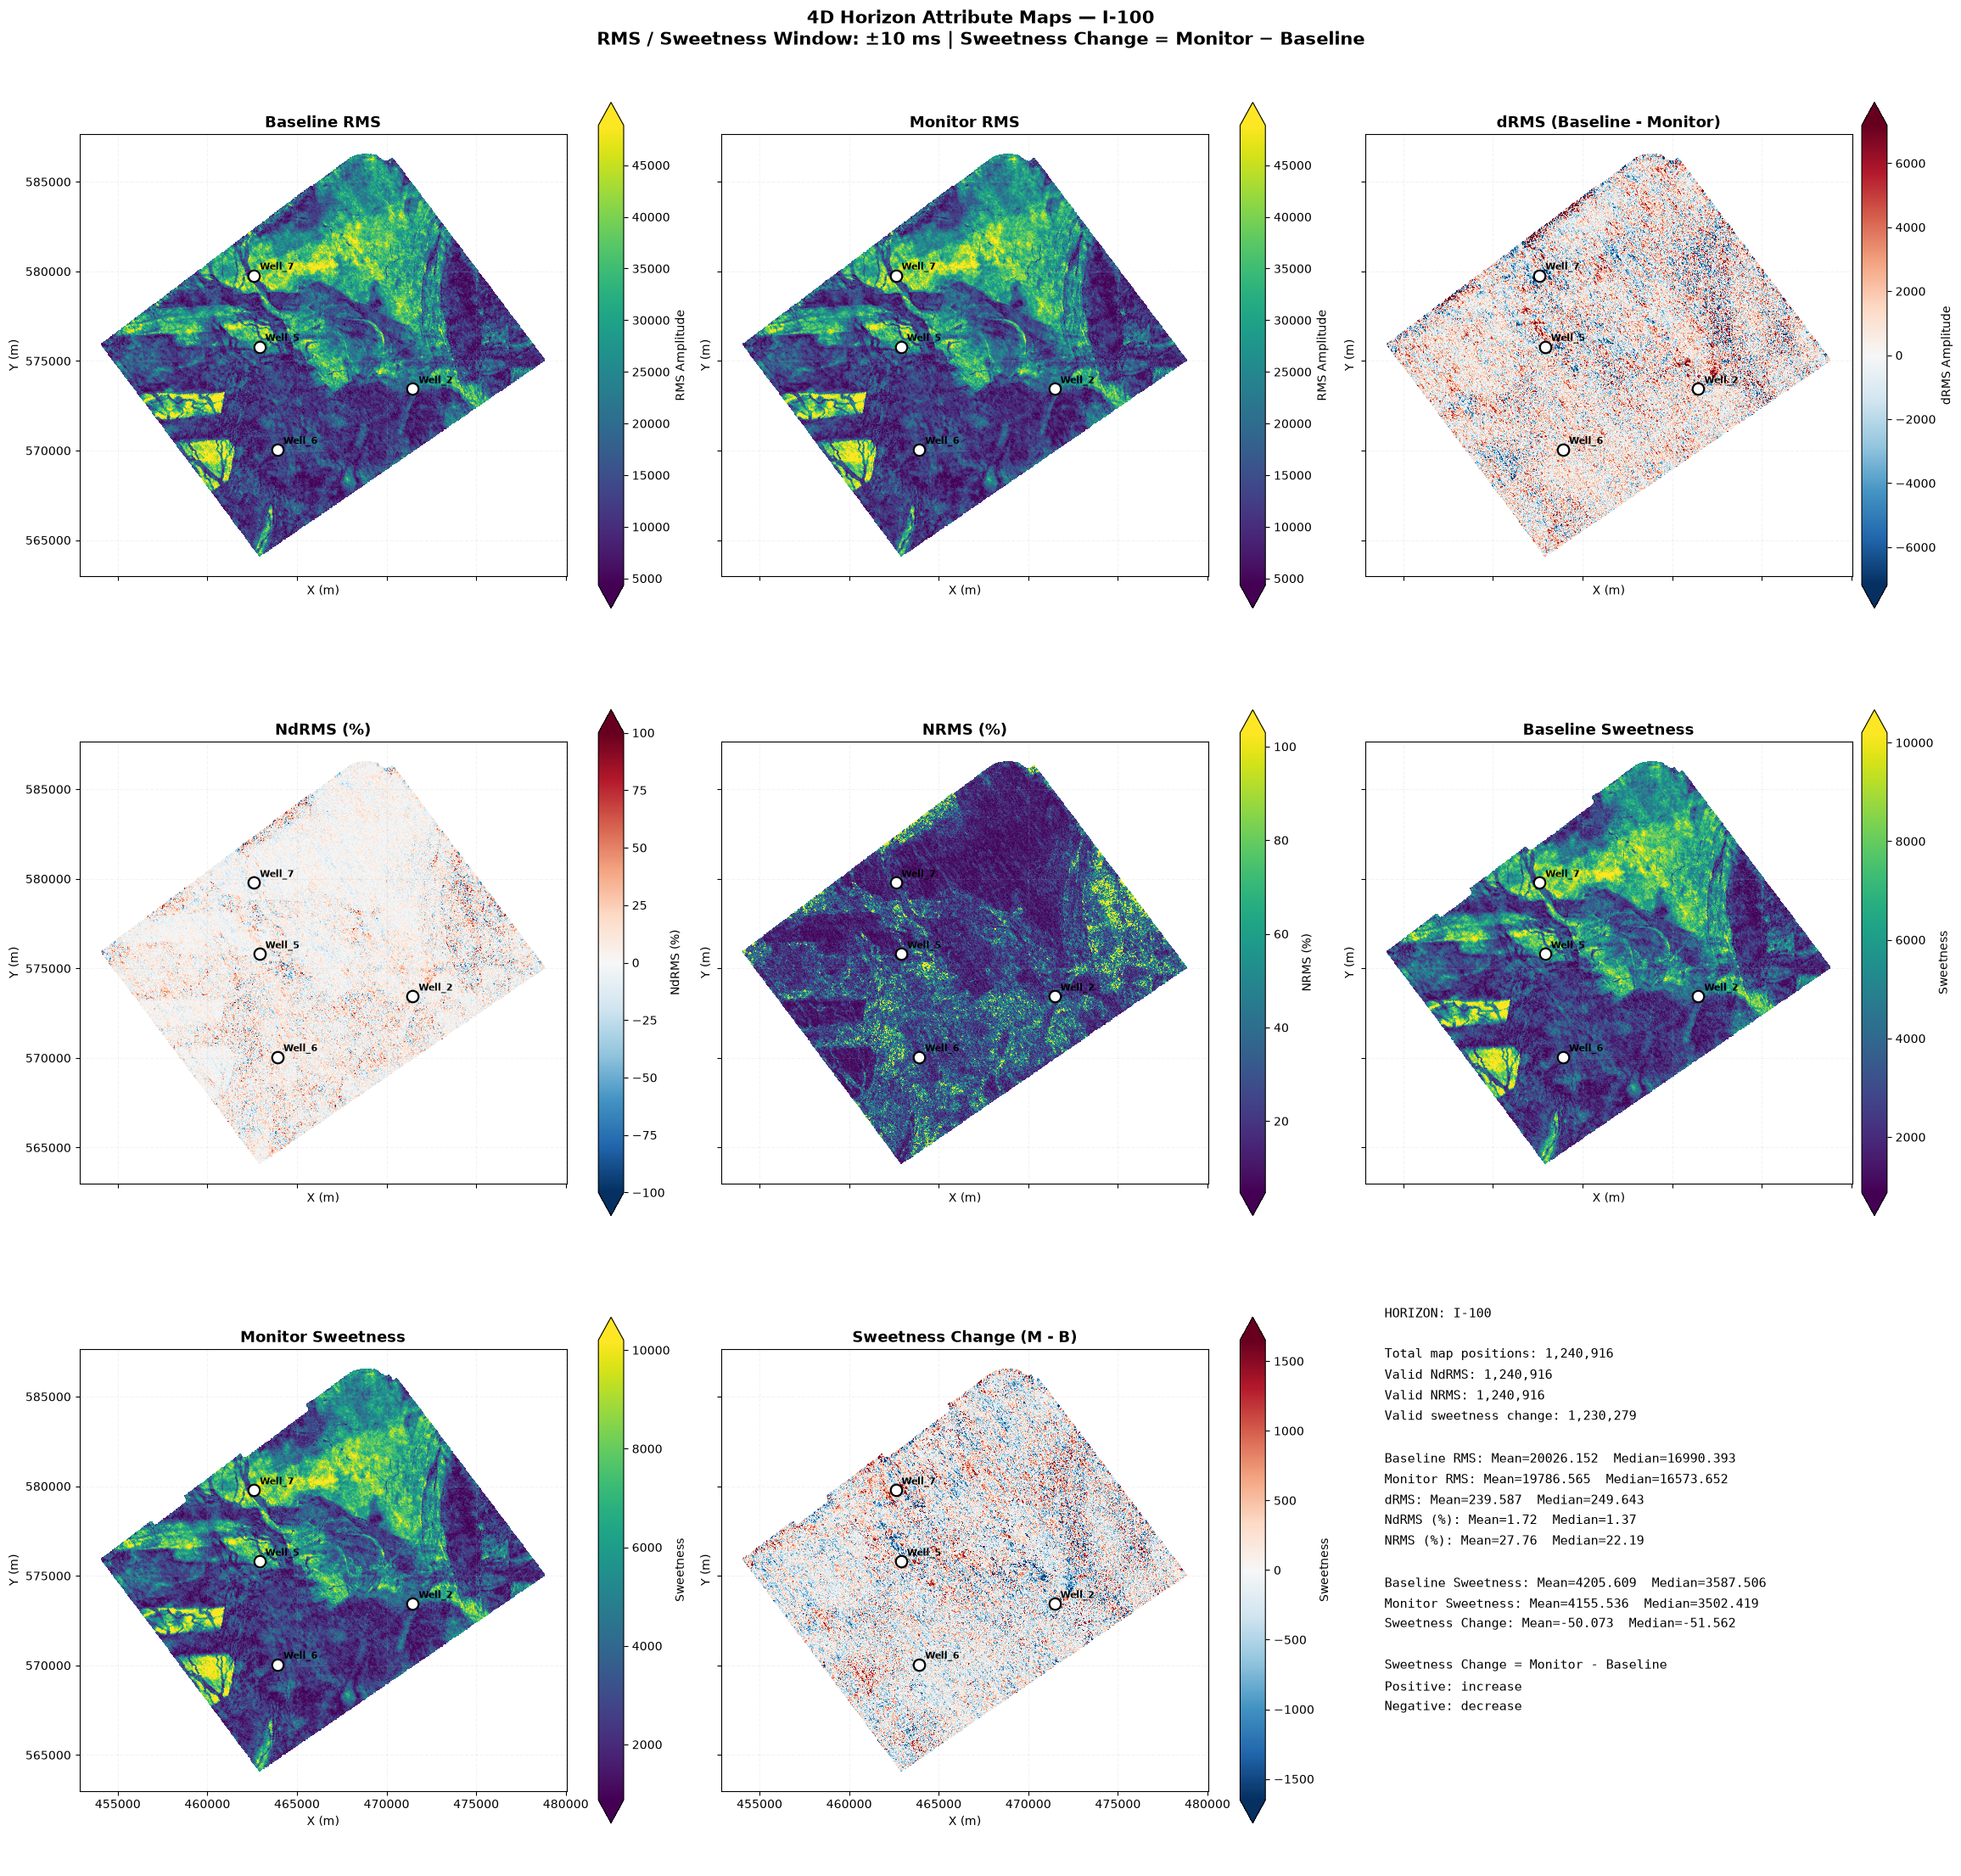

Horizon: I-100 | Map positions: 1,240,916 | Valid sweetness change: 1,230,279

Cell 28 initialized successfully.


In [40]:

# ============================================================
# CELL 11 — INTERACTIVE 3x3 HORIZON ATTRIBUTE MAP VIEWER
#
# 1. Baseline RMS
# 2. Monitor RMS
# 3. dRMS (Baseline - Monitor)
# 4. NdRMS (%)
# 5. Baseline Sweetness
# 6. Monitor Sweetness
# 7. Sweetness Change (Monitor - Baseline)
# 8. Horizon statistics
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from pathlib import Path
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display, clear_output

# ============================================================
# 1. SETTINGS
# ============================================================

BASE_DIR = Path(
    "/home/apgce_team_08/Autopick_Horizon"
)

RMS_DIR = BASE_DIR / "4D_RMS_NRMS_3"
SWEETNESS_DIR = BASE_DIR / "Sweetness"

SAVE_DIR = RMS_DIR / "Maps_3x3"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

FIGSIZE = (23, 22)
MAX_DISPLAY_POINTS = 250000
SAVE_DPI = 180

COMMON_BASE_MON_SCALE = True
ATTR_SHOW_WELLS_DEFAULT = True # EDIT HERE

# ============================================================
# 2. ATTRIBUTE CONFIGURATION
# ============================================================

ATTRIBUTES = [
    ("RMS_Baseline", "Baseline RMS", "viridis"),
    ("RMS_Monitor", "Monitor RMS", "viridis"),
    ("dRMS", "dRMS (Baseline - Monitor)", "RdBu_r"),
    ("NdRMS_pct", "NdRMS (%)", "RdBu_r"),
    ("NRMS", "NRMS (%)", "viridis"),
    ("Sweetness_Baseline", "Baseline Sweetness", "viridis"),
    ("Sweetness_Monitor", "Monitor Sweetness", "viridis"),
    ("Sweetness_Difference", "Sweetness Change (M - B)", "RdBu_r")
]

# ============================================================
# 3. DISCOVER HORIZON FILES
# ============================================================

RMS_SUFFIX = "_4D_RMS_NRMS.txt"
SWEET_SUFFIX = "_Sweetness.txt"

rms_files = {
    p.name[:-len(RMS_SUFFIX)]: p
    for p in RMS_DIR.glob(f"*{RMS_SUFFIX}")
}

sweet_files = {
    p.name[:-len(SWEET_SUFFIX)]: p
    for p in SWEETNESS_DIR.glob(f"*{SWEET_SUFFIX}")
}

horizon_names = sorted(
    set(rms_files) & set(sweet_files)
)

if not horizon_names:
    raise FileNotFoundError(
        "No matching RMS and Sweetness files. "
        "Run Cells 9 and 10A first."
    )

print(f"Available horizons: {len(horizon_names)}")

# ============================================================
# 4. LOAD AND MERGE DATA
# ============================================================

def load_horizon_attributes(name):

    rms = pd.read_csv(
        rms_files[name], sep="\t"
    )

    sweet = pd.read_csv(
        sweet_files[name], sep="\t"
    )

    rms_columns = [
        "X", "Y", "Inline", "Crossline", "TWT",
        "RMS_Baseline", "RMS_Monitor",
        "dRMS", "NdRMS_pct", "NRMS"
    ]

    sweet_columns = [
        "Inline", "Crossline",
        "Sweetness_Baseline",
        "Sweetness_Monitor",
        "Sweetness_Difference"
    ]

    for label, df, columns in [
        ("RMS", rms, rms_columns),
        ("Sweetness", sweet, sweet_columns)
    ]:

        missing = [
            c for c in columns if c not in df.columns
        ]

        if missing:
            raise ValueError(
                f"{label} missing columns: {missing}"
            )

        for col in columns:
            df[col] = pd.to_numeric(
                df[col], errors="coerce"
            )

        if df.duplicated(
            ["Inline", "Crossline"]
        ).any():
            raise ValueError(
                f"Duplicate grid positions in {label}: {name}"
            )

    df = rms.merge(
        sweet[sweet_columns],
        on=["Inline", "Crossline"],
        how="left",
        validate="one_to_one"
    )

    df = df.loc[
        np.isfinite(df["X"])
        & np.isfinite(df["Y"])
    ].copy()

    if df.empty:
        raise ValueError("No valid map coordinates.")

    return df

# ============================================================
# 5. WIDGETS
# ============================================================

horizon_dropdown = widgets.Dropdown(
    options=horizon_names,
    value=horizon_names[0],
    description="Horizon:",
    style={"description_width": "80px"},
    layout=widgets.Layout(width="550px")
)

colour_controls = {}

for column, title, cmap in ATTRIBUTES:

    colour_controls[column] = {
        "min": widgets.FloatText(
            value=0.0,
            description="Min:",
            style={"description_width": "35px"},
            layout=widgets.Layout(width="170px")
        ),
        "max": widgets.FloatText(
            value=100.0 if column in ("NdRMS_pct", "NRMS") else 1.0,
            description="Max:",
            style={"description_width": "35px"},
            layout=widgets.Layout(width="170px")
        )
    }

attr_show_wells = widgets.Checkbox(value=ATTR_SHOW_WELLS_DEFAULT,description="Show wells")
point_size_slider = widgets.FloatSlider(
    value=2.0,
    min=0.5,
    max=10.0,
    step=0.5,
    description="Point size:",
    continuous_update=False,
    layout=widgets.Layout(width="350px")
)

auto_scale_button = widgets.Button(
    description="Auto Scale All",
    button_style="info",
    icon="sliders"
)

update_button = widgets.Button(
    description="Update Maps",
    button_style="primary",
    icon="refresh"
)

save_button = widgets.Button(
    description="Save 3x3 PNG",
    button_style="success",
    icon="save"
)

map_output = widgets.Output()

# ============================================================
# 6. AUTOMATIC COLOUR SCALING
# ============================================================

def robust_limits(values):

    values = np.asarray(
        values, dtype=np.float64
    )

    values = values[np.isfinite(values)]

    if not values.size:
        return 0.0, 1.0

    vmin = float(np.percentile(values, 1))
    vmax = float(np.percentile(values, 99))

    if vmax <= vmin:
        vmax = vmin + max(abs(vmin) * 0.01, 1e-6)

    return vmin, vmax


def auto_scale_limits(name):

    df = load_horizon_attributes(name)

    limits = {}

    for column, title, cmap in ATTRIBUTES:

        if column == "NdRMS_pct":
            limits[column] = (-100.0, 100.0)

        elif column in ("Sweetness_Difference", "dRMS"):

            values = df[column].to_numpy()
            values = values[np.isfinite(values)]

            if values.size:
                maximum = float(
                    np.percentile(np.abs(values), 99)
                )
                maximum = max(maximum, 1e-6)
            else:
                maximum = 1.0

            # Symmetric scale centred on zero
            limits[column] = (-maximum, maximum)

        else:
            limits[column] = robust_limits(
                df[column].to_numpy()
            )

    if COMMON_BASE_MON_SCALE:

        for base_col, monitor_col in [
            ("RMS_Baseline", "RMS_Monitor"),
            ("Sweetness_Baseline", "Sweetness_Monitor")
        ]:

            combined = np.concatenate([
                df[base_col].to_numpy(),
                df[monitor_col].to_numpy()
            ])

            shared = robust_limits(combined)

            limits[base_col] = shared
            limits[monitor_col] = shared

    for column, (vmin, vmax) in limits.items():

        colour_controls[column]["min"].value = vmin
        colour_controls[column]["max"].value = vmax

# ============================================================
# 7. CREATE SEVEN MAPS + STATISTICS PANEL
# ============================================================

def create_4d_maps(name):

    df = load_horizon_attributes(name)

    if len(df) > MAX_DISPLAY_POINTS:

        indices = np.linspace(
            0,
            len(df) - 1,
            MAX_DISPLAY_POINTS
        ).astype(int)

        plot_df = df.iloc[indices]

    else:
        plot_df = df

    fig, axes = plt.subplots(
        3, 3,
        figsize=FIGSIZE,
        sharex=True,
        sharey=True,
        constrained_layout=True
    )

    x = plot_df["X"].to_numpy()
    y = plot_df["Y"].to_numpy()

    for ax, (column, title, cmap) in zip(
        axes.flat[:8], ATTRIBUTES
    ):

        vmin = float(
            colour_controls[column]["min"].value
        )

        vmax = float(
            colour_controls[column]["max"].value
        )

        if (
            not np.isfinite(vmin)
            or not np.isfinite(vmax)
            or vmin >= vmax
        ):
            plt.close(fig)
            raise ValueError(
                f"{title}: invalid Min/Max values."
            )

        z = plot_df[column].to_numpy()
        valid = np.isfinite(z)

        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.set_aspect("equal", adjustable="box")
        ax.ticklabel_format(style="plain", useOffset=False)
        ax.grid(alpha=0.15, linestyle="--")

        if not np.any(valid):
            ax.text(
                0.5, 0.5,
                "No valid attribute values",
                transform=ax.transAxes,
                ha="center",
                va="center"
            )
            continue

        # Use zero-centred diverging colours for
        # Sweetness Change when Min < 0 < Max.
        if (
            column in ("Sweetness_Difference", "dRMS", "NdRMS_pct")
            and vmin < 0 < vmax
        ):

            norm = TwoSlopeNorm(
                vmin=vmin,
                vcenter=0.0,
                vmax=vmax
            )

            sc = ax.scatter(
                x[valid], y[valid],
                c=z[valid],
                cmap=cmap,
                norm=norm,
                s=point_size_slider.value,
                marker="s",
                linewidths=0,
                rasterized=True
            )

        else:

            sc = ax.scatter(
                x[valid], y[valid],
                c=z[valid],
                cmap=cmap,
                vmin=vmin,
                vmax=vmax,
                s=point_size_slider.value,
                marker="s",
                linewidths=0,
                rasterized=True
            )

        cb = fig.colorbar(
            sc,
            ax=ax,
            shrink=0.85,
            pad=0.02,
            extend="both"
        )

        if column == "NRMS":
            label = "NRMS (%)"
        elif column == "NdRMS_pct":
            label = "NdRMS (%)"
        elif "Sweetness" in column:
            label = "Sweetness"
        elif column == "dRMS":
            label = "dRMS Amplitude"
        else:
            label = "RMS Amplitude"

        cb.set_label(label)

    # ----------------------------------------
    # Ninth panel: horizon statistics
    # ----------------------------------------

    stats_ax = axes.flat[8]
    stats_ax.axis("off")

    def stats_line(column, label, decimals=3):

        values = df[column].to_numpy()
        values = values[np.isfinite(values)]

        if not values.size:
            return f"{label}: N/A"

        return (
            f"{label}: "
            f"Mean={np.mean(values):.{decimals}f}  "
            f"Median={np.median(values):.{decimals}f}"
        )

    statistics = [
        f"HORIZON: {name}",
        "",
        f"Total map positions: {len(df):,}",
        f"Valid NdRMS: {df['NdRMS_pct'].notna().sum():,}",
        f"Valid NRMS: {df['NRMS'].notna().sum():,}",
        f"Valid sweetness change: "
        f"{df['Sweetness_Difference'].notna().sum():,}",
        "",
        stats_line("RMS_Baseline", "Baseline RMS"),
        stats_line("RMS_Monitor", "Monitor RMS"),
        stats_line("dRMS", "dRMS"),
        stats_line("NdRMS_pct", "NdRMS (%)", 2),
        stats_line("NRMS", "NRMS (%)", 2),
        "",
        stats_line("Sweetness_Baseline", "Baseline Sweetness"),
        stats_line("Sweetness_Monitor", "Monitor Sweetness"),
        stats_line("Sweetness_Difference", "Sweetness Change"),
        "",
        "Sweetness Change = Monitor - Baseline",
        "Positive: increase",
        "Negative: decrease"
    ]

    stats_ax.text(
        0.04, 0.95,
        "\n".join(statistics),
        transform=stats_ax.transAxes,
        ha="left",
        va="top",
        fontsize=11,
        family="monospace",
        linespacing=1.6
    )

    fig.suptitle(
        f"4D Horizon Attribute Maps — {name}\n"
        "RMS / Sweetness Window: ±10 ms | "
        "Sweetness Change = Monitor − Baseline",
        fontsize=15,
        fontweight="bold"
    )

    if attr_show_wells.value:
        for _ax in axes.flat[:len(ATTRIBUTES)]:
            overlay_well_map(_ax,name,mode="XY")
    return fig, df

# ============================================================
# 8. UPDATE MAPS
# ============================================================

def update_maps(button=None):

    with map_output:

        clear_output(wait=True)

        try:
            name = horizon_dropdown.value

            fig, df = create_4d_maps(name)

            display(fig)
            plt.close(fig)

            print(
                f"Horizon: {name} | "
                f"Map positions: {len(df):,} | "
                f"Valid sweetness change: "
                f"{df['Sweetness_Difference'].notna().sum():,}"
            )

        except Exception as e:
            print(f"Map error: {e}")

# ============================================================
# 9. SAVE PNG
# ============================================================

def save_maps(button=None):

    try:
        name = horizon_dropdown.value

        fig, df = create_4d_maps(name)

        safe_name = re.sub(
            r'[<>:"/\\|?*\x00-\x1f]',
            "_", name
        ).strip(" .")

        output_file = (
            SAVE_DIR /
            f"{safe_name}_4D_Maps_3x3.png"
        )

        fig.savefig(
            output_file,
            dpi=SAVE_DPI,
            bbox_inches="tight"
        )

        plt.close(fig)

        with map_output:
            print(f"Saved: {output_file}")

    except Exception as e:
        with map_output:
            print(f"Save error: {e}")

# ============================================================
# 10. CALLBACKS
# ============================================================

def on_auto_scale(button=None):

    try:
        auto_scale_limits(horizon_dropdown.value)
        update_maps()

    except Exception as e:
        with map_output:
            clear_output(wait=True)
            print(f"Auto-scale error: {e}")


def on_horizon_change(change):
    on_auto_scale()


auto_scale_button.on_click(on_auto_scale)
update_button.on_click(update_maps)
save_button.on_click(save_maps)

horizon_dropdown.observe(
    on_horizon_change,
    names="value"
)

# ============================================================
# 11. DISPLAY INDEPENDENT COLOUR CONTROLS
# ============================================================

control_panels = []

for column, title, cmap in ATTRIBUTES:

    panel = widgets.VBox([
        widgets.HTML(f"<b>{title} — Colour Limits</b>"),

        widgets.HBox([
            colour_controls[column]["min"],
            colour_controls[column]["max"]
        ])
    ], layout=widgets.Layout(
        border="1px solid #888",
        padding="10px",
        width="48%"
    ))

    control_panels.append(panel)

colour_control_grid = widgets.VBox([
    widgets.HBox(control_panels[0:2]),
    widgets.HBox(control_panels[2:4]),
    widgets.HBox(control_panels[4:6]),
    widgets.HBox(control_panels[6:7])
])

controls = widgets.VBox([
    widgets.HTML(
        "<h3>Interactive 4D Horizon Attribute Viewer</h3>"
    ),
    horizon_dropdown,
    widgets.HTML(
        "<b>Independent Colour Scale Controls</b>"
    ),
    colour_control_grid,
    point_size_slider,
    attr_show_wells,
    widgets.HBox([
        auto_scale_button,
        update_button,
        save_button
    ])
])

# ============================================================
# 12. INITIALIZE
# ============================================================

display(controls)
display(map_output)

auto_scale_limits(horizon_dropdown.value)
update_maps()

print("\nCell 28 initialized successfully.")

In [39]:
# CELL 29 — Platform-constrained, spatially denoised 4D response maps
# Run after per-horizon RMS/NRMS/dRMS/NdRMS extraction.
# No seismic volume needed. GPU is optional; CPU fallback is automatic.
# Interpretation warning: these are uncalibrated amplitude-response proxies.
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Circle
from scipy.ndimage import gaussian_filter as cpu_gaussian_filter, label as cpu_label
from IPython.display import display, clear_output
import ipywidgets as widgets

# ========================= EDIT PARAMETERS HERE =========================
RMS_INPUT_DIR = Path('/home/apgce_team_08/Autopick_Horizon/4D_RMS_NRMS_3')
PLATFORM_CSV = Path('/home/apgce_team_08/Platform.csv')  # copy uploaded CSV here
MAP_OUTPUT_DIR = RMS_INPUT_DIR / '4D_Platform_Constrained_Maps'
PLATFORM_RADIUS_M = 3000.0          # EDIT: change detection within this distance (metres)
NDRMS_THRESHOLD_PCT = 15.0         # EDIT: signed RMS-change magnitude threshold
NRMS_MIN_PCT = 15.0                # EDIT: minimum NRMS for significant change
HARDENING_WHEN_NDRMS_POSITIVE = True # EDIT: reverse after calibration if needed
DENOISE_SIGMA_BINS = 3.0           # EDIT: Gaussian low-pass sigma in IL/XL bins; 0 disables
MIN_CLUSTER_BINS = 40              # EDIT: remove connected change patches smaller than this
CONNECTIVITY = 8                   # EDIT: 4 or 8 neighbour connectivity
SMOOTH_NRMS_TOO = True             # EDIT: smooth NRMS in addition to NdRMS
BACKEND = 'auto'                   # EDIT: 'auto', 'gpu', 'cpu'
MAP_AXIS_MODE = 'XY'
CLASS_SHOW_WELLS_DEFAULT = True # EDIT HERE
PLATFORM_CONSTRAINT_DEFAULT = True  # EDIT: initial dropdown selection               # EDIT: 'XY' or 'ILXL'
MAX_PLOT_POINTS = 300000
POINT_SIZE = 2.0
MAP_DPI = 180
SAVE_ALL_MAPS = True
SHOW_PLATFORM_CIRCLES = True
# =======================================================================

if PLATFORM_RADIUS_M <= 0 or DENOISE_SIGMA_BINS < 0 or MIN_CLUSTER_BINS < 1:
    raise ValueError('Radius must be positive; sigma >= 0; minimum cluster size >= 1')
if CONNECTIVITY not in (4,8): raise ValueError('CONNECTIVITY must be 4 or 8')
if BACKEND not in ('auto','cpu','gpu'): raise ValueError('BACKEND must be auto, cpu or gpu')
if MAP_AXIS_MODE not in ('XY','ILXL'): raise ValueError('MAP_AXIS_MODE must be XY or ILXL')
if not PLATFORM_CSV.is_file():
    raise FileNotFoundError(f'Platform file missing: {PLATFORM_CSV}. Upload/copy Platform.csv to this location.')
platforms = pd.read_csv(PLATFORM_CSV,encoding='utf-8-sig')
platforms.columns = platforms.columns.str.strip()
for col in ('Platform','X(m)','Y(m)'):
    if col not in platforms: raise ValueError(f'Platform CSV missing column: {col}')
platforms['X(m)'] = pd.to_numeric(platforms['X(m)'],errors='raise')
platforms['Y(m)'] = pd.to_numeric(platforms['Y(m)'],errors='raise')
if platforms[['X(m)','Y(m)']].isna().any().any(): raise ValueError('Platform XY contains NaN')
px = platforms['X(m)'].to_numpy(float)
py = platforms['Y(m)'].to_numpy(float)
MAP_OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
SUFFIX = '_4D_RMS_NRMS.txt'
files = {p.name[:-len(SUFFIX)]:p for p in RMS_INPUT_DIR.glob('*'+SUFFIX)}
if not files: raise FileNotFoundError(f'No *{SUFFIX} files in {RMS_INPUT_DIR}')

# Use GPU for spatial filtering when CuPy is available; CPU handles connected components.
xp=np; nd_gaussian=cpu_gaussian_filter
if BACKEND != 'cpu':
    try:
        import cupy as cp
        from cupyx.scipy.ndimage import gaussian_filter as gpu_gaussian_filter
        if cp.cuda.runtime.getDeviceCount() > 0:
            xp=cp; nd_gaussian=gpu_gaussian_filter
    except (ImportError, RuntimeError, OSError) as exc:
        if BACKEND=='gpu': raise RuntimeError('GPU requested but CuPy unavailable') from exc
if BACKEND=='gpu' and xp is np: raise RuntimeError('GPU requested but no CUDA GPU available')
print('Filtering backend:', 'CuPy GPU' if xp is not np else 'NumPy/SciPy CPU')
print('Platforms:',len(platforms),'| Radius:',PLATFORM_RADIUS_M,'m')

LABELS={-1:'No data',0:'Unswept',1:'Hardening',2:'Softening'}
COLORS=['#A3A3A3','#2166AC','#D6604D']
CMAP=ListedColormap(COLORS)
NORM=BoundaryNorm([-0.5,0.5,1.5,2.5],CMAP.N)
STRUCTURE=np.ones((3,3),np.uint8) if CONNECTIVITY==8 else np.array([[0,1,0],[1,1,1],[0,1,0]],np.uint8)

def _masked_lowpass(grid,sigma):
    """Gaussian low-pass without spreading NaN/no-data into valid samples."""
    if sigma <= 0: return grid.copy()
    arr=xp.asarray(grid,dtype=xp.float32)
    good=xp.isfinite(arr)
    num=nd_gaussian(xp.where(good,arr,0).astype(xp.float32),sigma,mode='constant')
    den=nd_gaussian(good.astype(xp.float32),sigma,mode='constant')
    result=xp.where(good & (den>1e-6),num/xp.maximum(den,1e-6),xp.nan)
    return cp.asnumpy(result) if xp is not np else np.asarray(result)

def _remove_small_patches(codes,valid_grid):
    # Filter hardening and softening independently; small patches become Unswept.
    for cls in (1,2):
        components,n=cpu_label(codes==cls,structure=STRUCTURE)
        if n:
            sizes=np.bincount(components.ravel())
            small=(sizes<MIN_CLUSTER_BINS)
            small[0]=False
            codes[small[components]]=0
    codes[~valid_grid]=-1
    return codes

def load_and_classify(horizon, constrain_by_platform=True):
    df=pd.read_csv(files[horizon],sep='\t')
    required=['Inline','Crossline','X','Y','NdRMS_pct','NRMS']
    missing=set(required)-set(df.columns)
    if missing: raise ValueError(f'{horizon}: missing {sorted(missing)}')
    for c in required: df[c]=pd.to_numeric(df[c],errors='coerce')
    if df.duplicated(['Inline','Crossline']).any():
        raise ValueError(f'{horizon}: duplicate Inline/Crossline bins')
    # Spatial filtering uses the actual IL/XL grid, never file row order.
    il_vals=np.sort(df.Inline.dropna().unique())
    xl_vals=np.sort(df.Crossline.dropna().unique())
    il_idx=pd.Index(il_vals).get_indexer(df.Inline)
    xl_idx=pd.Index(xl_vals).get_indexer(df.Crossline)
    grid_row_ok=(il_idx>=0)&(xl_idx>=0)
    shape=(len(il_vals),len(xl_vals))
    nd=np.full(shape,np.nan,np.float32)
    nr=np.full(shape,np.nan,np.float32)
    nd_raw=df.NdRMS_pct.to_numpy(float)
    nr_raw=df.NRMS.to_numpy(float)
    raw_ok=grid_row_ok&np.isfinite(nd_raw)&np.isfinite(nr_raw)
    nd[il_idx[raw_ok],xl_idx[raw_ok]]=nd_raw[raw_ok]
    nr[il_idx[raw_ok],xl_idx[raw_ok]]=nr_raw[raw_ok]
    nd_sm=_masked_lowpass(nd,DENOISE_SIGMA_BINS)
    nr_sm=_masked_lowpass(nr,DENOISE_SIGMA_BINS) if SMOOTH_NRMS_TOO else nr
    valid=np.isfinite(nd)&np.isfinite(nr)
    # Retain valid original footprint, not extrapolated no-data.
    changed=valid & (np.abs(nd_sm)>=NDRMS_THRESHOLD_PCT) & (nr_sm>=NRMS_MIN_PCT)
    codes=np.full(shape,-1,np.int8)
    codes[valid]=0
    pos=changed&(nd_sm>0)
    neg=changed&(nd_sm<0)
    codes[pos]=1 if HARDENING_WHEN_NDRMS_POSITIVE else 2
    codes[neg]=2 if HARDENING_WHEN_NDRMS_POSITIVE else 1
    codes=_remove_small_patches(codes,valid)
    # HARD spatial gate: only change classes inside 1 km of at least one platform.
    # This is based on true metric X/Y coordinates, independent of map axis mode.
    xx=df.X.to_numpy(float); yy=df.Y.to_numpy(float)
    near=np.zeros(len(df),bool)
    min_dist2=np.full(len(df),np.inf,float)
    for x0,y0 in zip(px,py):
        d2=(xx-x0)**2+(yy-y0)**2
        min_dist2=np.minimum(min_dist2,d2)
    near=np.isfinite(min_dist2)&(min_dist2<=PLATFORM_RADIUS_M**2)
    row_codes=np.full(len(df),-1,np.int8)
    row_codes[grid_row_ok]=codes[il_idx[grid_row_ok],xl_idx[grid_row_ok]]
    if constrain_by_platform:
        row_codes[(row_codes>0)&~near]=0
    df['Nearest_Platform_Distance_m']=np.sqrt(min_dist2)
    df['Within_Platform_Radius']=near
    df['NdRMS_Smoothed_pct']=np.nan
    df['NRMS_Smoothed']=np.nan
    df.loc[grid_row_ok,'NdRMS_Smoothed_pct']=nd_sm[il_idx[grid_row_ok],xl_idx[grid_row_ok]]
    df.loc[grid_row_ok,'NRMS_Smoothed']=nr_sm[il_idx[grid_row_ok],xl_idx[grid_row_ok]]
    df['4D_Class_Code']=row_codes
    df['4D_Class']=pd.Categorical([LABELS[int(v)] for v in row_codes],
                                  categories=['Hardening','Softening','Unswept','No data'])
    return df

def render_horizon(horizon,save=False,show=True,constrain_by_platform=True):
    df=load_and_classify(horizon,constrain_by_platform=constrain_by_platform)
    safe=re.sub(r'[^A-Za-z0-9_.-]+','_',horizon)
    mode_tag='Constrained' if constrain_by_platform else 'Unconstrained'
    export_dir=MAP_OUTPUT_DIR / mode_tag
    if save:
        export_dir.mkdir(parents=True,exist_ok=True)
        df.to_csv(export_dir/f'{safe}_4D_Classes.csv',index=False)
    plot=df.iloc[np.linspace(0,len(df)-1,MAX_PLOT_POINTS,dtype=int)] if len(df)>MAX_PLOT_POINTS else df
    xcol,ycol,xlabel,ylabel=('X','Y','X (m)','Y (m)') if MAP_AXIS_MODE=='XY' else ('Crossline','Inline','Crossline','Inline')
    fig,ax=plt.subplots(figsize=(11,9),constrained_layout=True)
    x=plot[xcol].to_numpy(float); y=plot[ycol].to_numpy(float)
    classes=plot['4D_Class_Code'].to_numpy()
    ok=np.isfinite(x)&np.isfinite(y)&(classes>=0)
    ax.scatter(x[ok],y[ok],c=classes[ok],cmap=CMAP,norm=NORM,
               s=POINT_SIZE,marker='s',linewidths=0,rasterized=True)
    if MAP_AXIS_MODE=='XY':
        ax.set_aspect('equal',adjustable='box')
        for r in platforms.itertuples(index=False):
            x0=float(getattr(r,'_1',r[1])); y0=float(getattr(r,'_2',r[2]))
            ax.plot(x0,y0,marker='^',color='black',markersize=9,zorder=10)
            ax.annotate(str(r[0]),(x0,y0),xytext=(5,5),textcoords='offset points',fontsize=9)
            if SHOW_PLATFORM_CIRCLES:
                ax.add_patch(Circle((x0,y0),PLATFORM_RADIUS_M,fill=False,
                                    color='black',linestyle='--',linewidth=1.2,alpha=.8))
    if class_show_wells.value:
        overlay_well_map(ax,horizon,mode=MAP_AXIS_MODE)
    ax.set(xlabel=xlabel,ylabel=ylabel,title=f'{horizon} — {mode_tag} 4D response')
    ax.grid(alpha=.12)
    ax.legend(handles=[Patch(color=COLORS[i],label=LABELS[i]) for i in range(3)],loc='best')
    counts=df['4D_Class_Code'].value_counts()
    summary={LABELS[i]:int(counts.get(i,0)) for i in (-1,0,1,2)}
    fig.text(.02,.01,f'Platform constraint: {mode_tag} ({PLATFORM_RADIUS_M:g} m) | '
             f'NdRMS: ±{NDRMS_THRESHOLD_PCT:g}% | NRMS ≥ {NRMS_MIN_PCT:g}% | '
             f'Gaussian σ={DENOISE_SIGMA_BINS:g} bins | Min patch={MIN_CLUSTER_BINS} bins',fontsize=9)
    if save: fig.savefig(export_dir/f'{safe}_4D_Three_Class.png',dpi=MAP_DPI,bbox_inches='tight')
    if show: plt.show()
    plt.close(fig)
    print(horizon,summary)
    return summary

selector=widgets.Dropdown(options=sorted(files),description='Horizon:',layout=widgets.Layout(width='450px'))
axis_selector=widgets.Dropdown(options=[('X / Y coordinates','XY'),('Inline / Crossline','ILXL')],
                              value=MAP_AXIS_MODE,description='Axes:')
constraint_selector=widgets.Dropdown(
    options=[('Constrained — within platform radius',True),
             ('Unconstrained — entire seismic survey',False)],
    value=PLATFORM_CONSTRAINT_DEFAULT,description='Platform:',
    layout=widgets.Layout(width='420px'))
class_show_wells=widgets.Checkbox(value=CLASS_SHOW_WELLS_DEFAULT,description='Show wells')
show_button=widgets.Button(description='Display map',button_style='primary')
export_button=widgets.Button(description='Export all horizons',button_style='success')
out=widgets.Output()
def _show(_=None):
    global MAP_AXIS_MODE
    MAP_AXIS_MODE=axis_selector.value
    with out:
        clear_output(wait=True)
        render_horizon(selector.value,save=False,show=True,
                       constrain_by_platform=constraint_selector.value)
def _export(_):
    global MAP_AXIS_MODE
    MAP_AXIS_MODE=axis_selector.value
    with out:
        clear_output(wait=True)
        summaries=[]
        for idx,h in enumerate(sorted(files),1):
            summary=render_horizon(h,save=True,show=False,
                                   constrain_by_platform=constraint_selector.value)
            summaries.append({'Horizon':h,**summary})
            print(f'Exported {idx}/{len(files)}')
        mode_tag='Constrained' if constraint_selector.value else 'Unconstrained'
        export_dir=MAP_OUTPUT_DIR / mode_tag
        pd.DataFrame(summaries).to_csv(export_dir/'4D_Class_Summary.csv',index=False)
        print('All maps exported to',export_dir)
constraint_selector.observe(_show,names="value")
class_show_wells.observe(_show,names="value")
show_button.on_click(_show)
export_button.on_click(_export)
display(widgets.HBox([selector,axis_selector]),constraint_selector,class_show_wells,
        widgets.HBox([show_button,export_button]),out)
_show()

Filtering backend: CuPy GPU
Platforms: 3 | Radius: 3000.0 m


Dropdown(description='Platform:', layout=Layout(width='420px'), options=(('Constrained — within platform radiu…

Checkbox(value=True, description='Show wells')

Output()